**Требования к отчётам**

1. Ответы оформляются в соответствующих полях после заданий;
2. **Описание:** какие функции оптимизируются; как генерируются данные или какие датасеты используются (размер $m \times n$, плотность или разреженность матрицы); на каком компьютере (CPU, RAM); какие методы и с какими параметрами запускались.
3. **Результаты:** графики, таблицы и т. д.
4. **Выводы:** какая зависимость наблюдается, почему, и как это согласуется с теорией из лекций.

**Важно:**
* Каждый график должен быть прокомментирован в тексте: что на нём изображено и какие выводы из него следуют.
* Оси подписаны; если на графике несколько кривых, есть легенда; линии достаточно толстые, чтобы их было хорошо видно.

# Лабораторная работа 1. Методы градиентного спуска и метод Ньютона

**Срок сдачи:** 7 ноября 23:59

**Что нужно сдать**
1. Этот ноутбук с реализованными функциями и кодом всех экспериментов. Все результаты должны воспроизводиться: если используется случайность, зафиксируйте `seed`.

Работа выполняется самостоятельно.

## План выполнения

1. Реализовать линейный поиск (`LineSearchTool.line_search`) и градиентный спуск (`gradient_descent`).
2. Вывести функцию, градиент и гессиан для определенных ниже **двух функций потерь** в матрично-векторной форме, с учётом L2-регуляризатора.
3. Реализовать функции потерь и общий оракул (п. 2.4)`LinearModelL2Oracle` (с поддержкой `np.ndarray` и `scipy.sparse.csr_matrix`).
4. Реализовать оракул  невыпуклой 2D-функции (градиент и гессиан).
5. Реализовать разностные производные (`grad_finite_diff`, `hess_finite_diff`) и с их помощью проверить все ваши оракулы.
6. Реализовать метод Ньютона (`newton`).
7. Прогнать проверочные тесты (раздел «Проверка реализации»).
8. Провести эксперименты 1–7.

In [1]:
import os
import time
import copy
import bz2
import shutil
import urllib.request
from collections import defaultdict
from pathlib import Path

import numpy as np
from numpy.linalg import LinAlgError
import scipy
import scipy.sparse
import scipy.sparse.linalg
import scipy.linalg
import scipy.optimize
from scipy.special import expit
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from sklearn.datasets import load_svmlight_file
from sklearn.preprocessing import StandardScaler

SEED = 42
np.random.seed(SEED)

print('Запускал все на Kaggle: 4 vCPU, 31 GB RAM, Python 3.13')

RUN = {1, 2, 3, 4, 5, 6, 7}

Запускал все на Kaggle: 4 vCPU, 31 GB RAM, Python 3.13


# 1. Алгоритмы

## 1.1 Методы спуска: общая схема

Рассматривается задача гладкой безусловной оптимизации $\min_{x \in \mathbb{R}^n} f(x)$. Методы спуска строят последовательность
$$x_{k+1} = x_k + \alpha_k d_k,$$
где $\alpha_k \ge 0$ — длина шага, а $d_k$ — направление спуска, т. е. $\langle \nabla f(x_k), d_k \rangle < 0$.

**Алгоритм 1. Общая схема метода спуска**

**Вход:** начальная точка $x_0$; максимальное число итераций $K$.

1. **for** $k \leftarrow 0$ **to** $K$ **do**
2. &emsp; **(Вызов оракула)** Вычислить $f(x_k)$, $\nabla f(x_k)$ и пр.
3. &emsp; **(Критерий остановки)** Если выполнен критерий остановки, то выход.
4. &emsp; **(Вычисление направления)** Вычислить направление спуска $d_k$.
5. &emsp; **(Линейный поиск)** Найти подходящую длину шага $\alpha_k$.
6. &emsp; **(Обновление)** $x_{k+1} \leftarrow x_k + \alpha_k d_k$.
7. **end for**

**Выход:** последняя вычисленная точка $x_k$.

## 1.2 Критерий остановки

Если оптимальное значение $f^*$ неизвестно, используют критерий по норме градиента $\|\nabla f(x_k)\|_2^2 < \tilde\varepsilon$. Квадрат здесь ставят потому, что для «хороших» функций (например, сильно выпуклых с липшицевым градиентом) невязка $f(x_k) - f^*$ имеет тот же порядок, что и $\|\nabla f(x_k)\|_2^2$, а не $\|\nabla f(x_k)\|_2$: если $\|\nabla f(x_k)\|_2 \sim 10^{-5}$, то $f(x_k) - f^* \sim 10^{-10}$.

Чтобы критерий не зависел от масштаба функции (не менялся при переходе от $f$ к $tf$, $t > 0$), используется относительный вариант:
$$\|\nabla f(x_k)\|_2^2 \le \varepsilon \, \|\nabla f(x_0)\|_2^2, \qquad \varepsilon \in (0, 1). \tag{1}$$

**Во всех методах этой работы используйте критерий (1).**

## 1.3 Линейный поиск

Обозначим $\phi_k(\alpha) := f(x_k + \alpha d_k)$, тогда $\phi_k'(\alpha) = \langle \nabla f(x_k + \alpha d_k), d_k \rangle$ и $\phi_k'(0) < 0$.

**Условие Армихо:** $\phi_k(\alpha) \le \phi_k(0) + c_1 \alpha \phi_k'(0)$, где $c_1 \in (0, 0.5)$.

**Алгоритм 2. Дробление шага (бэктрекинг)**

**Вход:** функция $\phi_k$, начальный шаг $\alpha_k^{(0)}$.
1. $\alpha \leftarrow \alpha_k^{(0)}$
2. **while** $\phi_k(\alpha) > \phi_k(0) + c_1 \alpha \phi_k'(0)$ **do** $\alpha \leftarrow \alpha / 2$

**Выход:** $\alpha$.

**Адаптивный** вариант запоминает шаг $\alpha_k$ с текущей итерации и на следующей начинает дробление с $\alpha_{k+1}^{(0)} := 2\alpha_k$.

**Сильные условия Вульфа:**
$$\phi_k(\alpha) \le \phi_k(0) + c_1 \alpha \phi_k'(0), \qquad |\phi_k'(\alpha)| \le c_2 |\phi_k'(0)|, \qquad 0 < c_1 < c_2 < 1.$$

Реализовывать поиск по условиям Вульфа самостоятельно не нужно: используйте [`scipy.optimize.line_search`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize_scalar.html). Иногда эта функция не сходится и возвращает `None`. В этом случае запустите бэктрекинг по условию Армихо.

Для точного одномерного поиска (методы `'Brent'` и `'Golden'`) используйте [`scipy.optimize.minimize_scalar`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize_scalar.html).

## 1.4 Градиентный спуск

$x_{k+1} = x_k - \alpha_k \nabla f(x_k)$, т. е. $d_k = -\nabla f(x_k)$; шаг $\alpha_k$ подбирается линейным поиском.

## 1.5 Метод Ньютона

$x_{k+1} = x_k - \alpha_k [\nabla^2 f(x_k)]^{-1} \nabla f(x_k)$.

Для локальной квадратичной сходимости важно использовать единичный шаг, поэтому линейный поиск всегда сначала пробует $\alpha = 1$. В зоне квадратичной сходимости единичный шаг удовлетворяет условиям Армихо/Вульфа и принимается автоматически, а вдали от решения линейный поиск его уменьшает и тем самым обеспечивает глобальную сходимость.

Направление находится из системы $\nabla^2 f(x_k)\, d_k = -\nabla f(x_k)$. Явно обращать гессиан (`np.linalg.inv`) или использовать общий решатель (`np.linalg.solve`) не нужно. Если гессиан положительно определён, используйте разложение Холецкого ([`scipy.linalg.cho_factor`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.cho_factor.html), `scipy.linalg.cho_solve`): оно, как и
метод Гаусса, работает за $O(n^3)$, но с меньшей константой. Если матрица не положительно определена, `cho_factor` выбросит `LinAlgError`; в этом случае метод должен завершиться с сообщением `'newton_direction_error'`.

In [2]:
class LineSearchTool(object):
    def __init__(self, method='Wolfe', **kwargs):
        self._method = method
        self.start_with_one = kwargs.get('start_with_one', False)
        if self._method == 'Wolfe':
            self.c1 = kwargs.get('c1', 1e-4)
            self.c2 = kwargs.get('c2', 0.9)
            self.alpha_0 = kwargs.get('alpha_0', 1.0)
        elif self._method == 'Armijo':
            self.c1 = kwargs.get('c1', 1e-4)
            self.alpha_0 = kwargs.get('alpha_0', 1.0)
        elif self._method == 'Constant':
            self.c = kwargs.get('c', 1.0)
        elif self._method in ('Brent', 'Golden'):
            self.bracket = kwargs.get('bracket', None)
            self.tol = kwargs.get('tol', 1e-4)
        else:
            raise ValueError('Неизвестный метод {}'.format(method))

    @classmethod
    def from_dict(cls, options):
        if type(options) != dict:
            raise TypeError('LineSearchTool: ожидался dict с настройками')
        return cls(**options)

    def to_dict(self):
        return self.__dict__

    def _armijo(self, oracle, x_k, d_k, alpha, phi_0, dphi_0):
        c1 = self.c1
        for _ in range(100):
            phi_alpha = oracle.func_directional(x_k, d_k, alpha)
            if phi_alpha <= phi_0 + c1 * alpha * dphi_0:
                return alpha
            alpha *= 0.5
            if alpha < 1e-16:
                break
        raise ValueError('Armijo: не удалось подобрать шаг')

    def line_search(self, oracle, x_k, d_k, previous_alpha=None):
        if self._method == 'Constant':
            return self.c

        phi_0 = oracle.func_directional(x_k, d_k, 0.0)
        dphi_0 = oracle.grad_directional(x_k, d_k, 0.0)

        if self._method == 'Armijo':
            if self.start_with_one:
                alpha = 1.0
            elif previous_alpha is not None:
                alpha = 2.0 * previous_alpha
            else:
                alpha = self.alpha_0
            return self._armijo(oracle, x_k, d_k, alpha, phi_0, dphi_0)

        if self._method == 'Wolfe':
            res = scipy.optimize.line_search(
                lambda x: oracle.func(x),
                lambda x: oracle.grad(x),
                x_k, d_k,
                c1=self.c1, c2=self.c2, maxiter=50)
            alpha = res[0] if res is not None else None
            if alpha is not None and alpha > 0:
                return alpha
            if self.start_with_one:
                alpha = 1.0
            elif previous_alpha is not None:
                alpha = 2.0 * previous_alpha
            else:
                alpha = self.alpha_0
            return self._armijo(oracle, x_k, d_k, alpha, phi_0, dphi_0)

        if self._method in ('Brent', 'Golden'):
            bracket = self.bracket
            if bracket is None:
                bracket = (0.0, 1.0)
            res = scipy.optimize.minimize_scalar(
                lambda a: oracle.func_directional(x_k, d_k, a),
                bracket=bracket,
                method='brent' if self._method == 'Brent' else 'golden',
                tol=self.tol)
            if not res.success or not np.isfinite(res.x):
                raise ValueError('Точный линейный поиск не сошёлся')
            return res.x

        raise ValueError('Неизвестный метод {}'.format(self._method))


def get_line_search_tool(line_search_options=None):
    if line_search_options:
        if isinstance(line_search_options, LineSearchTool):
            return line_search_options
        return LineSearchTool.from_dict(line_search_options)
    return LineSearchTool()


def _newton_line_search_tool(line_search_options=None):
    if line_search_options is None:
        tool = LineSearchTool()
    elif isinstance(line_search_options, LineSearchTool):
        tool = copy.deepcopy(line_search_options)
    else:
        tool = LineSearchTool.from_dict(dict(line_search_options))
    tool.start_with_one = True
    return tool




In [3]:
def gradient_descent(oracle, x_0, tolerance=1e-5, max_iter=10000,
                     line_search_options=None, trace=False, display=False):
    history = defaultdict(list) if trace else None
    line_search_tool = get_line_search_tool(line_search_options)
    x_k = np.copy(x_0)
    try:
        f_k = float(oracle.func(x_k))
        g_k = oracle.grad(x_k)
        grad_norm_sq = float(np.dot(g_k, g_k))
        grad_norm_0_sq = grad_norm_sq
        start_time = time.time()
        previous_alpha = None

        for k in range(max_iter):
            if trace:
                history['time'].append(time.time() - start_time)
                history['func'].append(f_k)
                history['grad_norm'].append(np.sqrt(grad_norm_sq))
                if x_k.size <= 2:
                    history['x'].append(np.copy(x_k))
            if display:
                print('iter {:4d}: f = {:.6e}, ||grad||^2 = {:.3e}'.format(
                    k, f_k, grad_norm_sq))

            if grad_norm_sq <= tolerance * grad_norm_0_sq:
                return x_k, 'success', history

            d_k = -g_k
            alpha_k = line_search_tool.line_search(oracle, x_k, d_k, previous_alpha)
            if alpha_k is None or not np.isfinite(alpha_k) or alpha_k <= 0:
                raise ValueError('Некорректный размер шага')
            x_k = x_k + alpha_k * d_k

            f_k = float(oracle.func(x_k))
            g_k = oracle.grad(x_k)
            grad_norm_sq = float(np.dot(g_k, g_k))
            if not (np.isfinite(f_k) and np.isfinite(grad_norm_sq)):
                raise FloatingPointError('Получились неконечные значения')
            previous_alpha = alpha_k

        f_k = float(oracle.func(x_k))
        g_k = oracle.grad(x_k)
        grad_norm_sq = float(np.dot(g_k, g_k))
        if trace:
            history['time'].append(time.time() - start_time)
            history['func'].append(f_k)
            history['grad_norm'].append(np.sqrt(grad_norm_sq))
            if x_k.size <= 2:
                history['x'].append(np.copy(x_k))
        if grad_norm_sq <= tolerance * grad_norm_0_sq:
            return x_k, 'success', history
        return x_k, 'iterations_exceeded', history

    except (LinAlgError, ValueError, FloatingPointError, OverflowError):
        return x_k, 'computational_error', history




In [4]:
def newton(oracle, x_0, tolerance=1e-5, max_iter=100,
           line_search_options=None, trace=False, display=False):
    history = defaultdict(list) if trace else None
    line_search_tool = _newton_line_search_tool(line_search_options)
    x_k = np.copy(x_0)
    try:
        f_k = float(oracle.func(x_k))
        g_k = oracle.grad(x_k)
        grad_norm_sq = float(np.dot(g_k, g_k))
        grad_norm_0_sq = grad_norm_sq
        start_time = time.time()

        for k in range(max_iter):
            if trace:
                history['time'].append(time.time() - start_time)
                history['func'].append(f_k)
                history['grad_norm'].append(np.sqrt(grad_norm_sq))
                if x_k.size <= 2:
                    history['x'].append(np.copy(x_k))
            if display:
                print('iter {:4d}: f = {:.6e}, ||grad||^2 = {:.3e}'.format(
                    k, f_k, grad_norm_sq))

            if grad_norm_sq <= tolerance * grad_norm_0_sq:
                return x_k, 'success', history

            H_k = oracle.hess(x_k)
            if scipy.sparse.issparse(H_k):
                H_k = H_k.toarray()
            H_k = np.asarray(H_k, dtype=float)
            try:
                c, low = scipy.linalg.cho_factor(H_k, lower=False, check_finite=False)
            except LinAlgError:
                return x_k, 'newton_direction_error', history

            d_k = scipy.linalg.cho_solve((c, low), -g_k, check_finite=False)
            if not np.all(np.isfinite(d_k)):
                raise FloatingPointError('Неконечное ньютоновское направление')
            alpha_k = line_search_tool.line_search(oracle, x_k, d_k, previous_alpha=None)
            if alpha_k is None or not np.isfinite(alpha_k) or alpha_k <= 0:
                raise ValueError('Некорректный размер шага')
            if trace:
                history['alpha'].append(float(alpha_k))

            x_k = x_k + alpha_k * d_k
            f_k = float(oracle.func(x_k))
            g_k = oracle.grad(x_k)
            grad_norm_sq = float(np.dot(g_k, g_k))
            if not (np.isfinite(f_k) and np.isfinite(grad_norm_sq)):
                raise FloatingPointError('Получились неконечные значения')

        f_k = float(oracle.func(x_k))
        g_k = oracle.grad(x_k)
        grad_norm_sq = float(np.dot(g_k, g_k))
        if trace:
            history['time'].append(time.time() - start_time)
            history['func'].append(f_k)
            history['grad_norm'].append(np.sqrt(grad_norm_sq))
            if x_k.size <= 2:
                history['x'].append(np.copy(x_k))
        if grad_norm_sq <= tolerance * grad_norm_0_sq:
            return x_k, 'success', history
        return x_k, 'iterations_exceeded', history

    except (LinAlgError, ValueError, FloatingPointError, OverflowError):
        return x_k, 'computational_error', history




# 2. Модели

В работе методы исследуются на трёх типах функций:
* выпуклая квадратичная функция;
* невыпуклая тестовая 2D-функция;
* ML-оракулы для задач регрессии и классификации.



## 2.1 Минимизация эмпирического риска

Имеется обучающая выборка $((a_i, b_i))_{i=1}^m$, где $a_i \in \mathbb{R}^n$ — вектор признаков, $b_i$ — правильный ответ. Рассматриваются линейные модели: предсказание строится по скалярному произведению $z_i = \langle a_i, x \rangle$. Обозначим через $A \in \mathbb{R}^{m \times n}$ матрицу со строками $a_i^\top$. Задача минимизации эмпирического риска с L2-регуляризацией:
$$f(x) = \frac{1}{m} \sum_{i=1}^m L(b_i, \langle a_i, x \rangle) + \frac{\lambda}{2} \|x\|_2^2 \to \min_{x \in \mathbb{R}^n}. \tag{2}$$


**Регрессия:** $b_i \in \mathbb{R}$, функция потерь штрафует невязку $z_i - b_i$.

**Бинарная классификация:** $b_i \in \{-1, 1\}$, класс предсказывается как $\operatorname{sign}\langle a_i, x\rangle$. Величину $M_i = b_i \langle a_i, x \rangle$ называют **отступом** (margin): при $M_i > 0$ объект классифицирован верно. Функции потерь для классификации — убывающие функции отступа.


##  2.2.1 ML-функции потерь

Ниже приведены функции потерь для регрессии и одной задачи бинарной классификации. Для каждой модели эксперименты проводятся на двух датасетах с принципиально разными свойствами:
* **«высокий»** датасет ($m \gg n$): объектов многократно больше, чем признаков;
* **«широкий»** или разреженный датасет ($n$ велико или $n \gg m$).

Во всех формулах $z = \langle a_i, x\rangle$ — предсказание линейной модели. Полная целевая функция включает регуляризатор: $f(x) = \frac1m \sum_i L(b_i, z_i) + \frac\lambda2\|x\|_2^2$.

###
**Регрессия: Pseudo-Huber Loss.** $L(y, z) = \sqrt{1 + \left(\frac{z - y}{\delta}\right)^2}$, $y \in \mathbb{R}$ (по умолчанию $\delta = 1$). Датасеты: `mg`, `triazines`.
* *Оптимизационное свойство:* строго выпуклая и гладкая. При малых невязках ведёт себя как квадратичная функция, при больших — как линейная, поэтому вторая производная полиномиально убывает к нулю. Вдали от оптимума метод Ньютона без регуляризации может делать огромные хаотичные шаги.
* *Смысл в ML:* робастная регрессия. Ограничивает влияние выбросов на градиент, но, в отличие от MAE, остаётся гладкой, что нужно методам второго порядка.

###
**Классификация на выбор:**


1. Exponential Loss (AdaBoost).** $L(y, z) = \exp(-yz)$, $y \in \{-1, 1\}$. Датасеты: `a9a`, `gisette`.
* *Оптимизационное свойство:* экспоненциально штрафует неверные ответы. Без аккуратного линейного поиска градиент и гессиан могут переполнить `float64`.
* *Смысл в ML:* лежит в основе AdaBoost. Очень агрессивно штрафует неверно классифицированные объекты, заставляя модель фокусироваться на самых «сложных» примерах, и поэтому чувствительна к ошибкам разметки.

2. Logistic Loss.** $L(y, z) = \ln(1 + \exp(-yz))$, $y \in \{-1, 1\}$. Датасеты: `phishing`, `real-sim`.
* *Оптимизационное свойство:* вычислительно стабильна только при реализации через `np.logaddexp(0, -yz)`. При линейной разделимости выборки ($yz \to \infty$) гессиан функции потерь обнуляется, и система Ньютона остаётся разрешимой только благодаря $\lambda I$.
* *Смысл в ML:* предсказывает не только класс, но и откалиброванную вероятность (через сигмоиду). Следует из метода максимального правдоподобия для распределения Бернулли.



## 2.2.2 Невыпуклые тестовые функции

Реализуйте градиент и гессиан функции Розенброка: $f(x, y) = (1 - x)^2 + 100(y - x^2)^2$. Формулы выведите аналитически и запишите в отчёт.

**Ваш ответ**:

$$
\nabla f(x,y) =
\begin{pmatrix}
-2(1-x) - 400x(y-x^2)\\
200(y-x^2)
\end{pmatrix}.
$$

$$
\nabla^2 f(x,y) =
\begin{pmatrix}
2 - 400(y - 3x^2) & -400x\\
-400x & 200
\end{pmatrix}.
$$

In [5]:
class BaseSmoothOracle(object):
    def func(self, x):
        raise NotImplementedError('Метод func не реализован.')

    def grad(self, x):
        raise NotImplementedError('Метод grad не реализован.')

    def hess(self, x):
        raise NotImplementedError('Метод hess не реализован.')

    def func_directional(self, x, d, alpha):
        return np.squeeze(self.func(x + alpha * d))

    def grad_directional(self, x, d, alpha):
        return np.squeeze(self.grad(x + alpha * d).dot(d))


class QuadraticOracle(BaseSmoothOracle):
    def __init__(self, A, b):
        if scipy.sparse.issparse(A):
            is_symmetric = abs((A - A.T).tocsr()).max() <= 1e-10
        else:
            is_symmetric = np.allclose(A, A.T)
        if not is_symmetric:
            raise ValueError('Матрица A должна быть симметричной.')
        self.A = A
        self.b = b

    def func(self, x):
        return 0.5 * np.dot(self.A.dot(x), x) - self.b.dot(x)

    def grad(self, x):
        return self.A.dot(x) - self.b

    def hess(self, x):
        return self.A




In [6]:
class RosenbrockOracle(BaseSmoothOracle):
    def func(self, p):
        x, y = p
        return (1 - x) ** 2 + 100 * (y - x ** 2) ** 2

    def grad(self, p):
        x, y = p
        return np.array([
            -2 * (1 - x) - 400 * x * (y - x ** 2),
            200 * (y - x ** 2),
        ])

    def hess(self, p):
        x, y = p
        return np.array([
            [2 - 400 * (y - 3 * x ** 2), -400 * x],
            [-400 * x, 200],
        ])





## 2.3 Задание: матричное дифференцирование

Для **обеих функций потерь Вами выбраных функций** запишите:
1. функцию $f(x)$ из (2) в матрично-векторной форме;
2. градиент $\nabla f(x)$;
3. гессиан $\nabla^2 f(x)$.

Формулы должны быть записаны **без явных суммирований**. Разрешены матричное сложение и умножение, умножение на скаляр, транспонирование, скалярное произведение, произведение Адамара $\odot$, применение скалярной функции поэлементно, а также стандартные матрицы и векторы: $I_n$, $0_{m \times n}$, $0_n$, $\mathbf{1}_n = (1, \dots, 1)$.

**Ваш ответ**:

### Pseudo-Huber loss

$$r = (Ax - b)/\delta$$ $$s = \sqrt{1 + r^2}$$
$$
f(x) = \frac{1}{m}\mathbf{1}_m^\top s + \frac{\lambda}{2}\|x\|_2^2.
$$
$$
\nabla f(x) = \frac{1}{m} A^\top \left(\frac{r}{\delta s}\right) + \lambda x.
$$
$$
\nabla^2 f(x) = \frac{1}{m} A^\top \operatorname{Diag}\left(\frac{1}{\delta^2 s^3}\right) A + \lambda I_n.
$$


### Logistic loss

$M = \operatorname{Diag}(b)Ax$ — вектор отступов, а $\sigma(t) = \frac{1}{1+e^{-t}}$ — сигмоида.
$$
f(x) = \frac{1}{m}\mathbf{1}_m^\top \ln\left(1 + \exp(-M)\right) + \frac{\lambda}{2}\|x\|_2^2.
$$
$$
\nabla f(x) = -\frac{1}{m} A^\top \operatorname{Diag}(b)\sigma(-M) + \lambda x.
$$
$$
\nabla^2 f(x) = \frac{1}{m} A^\top \operatorname{Diag}\left(\sigma(M)\sigma(-M)\right) A + \lambda I_n.
$$
Здесь произведение $\sigma(M)\sigma(-M)$ поэлементное, а $\sigma(M)\sigma(-M) = \sigma(M)(1-\sigma(M))$. 

## 2.4 Оракулы
**Оракул** - это абстрактный интерфейс, который предоставляет информацию о целевой функции в запрошенной точке по требованию алгоритма оптимизации.

Для целевой функции $ f: \mathbb{R}^n \rightarrow \mathbb{R} $ оракул реализует отображения:
- $ \text{func}(x) \mapsto f(x) $
- $ \text{grad}(x) \mapsto \nabla f(x) $
- $ \text{hess}(x) \mapsto \nabla^2 f(x) $


Ниже даны базовый класс оракула и готовый оракул квадратичной функции $f(x) = \frac12\langle Ax, x\rangle - \langle b, x\rangle$, $A \in \mathbb{S}^n_{++}$.

Для ML-моделей используется один общий оракул `LinearModelL2Oracle`, в который передаётся объект функции потерь. Функция потерь задаётся тремя векторизованными методами: значение $L(b, z)$, производные $\partial L / \partial z$ и $\partial^2 L / \partial z^2$ (поэлементно по векторам $b, z \in \mathbb{R}^m$).

**Нужно реализовать:**
* классы двух функций потерь **вашего пакета** (остальные можно не трогать);
* методы `func`, `grad`, `hess` класса `LinearModelL2Oracle`;
* функцию `create_linear_model_oracle`.

**Требования:**
* Реализация должна быть полностью векторизованной: никаких циклов `for` по объектам или признакам.
* Код должен работать как с плотными матрицами `np.ndarray`, так и с разреженными `scipy.sparse.csr_matrix`.
* Код должен быть численно устойчивым при любых, даже очень плохих, значениях $x$. Нельзя напрямую вычислять выражения вида $\exp(-b_i\langle a_i, x\rangle)$, если они могут переполниться. Используйте устойчивые функции: `np.logaddexp` для $\ln(1 + e^{t})$, `scipy.special.expit` для $1/(1 + e^{-t})$, `scipy.special.log_ndtr` для $\ln \Phi(t)$, а также аккуратное клиппирование (`np.clip`), где это оправдано. Для функций, которые растут экспоненциально по смыслу (Exponential, Poisson), опишите в отчёте, как вы обрабатываете переполнение.

In [7]:
class Loss(object):
    name = None
    task = None

    def value(self, b, z):
        raise NotImplementedError('Метод value не реализован.')

    def deriv(self, b, z):
        raise NotImplementedError('Метод deriv не реализован.')

    def deriv2(self, b, z):
        raise NotImplementedError('Метод deriv2 не реализован.')


class ExponentialLoss(Loss):
    name, task = 'exponential', 'classification'
    # Не понадобилось


class LogisticLoss(Loss):
    name, task = 'logistic', 'classification'

    def value(self, b, z):
        return np.logaddexp(0.0, -b * z)

    def deriv(self, b, z):
        return -b * expit(-b * z)

    def deriv2(self, b, z):
        s = expit(-b * z)
        return b * b * s * (1.0 - s)


class PseudoHuberLoss(Loss):
    name, task = 'pseudohuber', 'regression'

    def __init__(self, delta=1.0):
        self.delta = delta

    def value(self, b, z):
        r = (z - b) / self.delta
        return np.hypot(1.0, r)

    def deriv(self, b, z):
        r = (z - b) / self.delta
        return r / (self.delta * np.hypot(1.0, r))

    def deriv2(self, b, z):
        r = (z - b) / self.delta
        s = np.hypot(1.0, r)
        return 1.0 / (self.delta ** 2) / s / s / s


LOSSES = {cls.name: cls for cls in [ExponentialLoss, LogisticLoss, PseudoHuberLoss]}




In [8]:
class LinearModelL2Oracle(BaseSmoothOracle):
    def __init__(self, matvec_Ax, matvec_ATx, matmat_ATsA, b, regcoef, loss):
        self.matvec_Ax = matvec_Ax
        self.matvec_ATx = matvec_ATx
        self.matmat_ATsA = matmat_ATsA
        self.b = b
        self.regcoef = regcoef
        self.loss = loss
        self.m = b.shape[0]

    def func(self, x):
        z = self.matvec_Ax(x)
        return np.mean(self.loss.value(self.b, z)) + 0.5 * self.regcoef * np.dot(x, x)

    def grad(self, x):
        z = self.matvec_Ax(x)
        g = self.loss.deriv(self.b, z)
        return self.matvec_ATx(g) / self.m + self.regcoef * x

    def hess(self, x):
        z = self.matvec_Ax(x)
        s = self.loss.deriv2(self.b, z)
        H = self.matmat_ATsA(s) / self.m
        return H + self.regcoef * np.eye(x.size)


def create_linear_model_oracle(A, b, regcoef, loss):
    if isinstance(loss, str):
        loss = LOSSES[loss]()
    b = np.asarray(b).ravel()

    matvec_Ax = lambda x: A.dot(x)
    matvec_ATx = lambda y: A.T.dot(y)

    def matmat_ATsA(s):
        if scipy.sparse.issparse(A):
            return (A.T.dot(scipy.sparse.diags(s)).dot(A)).toarray()
        return A.T.dot(s[:, None] * A)

    return LinearModelL2Oracle(matvec_Ax, matvec_ATx, matmat_ATsA, b, regcoef, loss)




## 2.5 Проверка реализации

Ниже — минимальные автоматические проверки. Они не гарантируют корректность, но ловят самые частые ошибки. Укажите в `MY_LOSSES` и `MY_2D` свой вариант и добейтесь, чтобы все проверки проходили.

In [9]:
def grad_finite_diff(func, x, eps=1e-8):
    x = np.asarray(x, dtype=float)
    fx = float(np.asarray(func(x)).squeeze())
    result = np.zeros_like(x)
    for i in range(x.size):
        x_plus = x.copy()
        x_plus[i] += eps
        result[i] = (float(np.asarray(func(x_plus)).squeeze()) - fx) / eps
    return result


def hess_finite_diff(func, x, eps=1e-5):
    x = np.asarray(x, dtype=float)
    n = x.size
    fx = float(np.asarray(func(x)).squeeze())
    f_plus = np.zeros(n)
    for i in range(n):
        x_plus = x.copy()
        x_plus[i] += eps
        f_plus[i] = float(np.asarray(func(x_plus)).squeeze())

    result = np.zeros((n, n))
    for i in range(n):
        x_plus_i = x.copy()
        x_plus_i[i] += eps
        for j in range(i, n):
            x_plus_ij = x_plus_i.copy()
            x_plus_ij[j] += eps
            value = (float(np.asarray(func(x_plus_ij)).squeeze())
                     - f_plus[i] - f_plus[j] + fx) / eps ** 2
            result[i, j] = value
            result[j, i] = value
    return result




def _random_problem(task, m=40, n=6, seed=0):
    rng = np.random.RandomState(seed)
    A = rng.randn(m, n)
    if task == 'classification':
        b = np.sign(rng.randn(m))
        b[b == 0] = 1
    else:
        b = np.abs(rng.randn(m))
    return A, b


def run_checks():
    A = np.array([[3.0, 1.0], [1.0, 2.0]])
    b = np.array([1.0, -1.0])
    quad = QuadraticOracle(A, b)
    x_true = np.linalg.solve(A, b)
    for opts in [{'method': 'Wolfe'}, {'method': 'Armijo'}, {'method': 'Constant', 'c': 0.1},
                 {'method': 'Brent'}, {'method': 'Golden'}]:
        x, msg, hist = gradient_descent(quad, np.array([5.0, -3.0]), tolerance=1e-10,
                                        line_search_options=opts, trace=True)
        assert msg == 'success', (opts, msg)
        assert np.allclose(x, x_true, atol=1e-4), (opts, x)
        for key in ['time', 'func', 'grad_norm', 'x']:
            assert key in hist, key
    print('OK: градиентный спуск на квадратичной')

    x, msg, hist = newton(quad, np.array([5.0, -3.0]),
                          line_search_options={'method': 'Constant', 'c': 1.0}, trace=True)
    assert msg == 'success' and np.allclose(x, x_true)
    assert len(hist['func']) == 2, 'Ньютон должен делать ровно 1 итерацию на квадратичной функции'
    print('OK: Ньютон на квадратичной')

    quad_sp = QuadraticOracle(scipy.sparse.diags([1.0, 10.0, 100.0]), np.ones(3))
    x, msg, _ = newton(quad_sp, np.zeros(3))
    assert msg == 'success' and np.allclose(x, [1.0, 0.1, 0.01])
    print('OK: Ньютон на разреженной квадратичной')

    x0 = np.array([0.3, -0.7])
    assert np.allclose(grad_finite_diff(quad.func, x0), quad.grad(x0), atol=1e-5)
    assert np.allclose(hess_finite_diff(quad.func, x0), A, atol=1e-3)
    print('OK: конечные разности')

    for name in MY_LOSSES:
        loss = LOSSES[name]()
        A, b = _random_problem(loss.task)
        dense = create_linear_model_oracle(A, b, 0.1, loss)
        sparse = create_linear_model_oracle(scipy.sparse.csr_matrix(A), b, 0.1, loss)
        for seed in range(3):
            x = 0.3 * np.random.RandomState(seed).randn(A.shape[1])
            assert np.allclose(dense.grad(x), grad_finite_diff(dense.func, x), atol=1e-4), name
            assert np.allclose(dense.hess(x), hess_finite_diff(dense.func, x), atol=1e-2), name
            assert np.isclose(dense.func(x), sparse.func(x)), name
            assert np.allclose(dense.grad(x), sparse.grad(x)), name
            assert np.allclose(dense.hess(x), sparse.hess(x)), name
        with np.errstate(all='ignore'):
            val = dense.func(1e3 * np.ones(A.shape[1]))
        assert not np.isnan(val), '{}: nan при больших x'.format(name)
        x, msg, _ = newton(dense, np.zeros(A.shape[1]))
        assert msg == 'success', (name, msg)
        print('OK: оракул', name)

    for p in [np.array([0.5, -1.2]), np.array([-2.0, 1.5])]:
        assert np.allclose(MY_2D.grad(p), grad_finite_diff(MY_2D.func, p), rtol=1e-3, atol=1e-3)
        assert np.allclose(MY_2D.hess(p), hess_finite_diff(MY_2D.func, p), rtol=1e-2, atol=1e-1)
    print('OK: 2D-оракул', type(MY_2D).__name__)


MY_LOSSES = ['pseudohuber', 'logistic']
MY_2D = RosenbrockOracle()

run_checks()

import pandas as pd

rows = []
for name in MY_LOSSES:
    loss = LOSSES[name]()
    A_small, b_small = _random_problem(loss.task, m=12, n=5, seed=7)
    for kind, mat in [('dense', A_small),
                      ('sparse', scipy.sparse.csr_matrix(A_small))]:
        oracle = create_linear_model_oracle(mat, b_small, 0.1, loss)
        rng = np.random.RandomState(11)
        x = rng.randn(A_small.shape[1])
        g_err = np.max(np.abs(oracle.grad(x) - grad_finite_diff(oracle.func, x)))
        h_err = np.max(np.abs(oracle.hess(x) - hess_finite_diff(oracle.func, x)))
        rows.append([name, kind, g_err, h_err])

p = np.array([0.5, -1.2])
rows.append(['rosenbrock', 'dense',
             np.max(np.abs(MY_2D.grad(p) - grad_finite_diff(MY_2D.func, p))),
             np.max(np.abs(MY_2D.hess(p) - hess_finite_diff(MY_2D.func, p)))])

display(pd.DataFrame(rows, columns=['оракул', 'матрица A', 'max |∇f|', 'max |H|']))


OK: градиентный спуск на квадратичной
OK: Ньютон на квадратичной
OK: Ньютон на разреженной квадратичной
OK: конечные разности
OK: оракул pseudohuber
OK: оракул logistic
OK: 2D-оракул RosenbrockOracle

        оракул матрица A      max |∇f|   max |H|
0  pseudohuber     dense  7.570179e-08  0.000017
1  pseudohuber    sparse  9.120721e-08  0.000023
2     logistic     dense  1.690942e-08  0.000004
3     logistic    sparse  1.690942e-08  0.000004
4   rosenbrock     dense  4.727313e-06  0.012819


## 2.6 Вспомогательные функции для графиков

In [10]:
RES_DIR = Path('results'); RES_DIR.mkdir(parents=True, exist_ok=True)


def savefig(name):
    path = RES_DIR / (name + '.png')
    plt.savefig(path, dpi=150, bbox_inches='tight')


def plot_levels(func, xrange=None, yrange=None, levels=None, num=200):
    if xrange is None:
        xrange = [-6, 6]
    if yrange is None:
        yrange = [-5, 5]
    if levels is None:
        levels = [0, 0.25, 1, 4, 9, 16, 25]
    x = np.linspace(xrange[0], xrange[1], num)
    y = np.linspace(yrange[0], yrange[1], num)
    X, Y = np.meshgrid(x, y)
    Z = np.array([[func(np.array([xi, yi])) for xi, yi in zip(row_x, row_y)]
                  for row_x, row_y in zip(X, Y)])
    CS = plt.contour(X, Y, Z, levels=levels, colors='k', linewidths=1.0)
    plt.clabel(CS, inline=1, fontsize=8)
    plt.grid()


## 2.7 Загрузка данных LIBSVM

Датасеты скачиваются со страницы https://www.csie.ntu.edu.tw/~cjlin/libsvmtools/datasets/ (разделы *binary* и *regression*). Файлы в формате svmlight читаются функцией `sklearn.datasets.load_svmlight_file`, которая возвращает `scipy.sparse.csr_matrix`.

Практические замечания:
* Для регрессии берите масштабированные версии файлов (`*_scale`), если они есть. Если нет (например, `cadata`), масштабируйте признаки сами (для разреженных данных: `StandardScaler(with_mean=False)`). Без этого Poisson и Exponential loss переполняются уже на первом шаге.
* Если датасет разбит на train/test, используйте train.
* Для классификации убедитесь, что метки равны $\pm 1$ (в некоторых файлах они $\{0, 1\}$ или $\{1, 2\}$).
* Метод Ньютона хранит плотный гессиан размера $n \times n$. При $n \sim 5 \cdot 10^4$ (`rcv1.binary`) это ~18 ГБ памяти, при $n \approx 2 \cdot 10^4$ (`real-sim`) ~3.5 ГБ. Если на вашей машине Ньютон на «широком» датасете не помещается в память, это тоже результат: зафиксируйте его в отчёте и объясните через оценку памяти.

In [11]:
DATA_DIR = Path(os.environ.get('DATA_DIR', 'data'))
_kaggle_data = Path('/kaggle/input/libsvm-metopt')
if not DATA_DIR.exists():
    if _kaggle_data.exists():
        DATA_DIR = _kaggle_data
    else:
        DATA_DIR.mkdir(parents=True, exist_ok=True)
URLS = {
    'mg': 'https://www.csie.ntu.edu.tw/~cjlin/libsvmtools/datasets/regression/mg',
    'triazines_scale': 'https://www.csie.ntu.edu.tw/~cjlin/libsvmtools/datasets/regression/triazines_scale',
    'phishing': 'https://www.csie.ntu.edu.tw/~cjlin/libsvmtools/datasets/binary/phishing',
    'real-sim.bz2': 'https://www.csie.ntu.edu.tw/~cjlin/libsvmtools/datasets/binary/real-sim.bz2',
}


TASK_RU = {'regression': 'регрессия', 'classification': 'классификация'}
LOSS_RU = {'pseudohuber': 'Псевдо-Хубер', 'logistic': 'Логистическая'}


class CountOracle(object):
    def __init__(self, oracle):
        self.oracle = oracle
        self.func_calls = 0
        self.grad_calls = 0
        self.hess_calls = 0

    def func(self, x):
        self.func_calls += 1
        return self.oracle.func(x)

    def grad(self, x):
        self.grad_calls += 1
        return self.oracle.grad(x)

    def hess(self, x):
        self.hess_calls += 1
        return self.oracle.hess(x)

    def func_directional(self, x, d, alpha):
        return np.squeeze(self.func(x + alpha * d))

    def grad_directional(self, x, d, alpha):
        return np.squeeze(self.grad(x + alpha * d).dot(d))

    @property
    def total_calls(self):
        return self.func_calls + self.grad_calls + self.hess_calls


class SpecOracle(object):
    def __init__(self, oracle):
        self.oracle = oracle
        self.spectra = []
        self.points = []
        self.iters = []
        self.calls = 0

    def func(self, x):
        return self.oracle.func(x)

    def grad(self, x):
        return self.oracle.grad(x)

    def hess(self, x):
        H = self.oracle.hess(x)
        if scipy.sparse.issparse(H):
            H = H.toarray()
        H = np.asarray(H, dtype=float)
        self.calls += 1
        if (self.calls - 1) % 5 == 0:
            self.points.append(np.copy(x))
            self.spectra.append(scipy.linalg.eigvalsh(H))
            self.iters.append(self.calls - 1)
        return H

    def func_directional(self, x, d, alpha):
        return self.oracle.func_directional(x, d, alpha)

    def grad_directional(self, x, d, alpha):
        return self.oracle.grad_directional(x, d, alpha)


def get_file(name):
    base = name[:-4] if name.endswith('.bz2') else name
    if (DATA_DIR / base).exists():
        return DATA_DIR / base
    path = DATA_DIR / name
    if not path.exists():
        print('скачиваю', name)
        urllib.request.urlretrieve(URLS[name], str(path))
    if name.endswith('.bz2'):
        out = DATA_DIR / name[:-4]
        if not out.exists():
            with bz2.open(path, 'rb') as f_in, open(out, 'wb') as f_out:
                shutil.copyfileobj(f_in, f_out)
        return out
    return path


def load_data(name, scale=False):
    get_file(name)
    filename = name[:-4] if name.endswith('.bz2') else name
    A, b = load_svmlight_file(str(DATA_DIR / filename))
    A = A.tocsr()
    b = np.asarray(b).ravel().astype(float)
    if scale:
        A = StandardScaler(with_mean=False).fit_transform(A).tocsr()
    return A, b


def to_pm1(y):
    y = np.asarray(y).ravel().astype(float)
    u = np.unique(y)
    if set(u) <= {-1.0, 1.0}:
        return y
    if set(u) <= {0.0, 1.0}:
        return 2.0 * y - 1.0
    if set(u) <= {1.0, 2.0}:
        return 2.0 * y - 3.0
    raise ValueError('Неожиданные метки: {}'.format(u[:10]))


def data_info(A, b):
    m, n = A.shape
    if scipy.sparse.issparse(A):
        nnz = A.nnz
    else:
        nnz = int(np.count_nonzero(A))
    return dict(m=m, n=n, nnz=nnz, density=nnz / float(m * n))


def quad2d(kappa, angle=0.0, seed=0):
    rng = np.random.RandomState(seed)
    if angle == 0.0:
        Q = np.eye(2)
    else:
        c, s = np.cos(angle), np.sin(angle)
        Q = np.array([[c, -s], [s, c]])
    A = Q @ np.diag([1.0, kappa]) @ Q.T
    b = rng.randn(2)
    return QuadraticOracle(A, b)


def gen_problem(n, kappa, seed):
    rng = np.random.RandomState(seed)
    diag = rng.uniform(1.0, kappa, size=n)
    diag[0] = 1.0
    diag[-1] = kappa
    A = scipy.sparse.diags(diag)
    b = rng.randn(n)
    return QuadraticOracle(A, b)


def quad_exp4(n=1000, kappa=1000.0, seed=0):
    rng = np.random.RandomState(seed)
    diag = np.logspace(0.0, np.log10(kappa), n)
    A = scipy.sparse.diags(diag)
    b = rng.randn(n)
    oracle = QuadraticOracle(A, b)
    x_star = b / diag
    f_star = -0.5 * np.dot(b, x_star)
    return oracle, f_star


def make_data(task, m=2000, n=500, seed=0, noise=0.5):
    rng = np.random.RandomState(seed)
    A = rng.randn(m, n)
    x_true = rng.randn(n)
    if task == 'regression':
        b = A.dot(x_true) + 0.1 * rng.randn(m)
    else:
        b = np.sign(A.dot(x_true) + noise * rng.randn(m))
        b[b == 0] = 1.0
    return A, b, x_true


def L_est(A, task, regcoef, delta=1.0):
    if scipy.sparse.issparse(A):
        norm_A2 = scipy.sparse.linalg.svds(A, k=1, return_singular_vectors=False)[0]
    else:
        norm_A2 = np.linalg.norm(A, 2)
    if task == 'regression':
        return norm_A2 ** 2 / (A.shape[0] * delta ** 2) + regcoef
    return 0.25 * norm_A2 ** 2 / A.shape[0] + regcoef


def tools(L):
    return [
        ('const 0.1/L', {'method': 'Constant', 'c': 0.1 / L}),
        ('const 0.5/L', {'method': 'Constant', 'c': 0.5 / L}),
        ('const 1/L', {'method': 'Constant', 'c': 1.0 / L}),
        ('const 2/L', {'method': 'Constant', 'c': 2.0 / L}),
        ('Armijo 1e-4', {'method': 'Armijo', 'c1': 1e-4}),
        ('Armijo 1e-1', {'method': 'Armijo', 'c1': 1e-1}),
        ('Wolfe c2=0.5', {'method': 'Wolfe', 'c1': 1e-4, 'c2': 0.5}),
        ('Wolfe c2=0.9', {'method': 'Wolfe', 'c1': 1e-4, 'c2': 0.9}),
        ('Brent', {'method': 'Brent'}),
        ('golden', {'method': 'Golden'}),
    ]


def newton_tools():
    return [
        ('const 0.1', {'method': 'Constant', 'c': 0.1}),
        ('const 0.5', {'method': 'Constant', 'c': 0.5}),
        ('const 1.0', {'method': 'Constant', 'c': 1.0}),
        ('const 2.0', {'method': 'Constant', 'c': 2.0}),
        ('Armijo 1e-4', {'method': 'Armijo', 'c1': 1e-4}),
        ('Armijo 1e-1', {'method': 'Armijo', 'c1': 1e-1}),
        ('Wolfe c2=0.5', {'method': 'Wolfe', 'c1': 1e-4, 'c2': 0.5}),
        ('Wolfe c2=0.9', {'method': 'Wolfe', 'c1': 1e-4, 'c2': 0.9}),
        ('Brent', {'method': 'Brent'}),
        ('golden', {'method': 'Golden'}),
    ]


def run_one(oracle_factory, x0, options, method, tol, max_iter):
    oracle = oracle_factory()
    counter = CountOracle(oracle)
    runner = gradient_descent if method == 'GD' else newton
    t = time.time()
    x_star, msg, hist = runner(counter, x0, tolerance=tol, max_iter=max_iter,
                               line_search_options=options, trace=True)
    elapsed = time.time() - t
    return dict(x=x_star, msg=msg, hist=hist, time=elapsed,
                func_calls=counter.func_calls, grad_calls=counter.grad_calls,
                hess_calls=counter.hess_calls, total_calls=counter.total_calls)


def rosen_levels(xrange=(-2.0, 2.0), yrange=(-1.0, 3.0), num=300):
    x = np.linspace(xrange[0], xrange[1], num)
    y = np.linspace(yrange[0], yrange[1], num)
    X, Y = np.meshgrid(x, y)
    Z = (1 - X) ** 2 + 100 * (Y - X ** 2) ** 2
    return X, Y, Z

# 3. Эксперименты

Для каждого эксперимента требудется описание данных и параметров, результаты (графики, таблицы) и выводы с опорой на теорию.



## Эксперимент 1. Траектории методов на 2D-функциях

### Часть 1. Квадратичные функции (обусловленность)

Для квадратичной функции $f(x) = \frac12\langle Ax, x\rangle - \langle b, x\rangle$:
1. Задайте две двумерные квадратичные функции: хорошо обусловленную ($\kappa \approx 1$, линии уровня близки к окружностям) и плохо обусловленную ($\kappa \gg 1$, сильно вытянутые эллипсы).
2. Запустите градиентный спуск (с константным шагом, Армихо и Вульфом) и метод Ньютона из одной и той же начальной точки. Попробуйте несколько начальных точек.
3. Постройте линии уровня и наложите на них траектории методов.

### Часть 2. Невыпуклая функция

1. Постройте линии уровня на достаточно широком интервале, чтобы были видны ключевые особенности функции (овраги, седловые точки, несколько минимумов).
2. Найдите все критические точки ($\nabla f = 0$) в рассматриваемой области и определите их тип по собственным значениям гессиана.
3. Выберите 3–4 начальные точки (на дне оврага, на крутом склоне, рядом с седлом или локальным максимумом) и постройте траектории градиентного спуска и метода Ньютона.
4. **Карта бассейнов притяжения.** Задайте сетку начальных точек (например, $200 \times 200$ в квадрате $[-5, 5]^2$) и запустите метод из каждой точки. Покрасьте точку в цвет того минимума, к которому сошёлся метод. Если метод не сошёлся за отведённое число итераций, ушёл на бесконечность или завершился ошибкой, красьте в чёрный. Если метод сошёлся к седлу или локальному максимуму, используйте отдельный цвет (например, серый). Постройте карты для градиентного спуска и для метода Ньютона. Удобно использовать `plt.imshow()` или `plt.pcolormesh()`.

### Вопросы для отчёта
1. Как поведение градиентного спуска зависит от числа обусловленности $\kappa$, начальной точки и стратегии выбора шага (константная, Армихо, Вульф)?
2. Как ведёт себя метод Ньютона на квадратичной функции по сравнению с градиентным спуском? За сколько итераций он сходится и почему?
3. Сошлись ли методы к одному и тому же минимуму из разных стартовых точек? Сталкивались ли вы с ошибкой `LinAlgError` в методе Ньютона? Если да, объясните через спектр гессиана, почему в этой точке классический метод Ньютона неприменим.
4. Почему градиентный спуск почти никогда не сходится к седловым точкам, даже если стартует рядом с ними?
5. Почему «чистый» метод Ньютона может сходиться к седловым точкам и даже к локальным максимумам? Как выглядят границы бассейнов притяжения у метода Ньютона? Видна ли на них «фрактальная» структура?


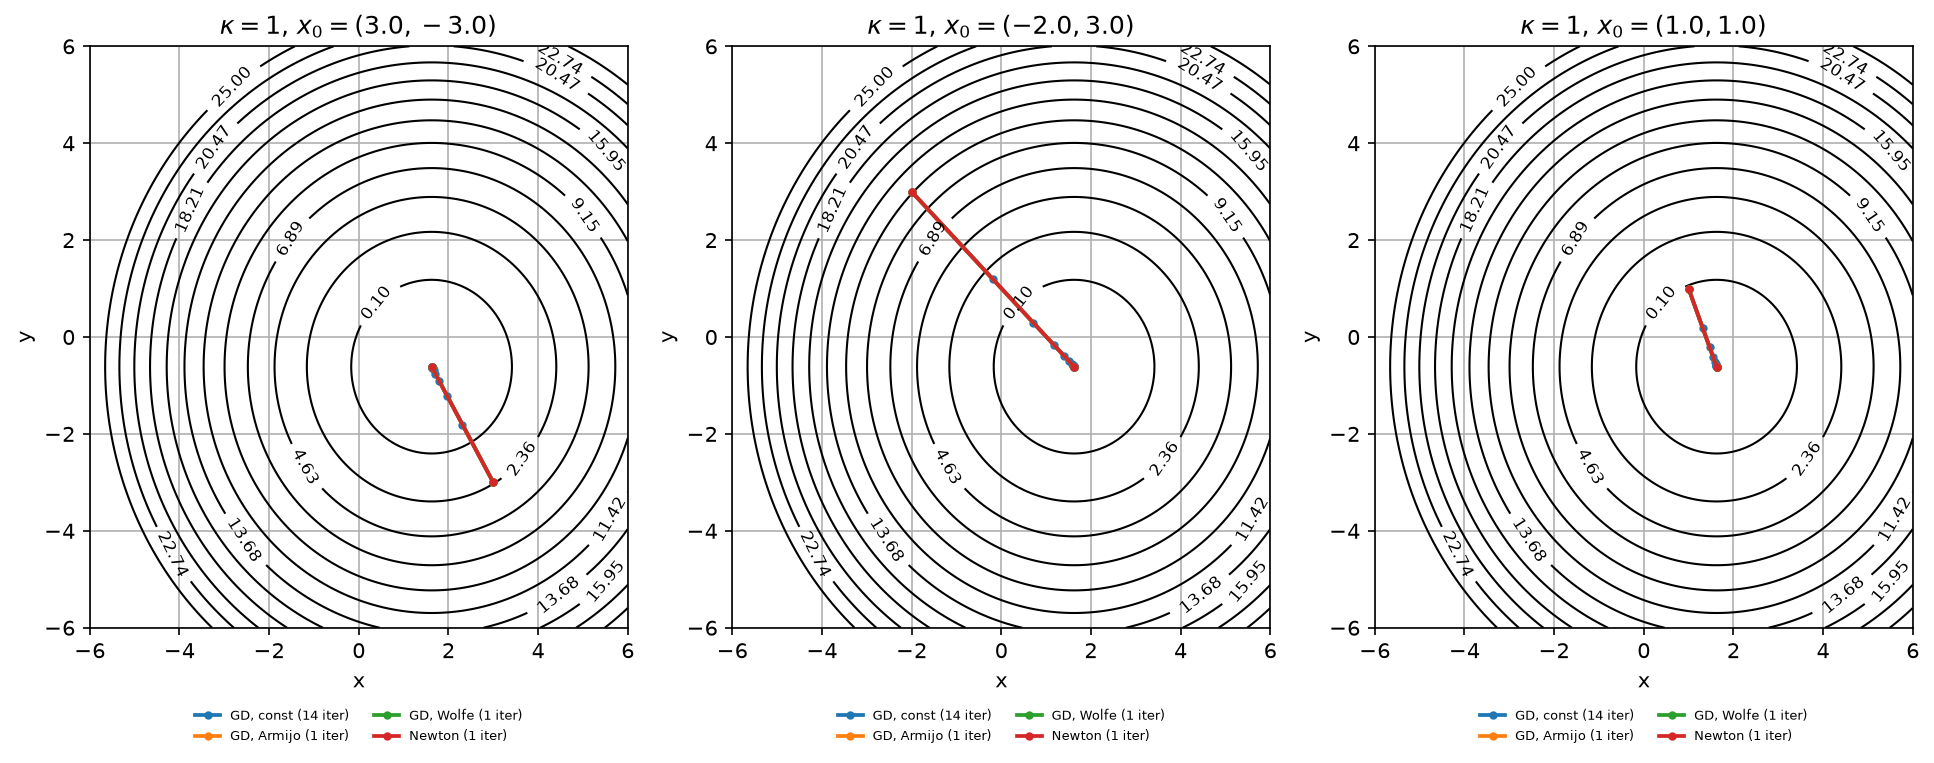

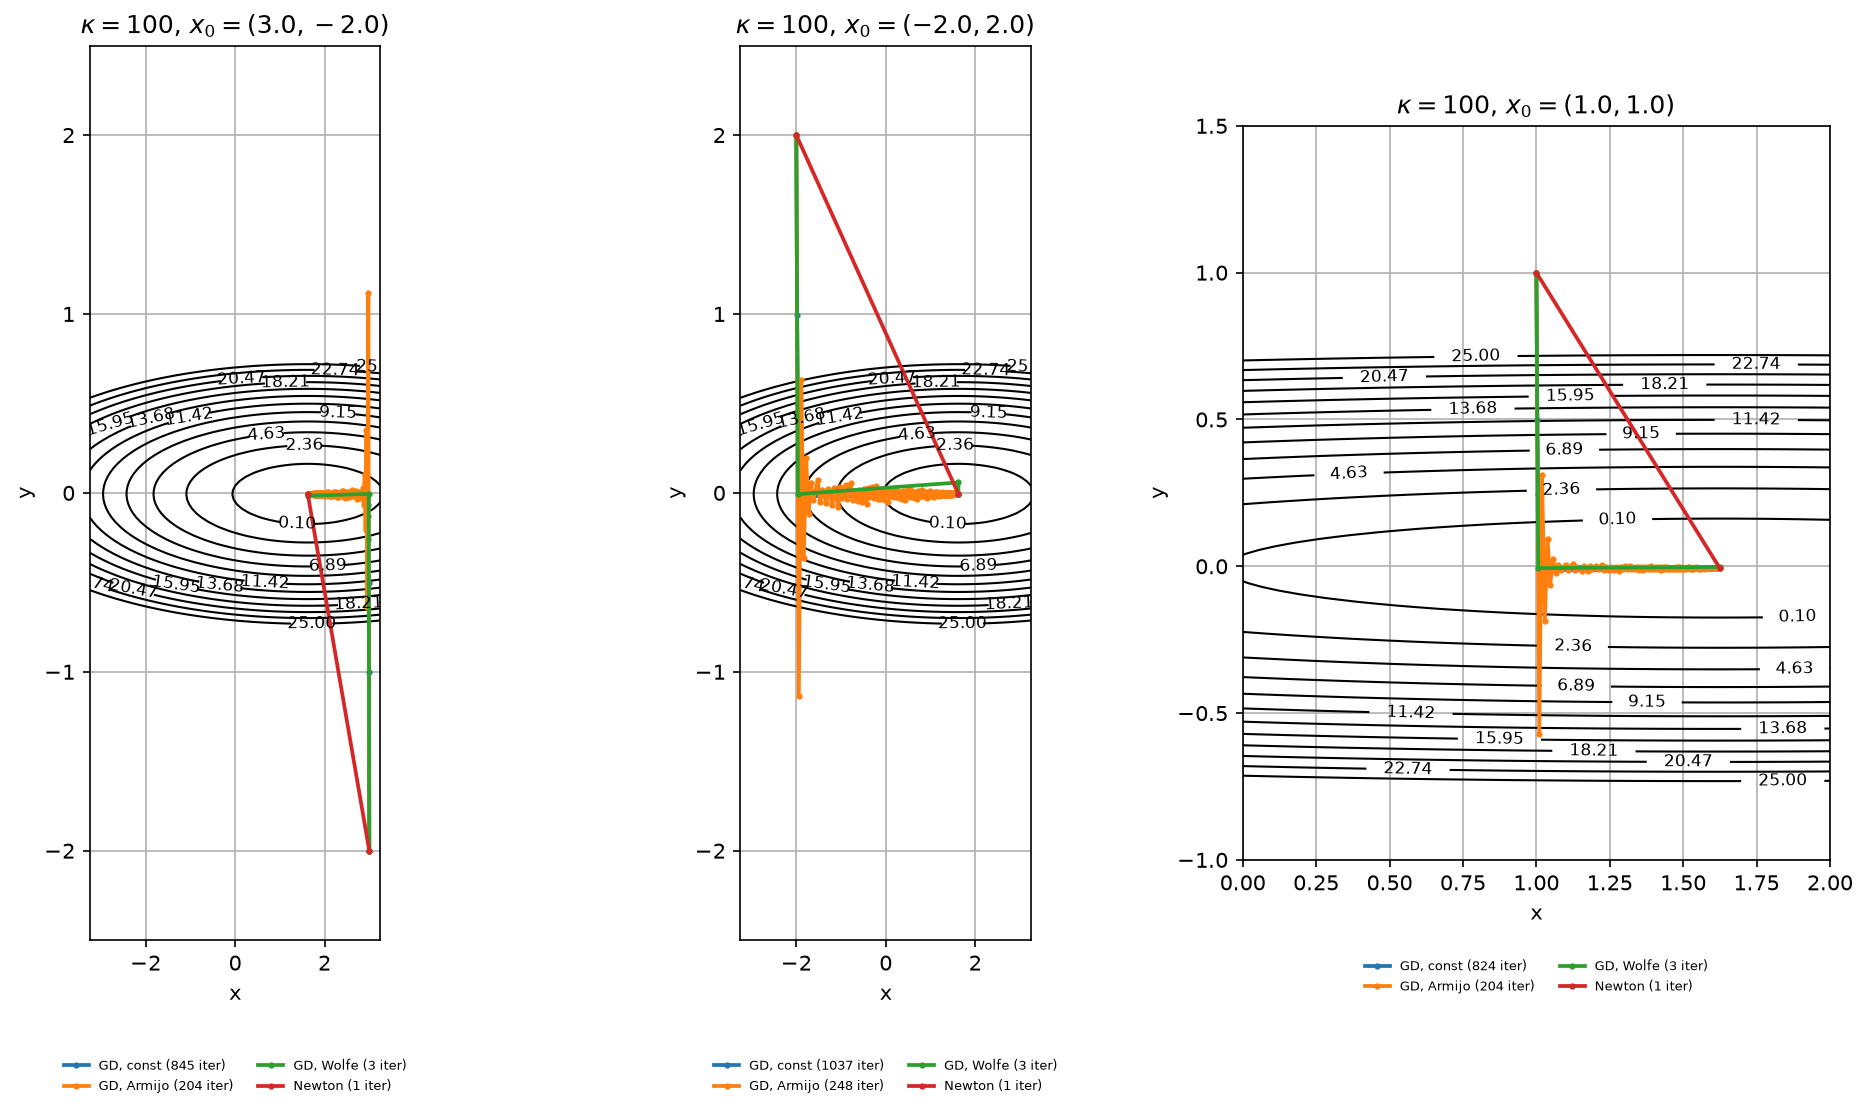

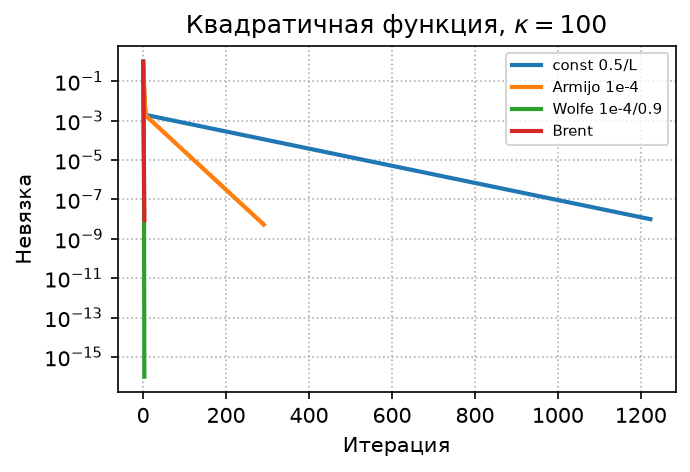

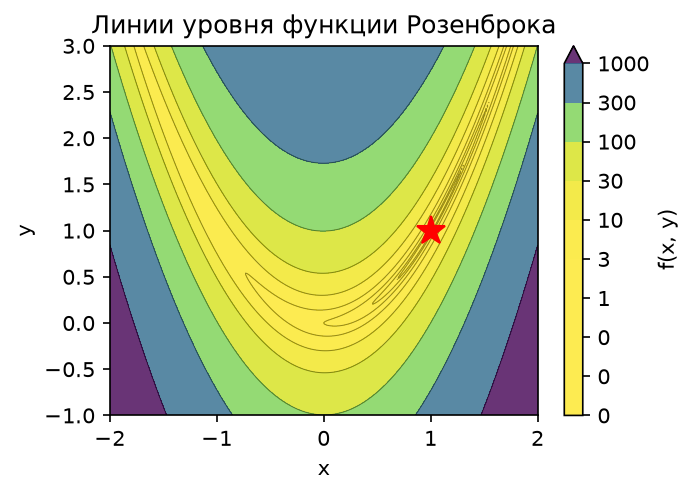

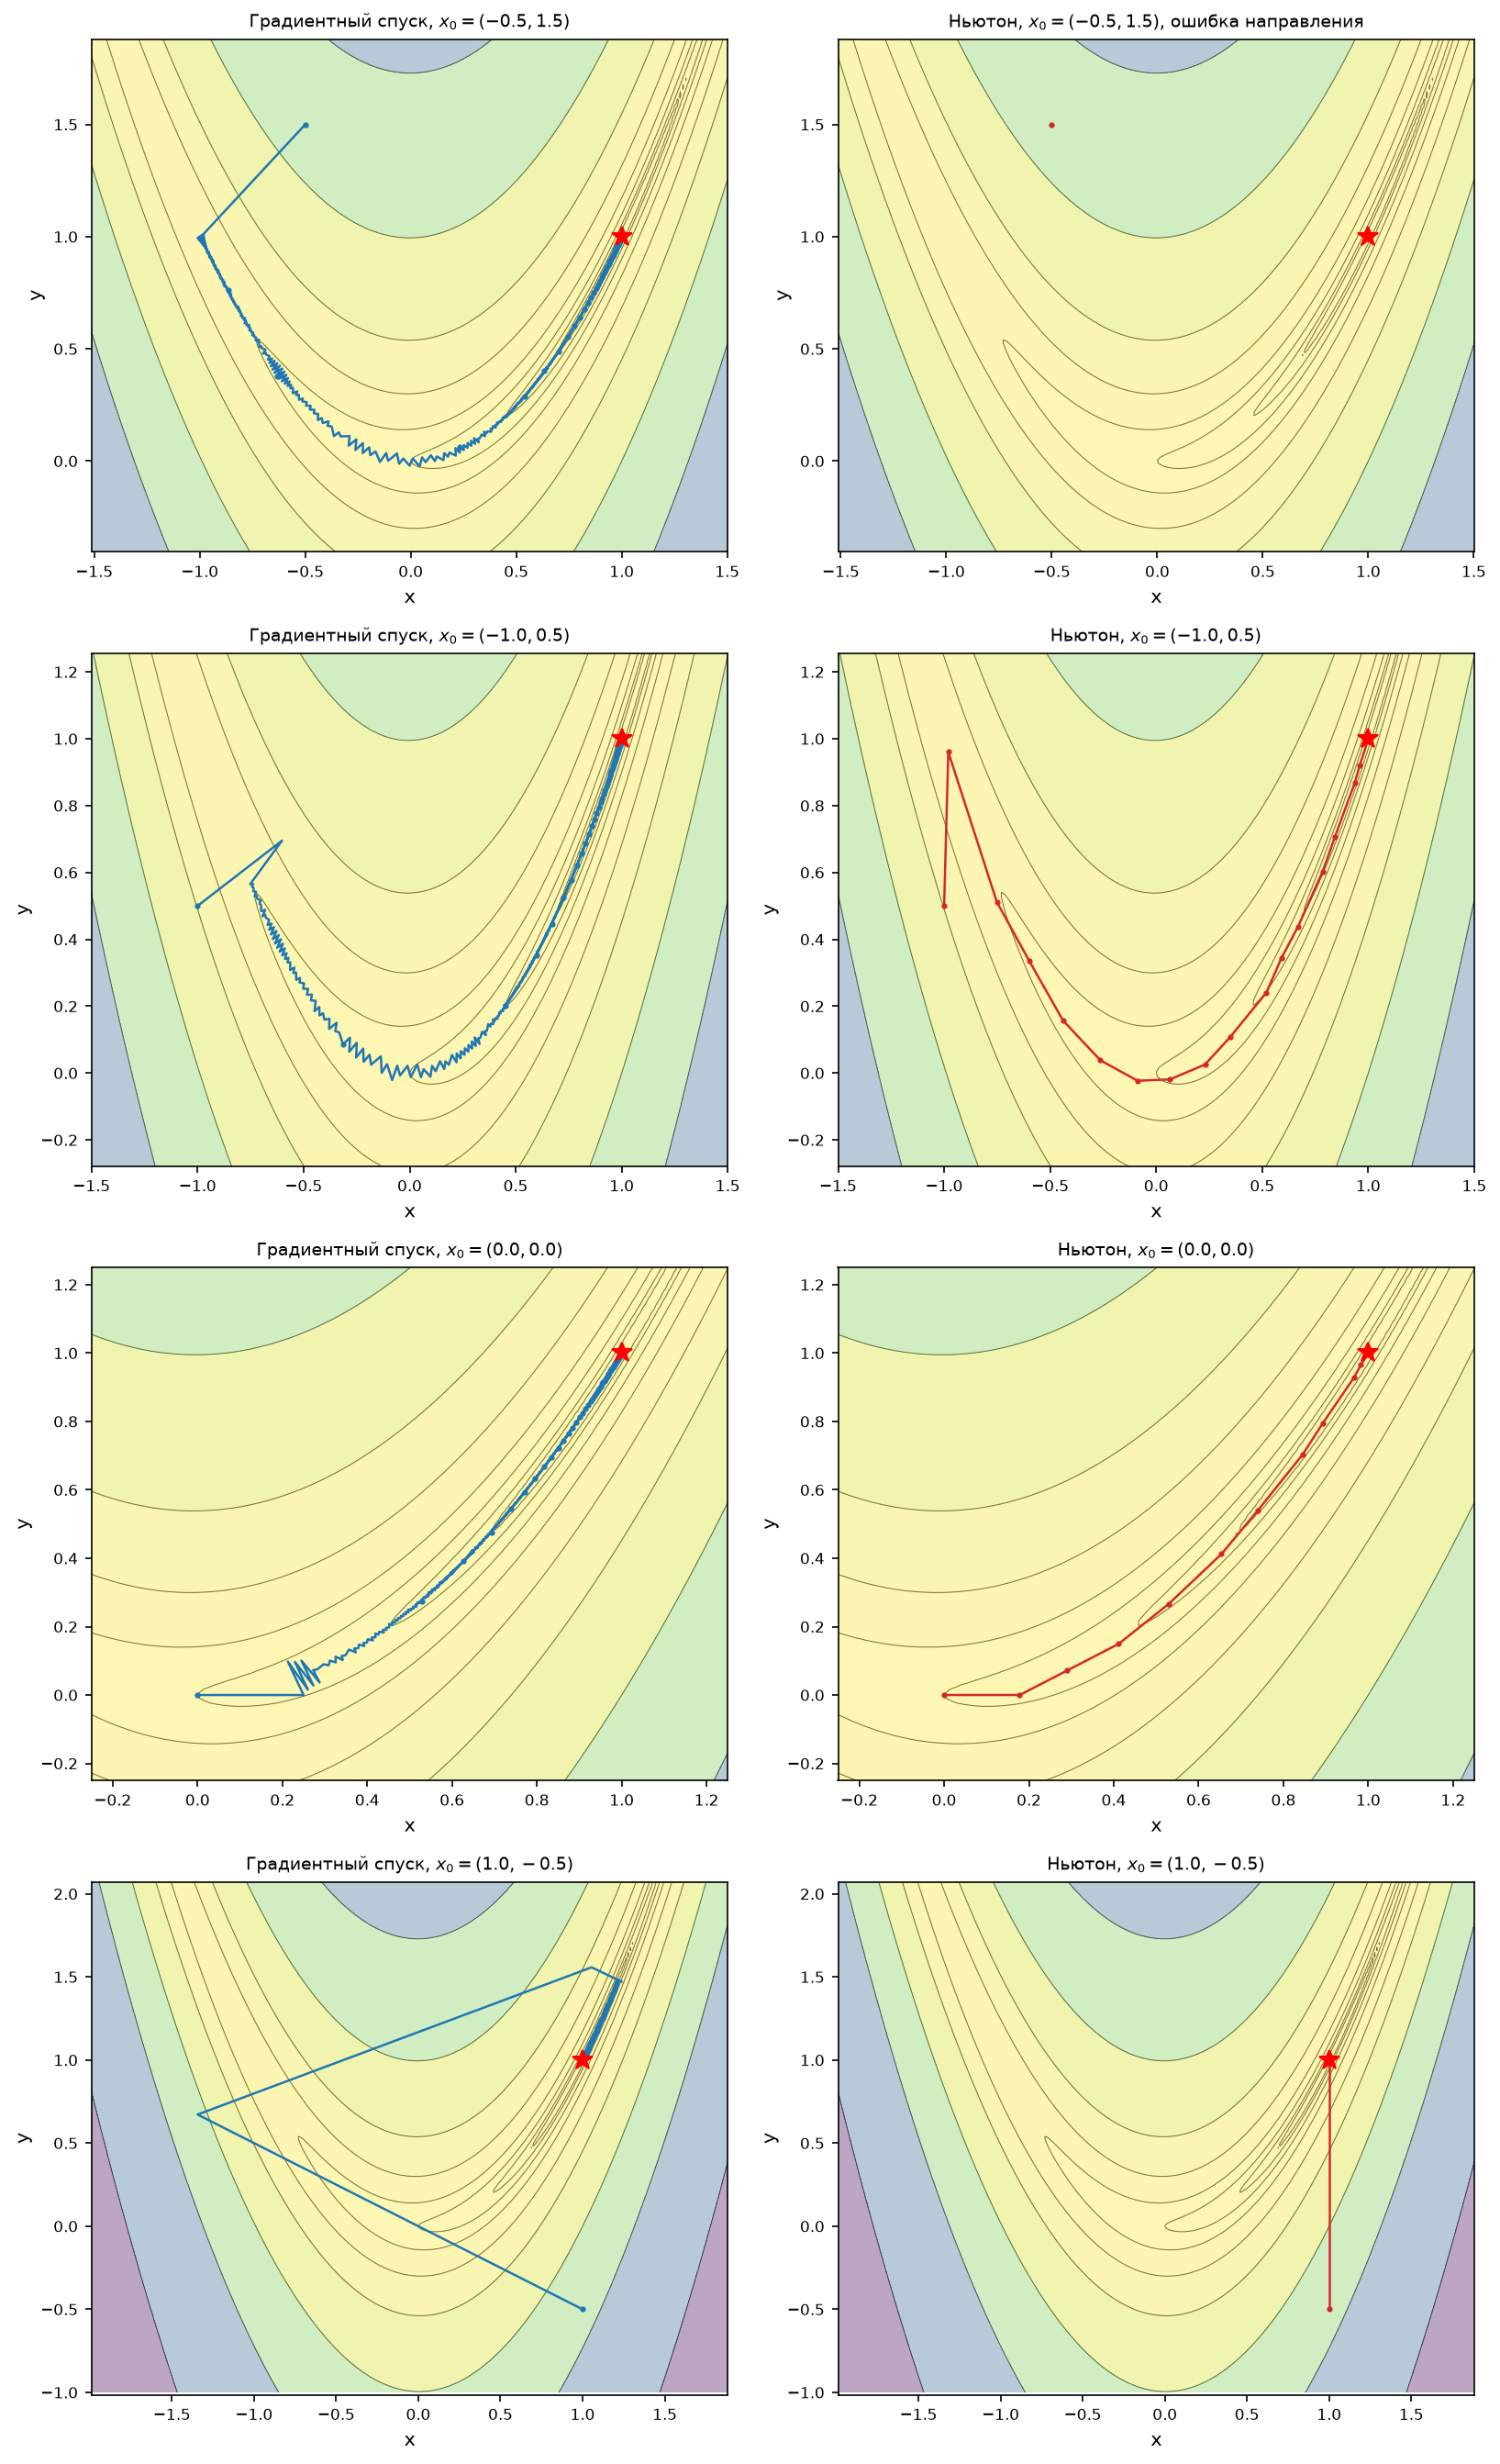

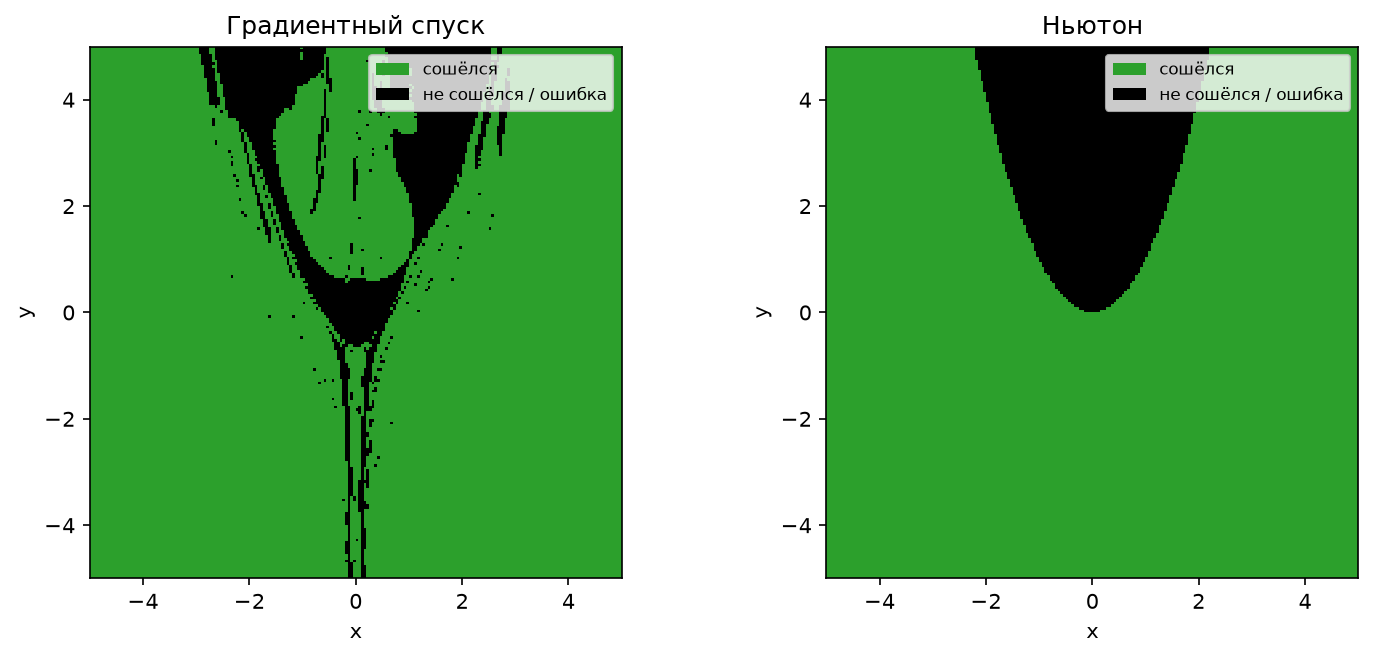

grad(1,1): [-0.0, 0.0]
eig H(1,1): [0.399, 1001.601]
eig H(0,1): [-398.0, 200.0]


In [12]:
def exp1_quad():
    starts_k1 = [np.array([3.0, -3.0]), np.array([-2.0, 3.0]), np.array([1.0, 1.0])]
    starts_k100 = [np.array([3.0, -2.0]), np.array([-2.0, 2.0]), np.array([1.0, 1.0])]
    for kappa, fname in [(1.0, 'exp1_quad_kappa1'), (100.0, 'exp1_quad_kappa100')]:
        oracle = quad2d(kappa, seed=1)
        L = kappa
        c_const = 0.5 / L
        x_starts = starts_k1 if kappa == 1 else starts_k100
        figsize = (13, 7.5) if kappa > 1 else (13, 5.2)
        fig, axes = plt.subplots(1, len(x_starts), figsize=figsize)
        for idx, (ax, x0) in enumerate(zip(axes, x_starts)):
            plt.sca(ax)
            levels = np.linspace(0.1, 25, 12)
            if kappa == 1:
                xr, yr, aspect = [-6, 6], [-6, 6], None
            elif idx == 2:
                xr, yr, aspect = [0, 2], [-1.0, 1.5], 1
            else:
                xr, yr, aspect = [-3.25, 3.25], [-2.5, 2.5], 4
            plot_levels(oracle.func, xrange=xr, yrange=yr, levels=levels, num=200)
            trajectories = {}
            _, msg, hist = gradient_descent(
                oracle, np.asarray(x0, dtype=float), tolerance=1e-8, max_iter=5000,
                line_search_options={'method': 'Constant', 'c': c_const}, trace=True)
            trajectories['GD, const'] = (hist['x'], 'C0', len(hist['func']) - 1)
            _, msg, hist = gradient_descent(
                oracle, np.asarray(x0, dtype=float), tolerance=1e-8, max_iter=5000,
                line_search_options={'method': 'Armijo', 'c1': 1e-4}, trace=True)
            trajectories['GD, Armijo'] = (hist['x'], 'C1', len(hist['func']) - 1)
            _, msg, hist = gradient_descent(
                oracle, np.asarray(x0, dtype=float), tolerance=1e-8, max_iter=5000,
                line_search_options={'method': 'Wolfe', 'c1': 1e-4, 'c2': 0.9}, trace=True)
            trajectories['GD, Wolfe'] = (hist['x'], 'C2', len(hist['func']) - 1)
            _, msg, hist = newton(
                oracle, np.asarray(x0, dtype=float), tolerance=1e-8, max_iter=50,
                trace=True)
            trajectories['Newton'] = (hist['x'], 'C3', len(hist['func']) - 1)
            ms = 2 if kappa > 1 else 3
            for label, (path, color, nit) in trajectories.items():
                path = np.asarray(path)
                ax.plot(path[:, 0], path[:, 1], '-o', color=color, ms=ms, lw=1.8,
                        label='{} ({} iter)'.format(label, nit))
            ax.set_xlim(xr)
            ax.set_ylim(yr)
            if aspect is not None:
                ax.set_aspect(aspect)
            ax.set_title(r'$\kappa = {}$, $x_0 = ({:.1f}, {:.1f})$'.format(
                int(kappa), x0[0], x0[1]))
            ax.set_xlabel('x')
            ax.set_ylabel('y')
            ax.legend(fontsize=6, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
        fig.tight_layout()
        savefig(fname)
        plt.close(fig)

    oracle = quad2d(100.0, seed=1)
    A, b = oracle.A, oracle.b
    x_star = np.linalg.solve(A, b)
    f_star = oracle.func(x_star)
    x0 = np.array([3.0, -3.0])
    f0 = oracle.func(x0)
    strategies = [
        ('const 0.5/L', {'method': 'Constant', 'c': 0.5 / 100.0}),
        ('Armijo 1e-4', {'method': 'Armijo', 'c1': 1e-4}),
        ('Wolfe 1e-4/0.9', {'method': 'Wolfe', 'c1': 1e-4, 'c2': 0.9}),
        ('Brent', {'method': 'Brent'}),
    ]
    plt.figure(figsize=(4.8, 3.0))
    for label, opts in strategies:
        _, msg, hist = gradient_descent(oracle, x0, tolerance=1e-10, max_iter=5000,
                                        line_search_options=opts, trace=True)
        rel = (np.asarray(hist['func']) - f_star) / (f0 - f_star)
        plt.semilogy(np.arange(len(rel)), np.maximum(rel, 1e-16), lw=2, label=label)
    plt.xlabel('Итерация')
    plt.ylabel('Невязка')
    plt.title(r'Квадратичная функция, $\kappa=100$')
    plt.legend(fontsize=7)
    plt.grid(True, which='both', ls=':')
    savefig('exp1_quad_convergence')
    plt.close()


def exp1_rosen(grid_n=200):
    oracle = RosenbrockOracle()
    X, Y, Z = rosen_levels()
    levels = np.array([0, 0.1, 0.3, 1, 3, 10, 30, 100, 300, 1000])
    plt.figure(figsize=(4.6, 3.2))
    cs = plt.contourf(X, Y, Z, levels=levels, cmap='viridis_r', extend='max', alpha=0.8)
    plt.colorbar(cs, label='f(x, y)')
    plt.contour(X, Y, Z, levels=levels, colors='k', linewidths=0.5, alpha=0.4)
    plt.plot(1, 1, 'r*', ms=14)
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title('Линии уровня функции Розенброка')
    savefig('exp1_rosenbrock_levels')
    plt.close()

    starts = [np.array([-0.5, 1.5]), np.array([-1.0, 0.5]),
              np.array([0.0, 0.0]), np.array([1.0, -0.5])]
    fig, axes = plt.subplots(4, 2, figsize=(11, 18))
    for row, x0 in enumerate(starts):
        row_paths = []
        for method in ['GD', 'Newton']:
            if method == 'GD':
                g0_norm = np.linalg.norm(oracle.grad(x0))
                tol_gd = (1e-3 / g0_norm) ** 2
                x_star, msg, hist = gradient_descent(
                    oracle, x0, tolerance=tol_gd, max_iter=10000,
                    line_search_options={'method': 'Armijo', 'c1': 1e-4}, trace=True)
                color = 'C0'
            else:
                x_star, msg, hist = newton(
                    oracle, x0, tolerance=1e-10, max_iter=100, trace=True)
                color = 'C3'
            row_paths.append((np.asarray(hist['x']), msg, color))
        allp = np.vstack([p for p, _, _ in row_paths] + [x0[None, :], np.array([[1.0, 1.0]])])
        xmin, xmax = allp[:, 0].min(), allp[:, 0].max()
        ymin, ymax = allp[:, 1].min(), allp[:, 1].max()
        dx = max(0.25, 0.25 * (xmax - xmin))
        dy = max(0.25, 0.25 * (ymax - ymin))
        for col, (path, msg, color) in enumerate(row_paths):
            ax = axes[row, col]
            ax.contourf(X, Y, Z, levels=levels, cmap='viridis_r', extend='max', alpha=0.35)
            ax.contour(X, Y, Z, levels=levels, colors='k', linewidths=0.5, alpha=0.5)
            markevery = max(1, len(path) // 100)
            ax.plot(path[:, 0], path[:, 1], '-o', ms=2, lw=1.2, color=color,
                    markevery=markevery)
            ax.plot(1, 1, 'r*', ms=11)
            ax.set_xlim(xmin - dx, xmax + dx)
            ax.set_ylim(ymin - dy, ymax + dy)
            ax.set_xlabel('x')
            ax.set_ylabel('y')
            name = 'Градиентный спуск' if col == 0 else 'Ньютон'
            status = ''
            if msg == 'newton_direction_error':
                status = ', ошибка направления'
            elif msg == 'iterations_exceeded':
                status = ', не успел'
            title = '{}, $x_0=({:.1f},{:.1f})$'.format(name, x0[0], x0[1])
            ax.set_title(title + status, fontsize=9)
            ax.tick_params(labelsize=8)
    fig.tight_layout()
    savefig('exp1_rosenbrock_trajectories')
    plt.close(fig)

    def basin_map(method, n=grid_n, xmin=-5, xmax=5, tol=1e-7,
                  max_iter_gd=2000, max_iter_newton=100):
        xs = np.linspace(xmin, xmax, n)
        ys = np.linspace(xmin, xmax, n)
        Zcls = np.zeros((n, n), dtype=int)
        for i, y in enumerate(ys):
            for j, x in enumerate(xs):
                p = np.array([x, y])
                if method == 'gd':
                    x_star, msg, _ = gradient_descent(
                        oracle, p, tolerance=tol, max_iter=max_iter_gd,
                        line_search_options={'method': 'Armijo', 'c1': 1e-4})
                else:
                    x_star, msg, _ = newton(oracle, p, tolerance=tol,
                                            max_iter=max_iter_newton)
                Zcls[i, j] = 0 if msg == 'success' else 1
        return Zcls

    Zmaps = {m: basin_map(m) for m in ['gd', 'newton']}
    cmap = ListedColormap(['#2ca02c', '#000000'])
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
    for ax, method in zip(axes, ['gd', 'newton']):
        ax.imshow(Zmaps[method], extent=[-5, 5, -5, 5], origin='lower', cmap=cmap,
                  interpolation='nearest')
        ax.set_xlabel('x')
        ax.set_ylabel('y')
        ax.set_title('Градиентный спуск' if method == 'gd' else 'Ньютон')
        legend = [Patch(facecolor='#2ca02c', label='сошёлся'),
                  Patch(facecolor='#000000', label='не сошёлся / ошибка')]
        ax.legend(handles=legend, loc='upper right', fontsize=8)
    fig.tight_layout()
    savefig('exp1_basins')
    plt.close(fig)

    print('grad(1,1):', np.round(oracle.grad(np.array([1.0, 1.0])), 3).tolist())
    print('eig H(1,1):',
          np.round(np.linalg.eigvalsh(oracle.hess(np.array([1.0, 1.0]))), 3).tolist())
    print('eig H(0,1):',
          np.round(np.linalg.eigvalsh(oracle.hess(np.array([0.0, 1.0]))), 3).tolist())


if 1 in RUN:
    exp1_quad()
    exp1_rosen(grid_n=200)
else:
    print('Эксперимент 1 пропущен')


### Эксперимент 1, часть 1: 
При $\kappa=100$ поведение уже не такое предсказуемое, как при $\kappa=1$. При большом числе обусловленности GD с константой $\frac{1}{2L}$ делает около тысячи итераций. Армихо ускоряет примерно в 4 раза. Вульф на квадратичной функции вообще укладывается в 3 итерации. Ньютон во всех запусках делает ровно один шаг.

При $\kappa=1$ линии уровня — окружности, и все методы сходятся быстро, так что разница между ними почти теряется. Количество итераций при этом от старта почти не зависит: у константного шага везде 14, у остальных — по одной. На траекториях при $\kappa=100$ заметно, что мы сначала долго движемся поперёк оврага, а потом уже вдоль него. Ньютон хорошо себя чувствует на квадратичных функциях, если, конечно, гессиан положительный.

Армихо и Вульф устойчивее, чем GD const, потому что подбирают шаг сами, а для константного шага мы можем легко разойтись при большой константе или просто очень долго сходиться. При этом Вульф в целом выглядит как фаворит, всего три дешевых итерации. `LinAlgError` здесь не может возникнуть на квадратичной функции с положительной определённостью.


### Эксперимент 1, часть 2: 
По карте бассейнов у Ньютона зелёная область довольно большая, но в середине парабола, в которой мы не сходимся. Там гессиан не положительно определён, `cho_factor` не может разложить матрицу, и метод завершается ошибкой. Там, где гессиан положительный, Ньютон быстро приходит в минимум, а, например, в $(0,1)$ сразу получает `newton_direction_error`. У градиентного спуска граница бассейна получилась рваной.

У Розенброка в этой области одна стационарная точка $(1,1)$, гессиан в ней положительно определён, следовательно это глобальный минимум. Сёдел и локальных максимумов нет. Градиентный спуск с Армихо выглядит чуть получше, так как зелёная область занимает большую часть, но зато точки, в которых он не сошелся выглядят рандомнее. Чёрные пятна остаются около оврага и вокруг $(0,0)$ — там за 2000 итераций он не успевает добраться до $(1,1)$. GD в целом часто начинает идти зигзагом и не доходит за 2000 интераций.

Седло для GD неустойчиво, если, конечно, не стартовать точно в нём, так как мы идём точно в направлении антиградиента. А Ньютон на каждом шаге решает: $\nabla^2 f(x_k) d_k = -\nabla f(x_k) $. Если у Гессиан есть отрицательные собственные значения, шаг может вести не к минимуму, а к седлу или максимуму. Фрактал у меня, конечно, почему-то не получился, не знаю можно ли бассейн GD так назвать

## Эксперимент 2. Зависимость числа итераций градиентного спуска от числа обусловленности и размерности

Исследуйте, как число итераций $T(n, \kappa)$, необходимое градиентному спуску для выполнения критерия (1), зависит от числа обусловленности $\kappa \ge 1$ и размерности $n$.

**Генерация задачи.** Возьмите диагональную матрицу $A = \mathrm{Diag}(a)$, где элементы $a$ случайны в пределах $[1, \kappa]$, причём $\min(a) = 1$, $\max(a) = \kappa$. Вектор $b$ возьмите случайным. Храните $A$ как разреженную диагональную матрицу (`scipy.sparse.diags`), тогда эксперимент работает даже при больших $n$.

**Порядок проведения.**
1. Зафиксируйте $n$. Переберите $\kappa$ по логарифмической сетке и постройте график $T(n, \kappa)$ от $\kappa$. Задача генерируется случайно, поэтому повторите эксперимент несколько раз: получится семейство кривых. Нарисуйте их одним цветом.
2. Повторите для других $n$ по логарифмической сетке ($n = 10, 100, 1000, \dots$), каждое семейство своим цветом.
3. Для сравнения проведите тот же эксперимент для метода Ньютона (хватит нескольких значений $\kappa$ и $n$).

### Вопросы для отчёта
1. Какие выводы можно сделать из полученной картинки? Сравните наблюдаемую зависимость с теоретической оценкой числа итераций градиентного спуска.
2. Зависит ли число итераций от размерности $n$ при фиксированном $\kappa$? Почему?
3. Что происходит с числом итераций метода Ньютона при росте $\kappa$? Объясните результат через формулу шага метода Ньютона для квадратичной функции.

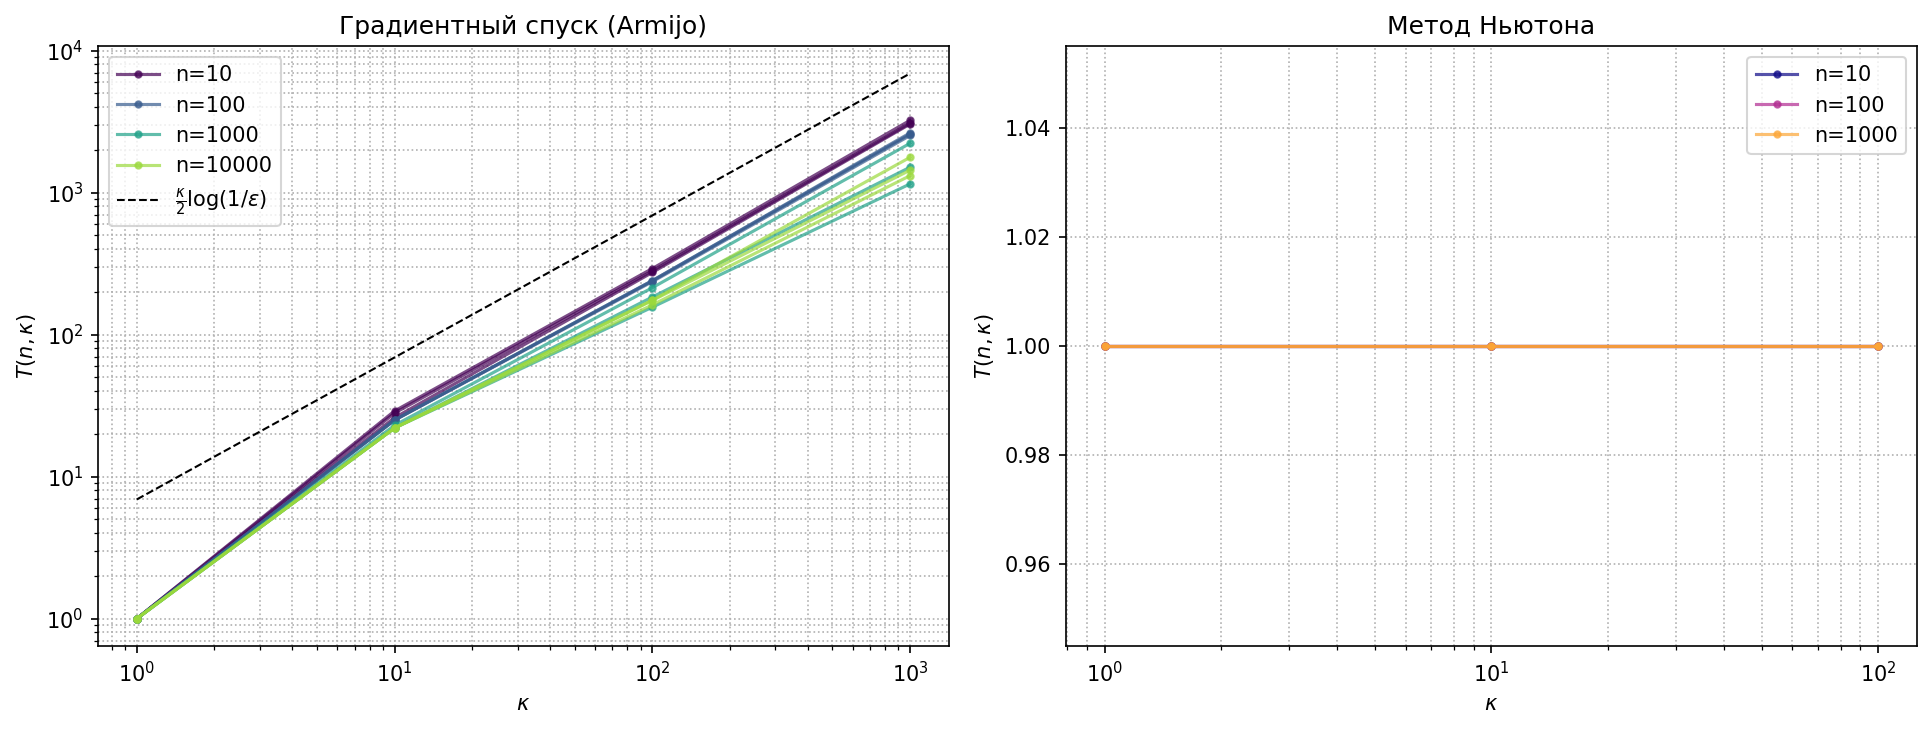

In [13]:
def exp2(n_values=(10, 100, 1000, 10000), kappas=(1, 10, 100, 1000),
             repeats=3, tol=1e-6, newton_n=(10, 100, 1000),
             newton_kappas=(1, 10, 100), newton_repeats=2):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    colors = plt.cm.viridis(np.linspace(0.0, 0.85, len(n_values)))
    gd_rows = []
    for color, n in zip(colors, n_values):
        for rep in range(repeats):
            Ts = []
            for kappa in kappas:
                oracle = gen_problem(n, kappa, seed=1000 * n + rep)
                x0 = np.zeros(n)
                _, msg, hist = gradient_descent(
                    oracle, x0, tolerance=tol, max_iter=20000,
                    line_search_options={'method': 'Armijo', 'c1': 1e-4}, trace=True)
                T = len(hist['func']) - 1 if msg == 'success' else np.nan
                Ts.append(T)
                gd_rows.append([n, kappa, T])
            axes[0].plot(kappas, Ts, '-o', color=color, alpha=0.7, ms=3,
                         label='n={}'.format(n) if rep == 0 else None)
    kappa_ref = np.array(kappas, dtype=float)
    axes[0].plot(kappa_ref, np.log(1.0 / tol) / 2.0 * kappa_ref, 'k--', lw=1.0,
                 label=r'$\frac{\kappa}{2}\log(1/\varepsilon)$')
    axes[0].set_xscale('log')
    axes[0].set_yscale('log')
    axes[0].set_xlabel(r'$\kappa$')
    axes[0].set_ylabel(r'$T(n, \kappa)$')
    axes[0].set_title('Градиентный спуск (Armijo)')
    axes[0].legend()
    axes[0].grid(True, which='both', ls=':')

    colors2 = plt.cm.plasma(np.linspace(0.0, 0.8, len(newton_n)))
    for color, n in zip(colors2, newton_n):
        for rep in range(newton_repeats):
            Ts = []
            for kappa in newton_kappas:
                oracle = gen_problem(n, kappa, seed=1000 * n + rep)
                x0 = np.zeros(n)
                _, msg, hist = newton(oracle, x0, tolerance=tol, max_iter=100, trace=True)
                Ts.append(len(hist['func']) - 1 if msg == 'success' else np.nan)
            axes[1].plot(newton_kappas, Ts, '-o', color=color, alpha=0.7, ms=3,
                         label='n={}'.format(n) if rep == 0 else None)
    axes[1].set_xscale('log')
    axes[1].set_xlabel(r'$\kappa$')
    axes[1].set_ylabel(r'$T(n, \kappa)$')
    axes[1].set_title('Метод Ньютона')
    axes[1].legend()
    axes[1].grid(True, which='both', ls=':')
    fig.tight_layout()
    savefig('exp2_iterations')
    plt.close(fig)

    return gd_rows


if 2 in RUN:
    rows_exp2 = exp2()
    import pandas as pd
    table = pd.DataFrame(rows_exp2, columns=['n', 'каппа', 'T'])
    display(table.groupby(['n', 'каппа'])['T'].median().unstack())
else:
    print('Эксперимент 2 пропущен')

### Эксперимент 2: ваш ответ

На левом графике число итераций GD растёт с $\kappa$ почти линейно. При $\kappa=1$ метод делает одну итерацию, а при $\kappa=1000$ — уже тысячи, причём разброс между запусками заметный. Формально тут $T=O(\kappa\log(1/\varepsilon))$, и по наклону это похоже на правду. Оценка $\frac{\kappa}{2}\log(1/\varepsilon)$ лежит выше наших кривых, и это ожидаемо.

При фиксированном $\kappa$ кривые для $n=10,100,1000,10000$ идут довольно кучно, хотя при больших $\kappa$ линия для $n=10$ чуть выше. По идее скорость сходимости определяется числом обусловленности, а не размерностью. Небольшие расхождения — из-за того, что случайные собственные значения по-разному заполняют отрезок $[1,\kappa]$ и меняются проекции начального градиента.

С Ньютоном очевидно, на квадратичной функции он делает одну итерацию при любых $\kappa$ и $n$. Обусловленность тут бьёт не по числу итераций, а по стоимости одной итерации: разложение стоит $O(n^3)$, а памяти нужно $O(n^2)$. Метод Ньютона фактически расписывается через форумулу Тейлора до второй степени, поэтому минимум квадратной функции мы получаем сразу. 

## Эксперимент 3. Сравнение градиентного спуска и метода Ньютона на реальных данных

Сравните градиентный спуск и метод Ньютона на обеих функциях потерь.

* Коэффициент регуляризации: $\lambda = 1/m$.
* Параметры методов — по умолчанию, начальная точка $x_0 = 0$.

Постройте графики сходимости (оба метода на одном графике):
* (a) значение функции от реального времени работы (в секундах);
* (b) относительный квадрат нормы градиента $\|\nabla f(x_k)\|_2^2 / \|\nabla f(x_0)\|_2^2$ в логарифмической шкале от реального времени работы.

В отчёте укажите размеры датасетов ($m \times n$), долю ненулевых элементов матрицы $A$ и характеристики компьютера (CPU, RAM).

### Вопросы для отчёта

0. Является ли функция выпуклой? Почему?

1. Как влияет регуляризация на градиентный спуск? Подтверждается ли это графиками?

2. Какова стоимость одной итерации и сколько памяти требует каждый метод в зависимости от $m$, $n$ (и числа ненулевых элементов матрицы $A$ для разреженных данных)? Используйте нотацию $O(\cdot)$.
3. Какой метод лучше и в каких ситуациях («высокий» датасет с $m \gg n$ против «широкого» с большим $n$)?
4. Отличается ли поведение методов на регрессионной и классификационной функциях потерь? С чем это связано?

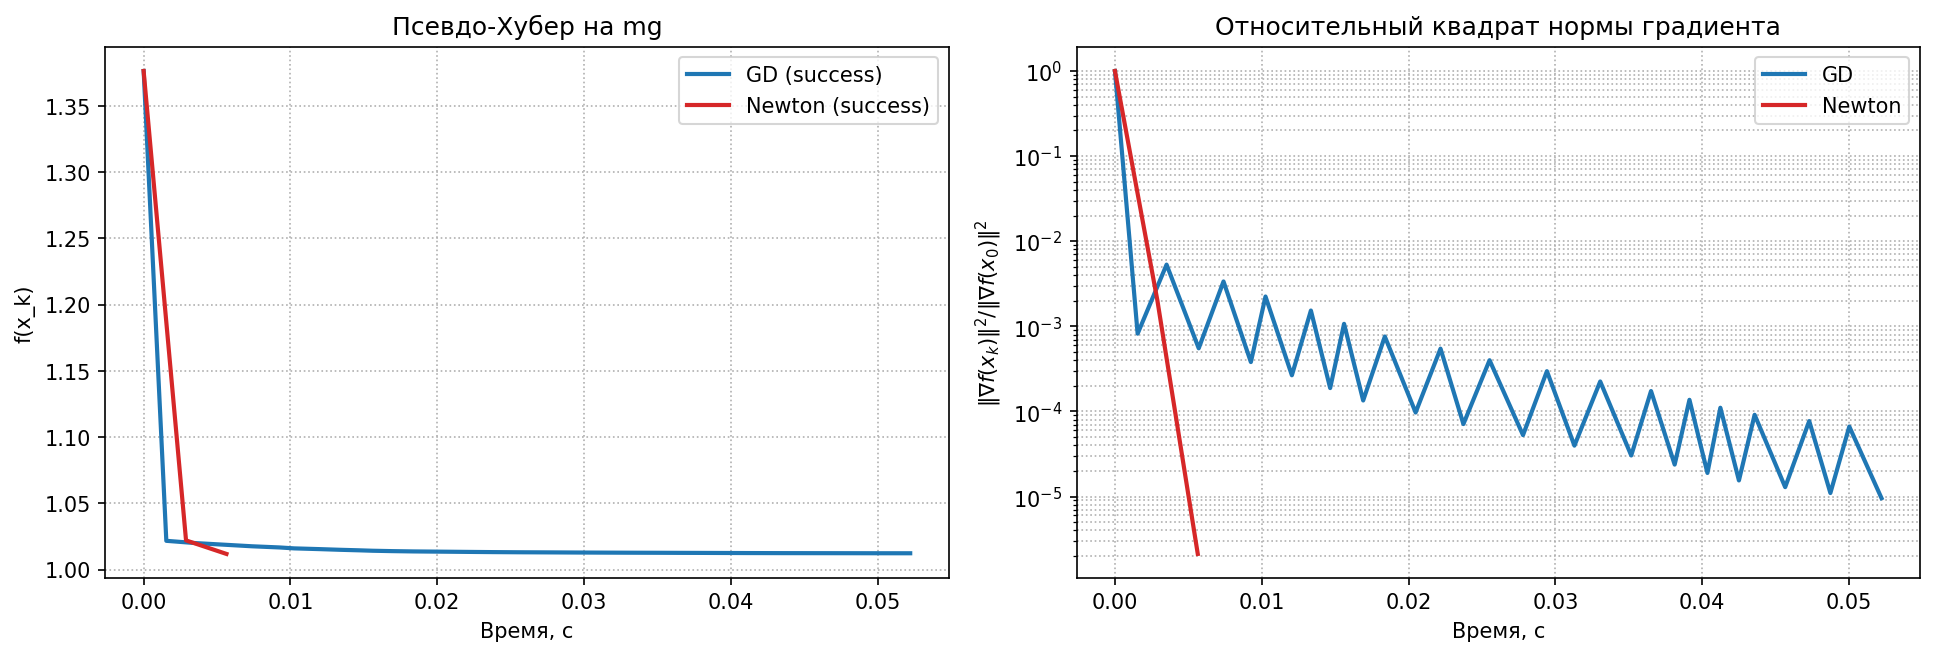

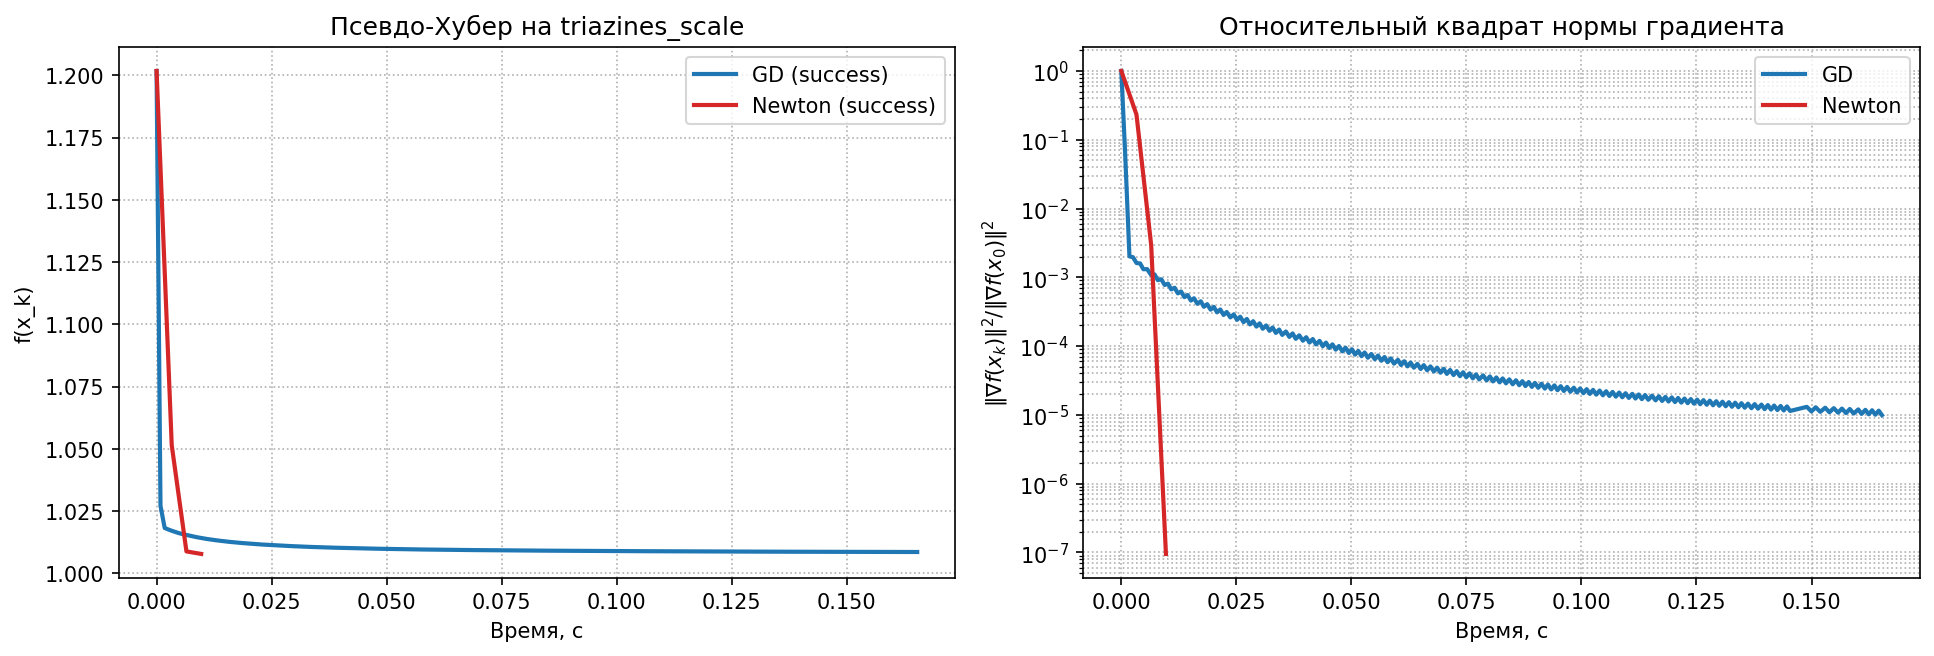

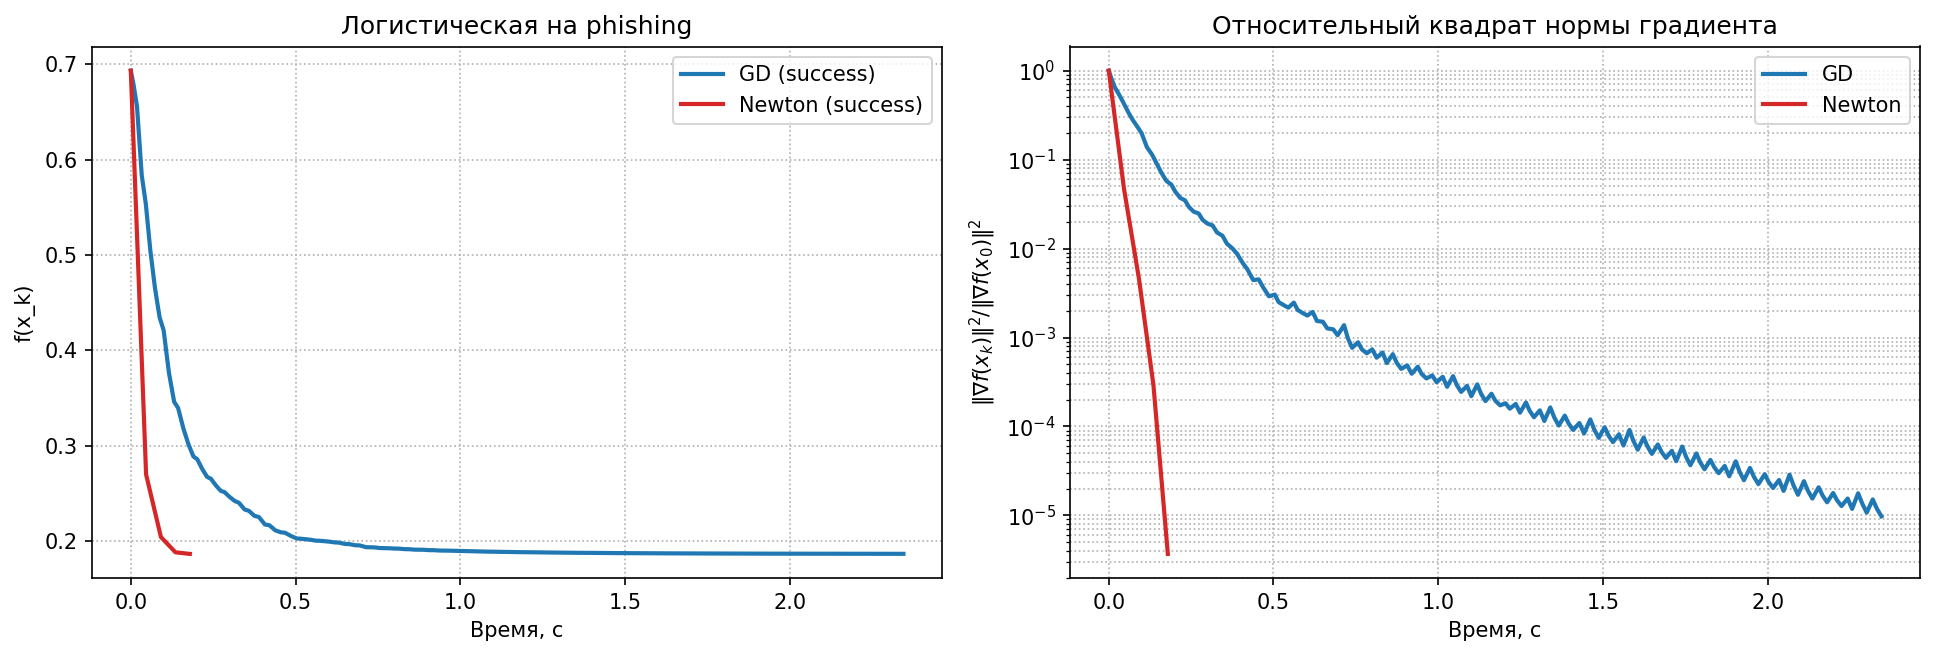

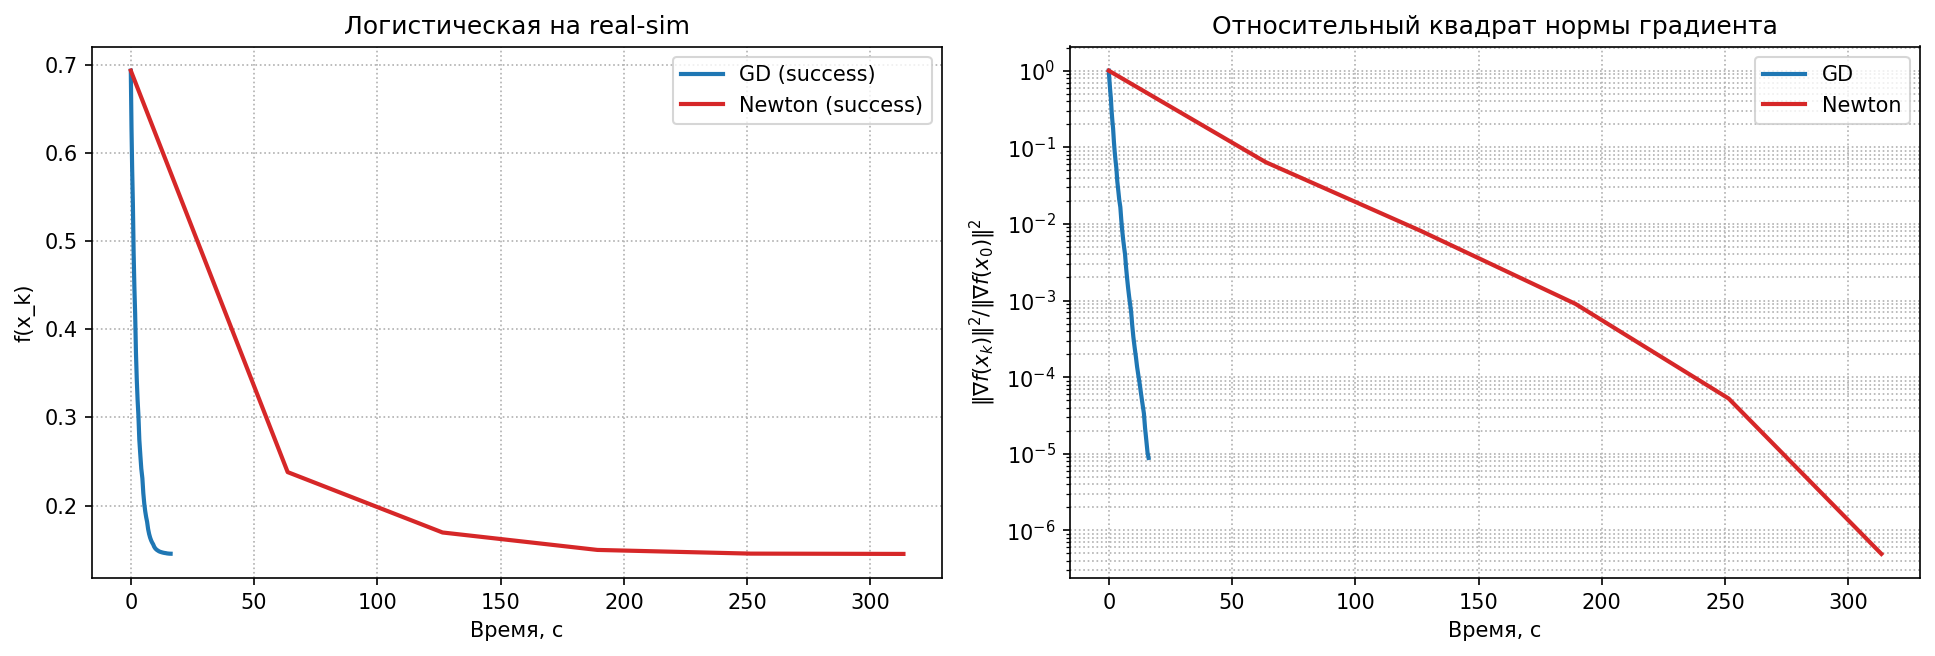

Псевдо-Хубер на mg: 33 iter, 0.053 с, f = 1.0123, ||grad|| = 2.08e-02
Псевдо-Хубер на mg: 2 iter, 0.006 с, f = 1.0118, ||grad|| = 9.79e-03
Псевдо-Хубер на triazines_scale: 224 iter, 0.166 с, f = 1.0086, ||grad|| = 9.72e-03
Псевдо-Хубер на triazines_scale: 3 iter, 0.010 с, f = 1.0078, ||grad|| = 9.52e-04
Логистическая на phishing: 159 iter, 2.347 с, f = 0.1870, ||grad|| = 2.74e-04
Логистическая на phishing: 4 iter, 0.181 с, f = 0.1869, ||grad|| = 1.68e-04
Логистическая на real-sim: 40 iter, 16 с, f = 0.1454, ||grad|| = 9.86e-05
Логистическая на real-sim: 5 iter, 313 с, f = 0.1452, ||grad|| = 2.33e-05


In [14]:
def exp3(max_iter_gd=3000, max_iter_newton=100, tol=1e-5):
    configs = [
        ('pseudohuber', 'mg', True, 'regression'),
        ('pseudohuber', 'triazines_scale', False, 'regression'),
        ('logistic', 'phishing', False, 'classification'),
        ('logistic', 'real-sim.bz2', False, 'classification'),
    ]
    rows = []
    for loss_name, data_name, scale, task in configs:
        A, b = load_data(data_name, scale=scale)
        if task == 'classification':
            b = to_pm1(b)
        info = data_info(A, b)
        m, n = A.shape
        oracle = create_linear_model_oracle(A, b, 1.0 / m, loss_name)
        x0 = np.zeros(n)
        hist = {}
        messages = {}
        for method, runner, max_iter in [
                ('GD', gradient_descent, max_iter_gd),
                ('Newton', newton, max_iter_newton)]:
            t = time.time()
            x_star, msg, h = runner(oracle, x0, tolerance=tol, max_iter=max_iter, trace=True)
            elapsed = time.time() - t
            hist[method] = h
            messages[method] = msg
            rows.append(dict(loss=loss_name, dataset=data_name.replace('.bz2', ''),
                             m=m, n=n, density=info['density'], method=method,
                             message=msg, iterations=len(h['func']) - 1,
                             time=elapsed, f=h['func'][-1],
                             grad_norm=h['grad_norm'][-1],
                             x_norm=np.linalg.norm(x_star)))
        fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
        for method, color in [('GD', 'C0'), ('Newton', 'C3')]:
            h = hist[method]
            axes[0].plot(h['time'], h['func'], color=color, lw=2,
                         label='{} ({})'.format(method, messages[method]))
            gn = np.asarray(h['grad_norm'])
            axes[1].semilogy(h['time'], np.maximum(gn ** 2 / gn[0] ** 2, 1e-16),
                             color=color, lw=2, label=method)
        axes[0].set_xlabel('Время, с')
        axes[0].set_ylabel('f(x_k)')
        axes[0].set_title('{} на {}'.format(LOSS_RU.get(loss_name, loss_name), data_name.replace('.bz2', '')))
        axes[0].legend()
        axes[0].grid(True, ls=':')
        axes[1].set_xlabel('Время, с')
        axes[1].set_ylabel(r'$\|\nabla f(x_k)\|^2 / \|\nabla f(x_0)\|^2$')
        axes[1].set_title('Относительный квадрат нормы градиента')
        axes[1].legend()
        axes[1].grid(True, which='both', ls=':')
        fig.tight_layout()
        savefig('exp3_' + loss_name + '_' + data_name.replace('.bz2', ''))
        plt.close(fig)
        for r in rows[-2:]:
            t = r['time']
            t_text = '{:.0f} с'.format(t) if t >= 10 else '{:.3f} с'.format(t)
            print('{} на {}: {} iter, {}, f = {:.4f}, ||grad|| = {:.2e}'.format(
                LOSS_RU.get(r['loss'], r['loss']), r['dataset'], r['iterations'],
                t_text, r['f'], r['grad_norm']))
    return rows


if 3 in RUN:
    rows_exp3 = exp3()
    import pandas as pd
    table = pd.DataFrame(rows_exp3)[['loss', 'dataset', 'm', 'n', 'density', 'method',
                                     'message', 'iterations', 'time', 'f', 'grad_norm']]
    table.columns = ['функция потерь', 'датасет', 'm', 'n', 'плотность', 'метод',
                     'сообщение', 'итерации', 'время', 'f', '||grad||']
    display(table)
else:
    print('Эксперимент 3 пропущен')

### Эксперимент 3: ваш ответ

Запускал все на Kaggle CPU kernel: 4 vCPU, 31 GB RAM. Доступа в интернет из ноутбука почему-то не было, поэтому датасет пришлось приложить отдельно. Наборы брал такие: mg ($1385\times6$, плотность 1.0), triazines_scale ($186\times60$, 0.89), phishing ($11055\times68$, 0.44) и real-sim ($72309\times20958$, 0.0024). У mg масштабировал признаки через `StandardScaler(with_mean=False)`, у phishing переводил метки из $\{0,1\}$ в $\{-1,1\}$; везде $\lambda=1/m$, $x_0=0$, параметры методов по умолчанию.

На маленьких наборах (mg и triazines) Ньютон ожидаемо выигрывает, ему хватает 2–3 итераций и сотых долей секунды, GD на mg делает около 30 итераций, на triazines — сотни. На phishing Ньютон сходится за 4 итерации и тратит доли секунды, GD — примерно за 160 итераций и около двух секунд. А вот на real-sim получилось наоборот: 5 итераций Ньютона растянулись примерно на 5–6 минут, потому что каждый шаг — это гессиан плюс Холецкий. GD на том же наборе уложился примерно в 20 секунд. То есть на «широком» датасете дешёвая итерация GD важнее, чем маленькое число итераций Ньютона.

Выпуклость есть у обеих функций: у Pseudo-Huber вторая производная по $z$ равна $\frac{1}{\delta^2(1+r^2)^{3/2}}\ge0$, у логистической — $\sigma(M)\sigma(-M)\ge0$. Сумма с квадратичным регуляризатором выпукла, а при $\lambda>0$ ещё и сильно-выпукла. Без регуляризатора сильной выпуклости уже нет: при больших отступах вторая производная потерь может уходить к нулю. Регуляризатор сдвигает спектр гессиана на $\lambda$ ($H_\lambda=H_0+\lambda I$), поэтому обусловленность улучшается, шаг можно брать больше, и GD ускоряется

По стоимости: у GD одна итерация — $O(\mathrm{nnz}(A)+n)$ по времени и столько же памяти. У Ньютона построение гессиана $A^\top\operatorname{Diag}(s)A$ стоит $O(\mathrm{nnz}(A)\,n)$ (в плотном случае $O(mn^2)$), разложение Холецкого — $O(n^3)$, память — $O(n^2)$ под гессиан плюс $O(\mathrm{nnz}(A))$ под матрицу. Для real-sim только под гессиан нужно $n^2\cdot8$ байт, то есть около 3.5 ГБ, а на практике пик был около 14 ГБ. Поэтому на «высоких» данных с маленьким $n$ (mg, triazines, phishing) Ньютон — лучший выбор: 1–5 итераций, а $O(n^3)$ при малом $n$ дёшево. На «широком» real-sim он всё ещё сходится за 5 итераций, но по времени проигрывает GD. 

Pseudo-Huber растёт линейно при больших невязках и потому устойчивее к выбросам, но его вторая производная падает как $1/|r|^3$, и вдали от оптимума гессиан может быть плохо обусловлен. Логистическая функция экспоненциально штрафует большие отрицательные отступы и насыщается при больших положительных, из-за чего часть собственных значений гессиана становится совсем маленькой, поэтому она чувствительнее к $\lambda$. 

## Эксперимент 4. Стратегия выбора длины шага в градиентном спуске

Исследуйте, как поведение градиентного спуска зависит от стратегии выбора шага:
* константный шаг (несколько значений);
* бэктрекинг по Армихо (несколько значений $c_1$);
* сильные условия Вульфа (несколько значений $c_2$);
* точный одномерный поиск: метод Брента и метод золотого сечения.

Рассмотрите квадратичную функцию и **обе ML-модели вашего варианта** на модельных (случайно сгенерированных) данных. Запустите градиентный спуск с разными стратегиями из одной и той же начальной точки и постройте кривые сходимости на одном графике:
* для квадратичной функции — относительная невязка по функции $(f(x_k) - f^*)/(f(x_0) - f^*)$ в логарифмической шкале от числа итераций;
* для ML-моделей — относительный квадрат нормы градиента в логарифмической шкале от числа итераций.

Повторите для нескольких начальных точек. Помимо числа итераций, сравните стратегии по числу вызовов оракула и по реальному времени.

### Вопросы для отчёта
1. Какая стратегия выбора шага лучше всего и по какому критерию (итерации, вызовы оракула, время)?
2. Насколько сильно константный шаг чувствителен к своему значению? Что происходит при слишком большом шаге?
3. Окупается ли точный одномерный поиск по сравнению с неточным?

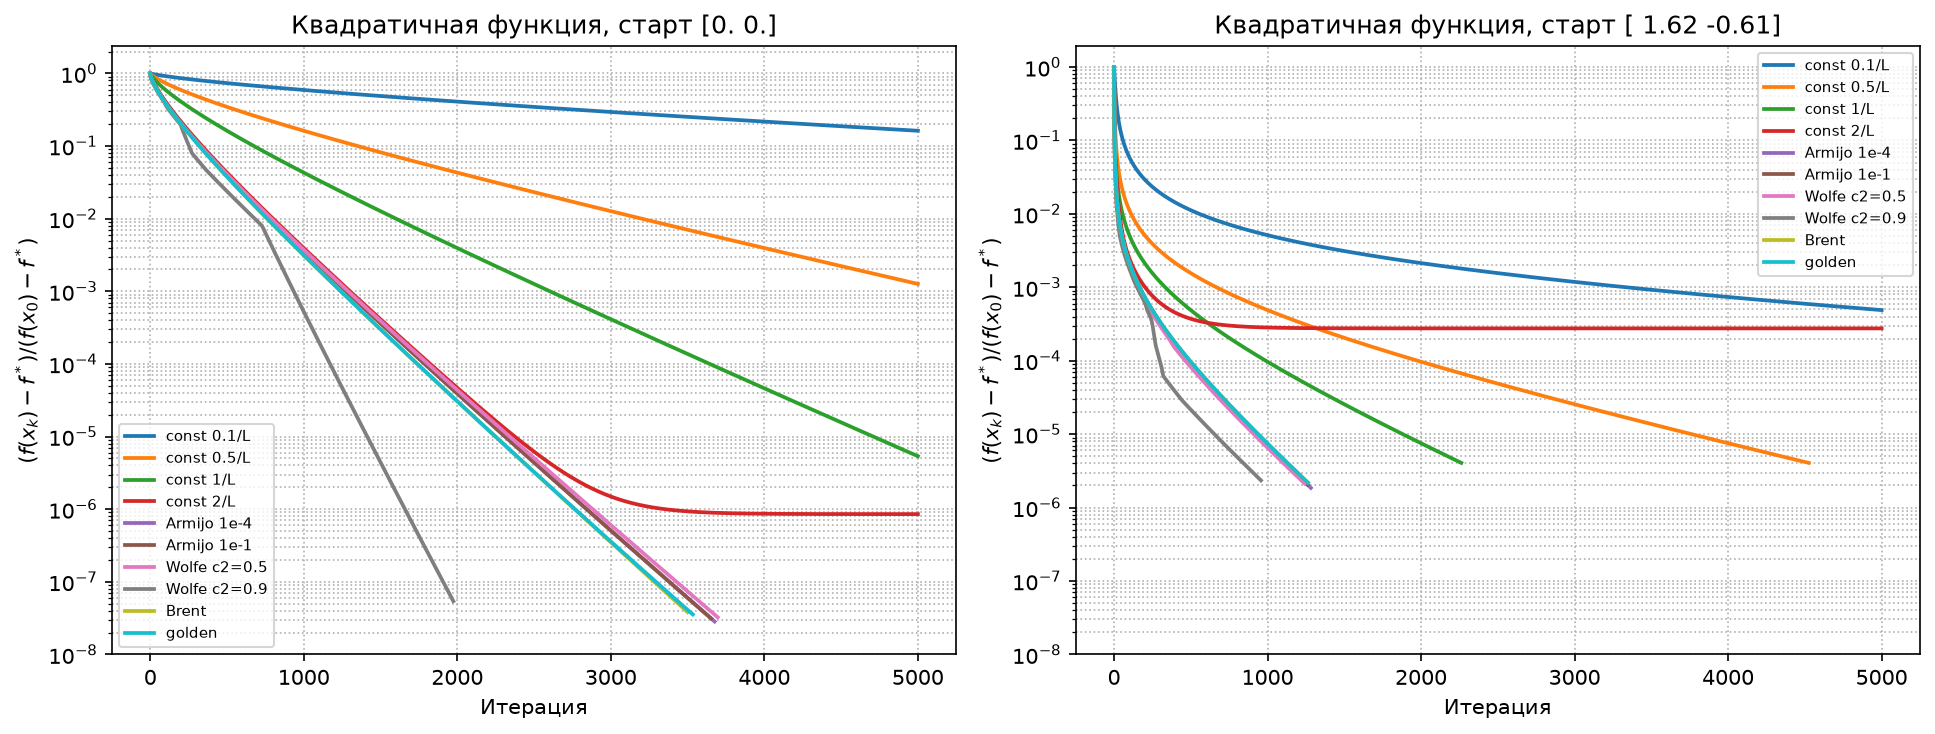

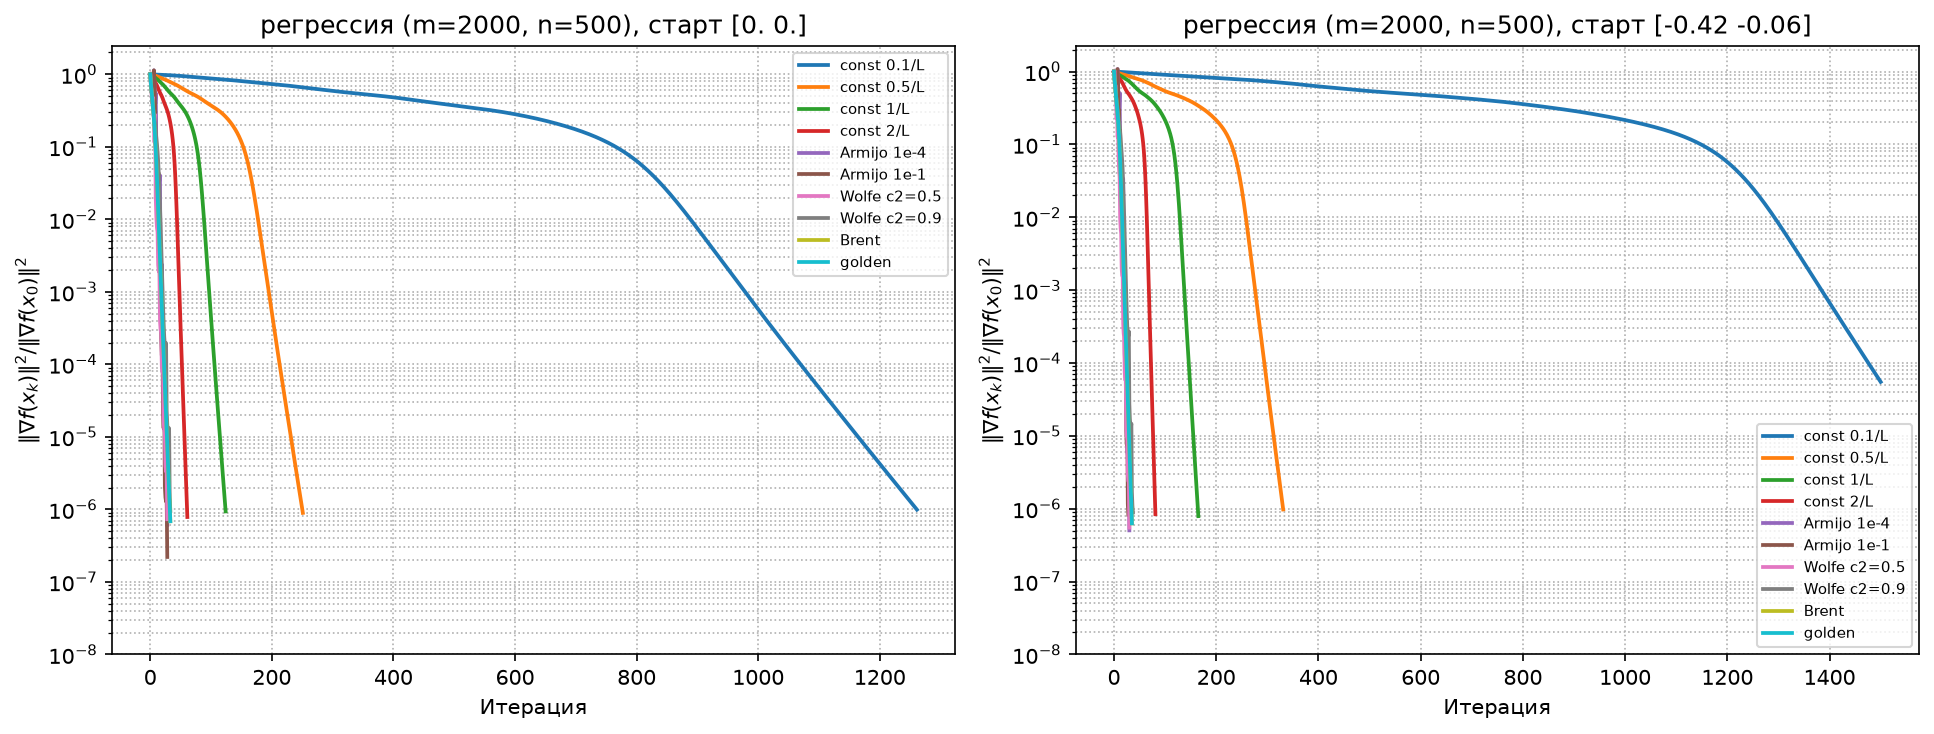

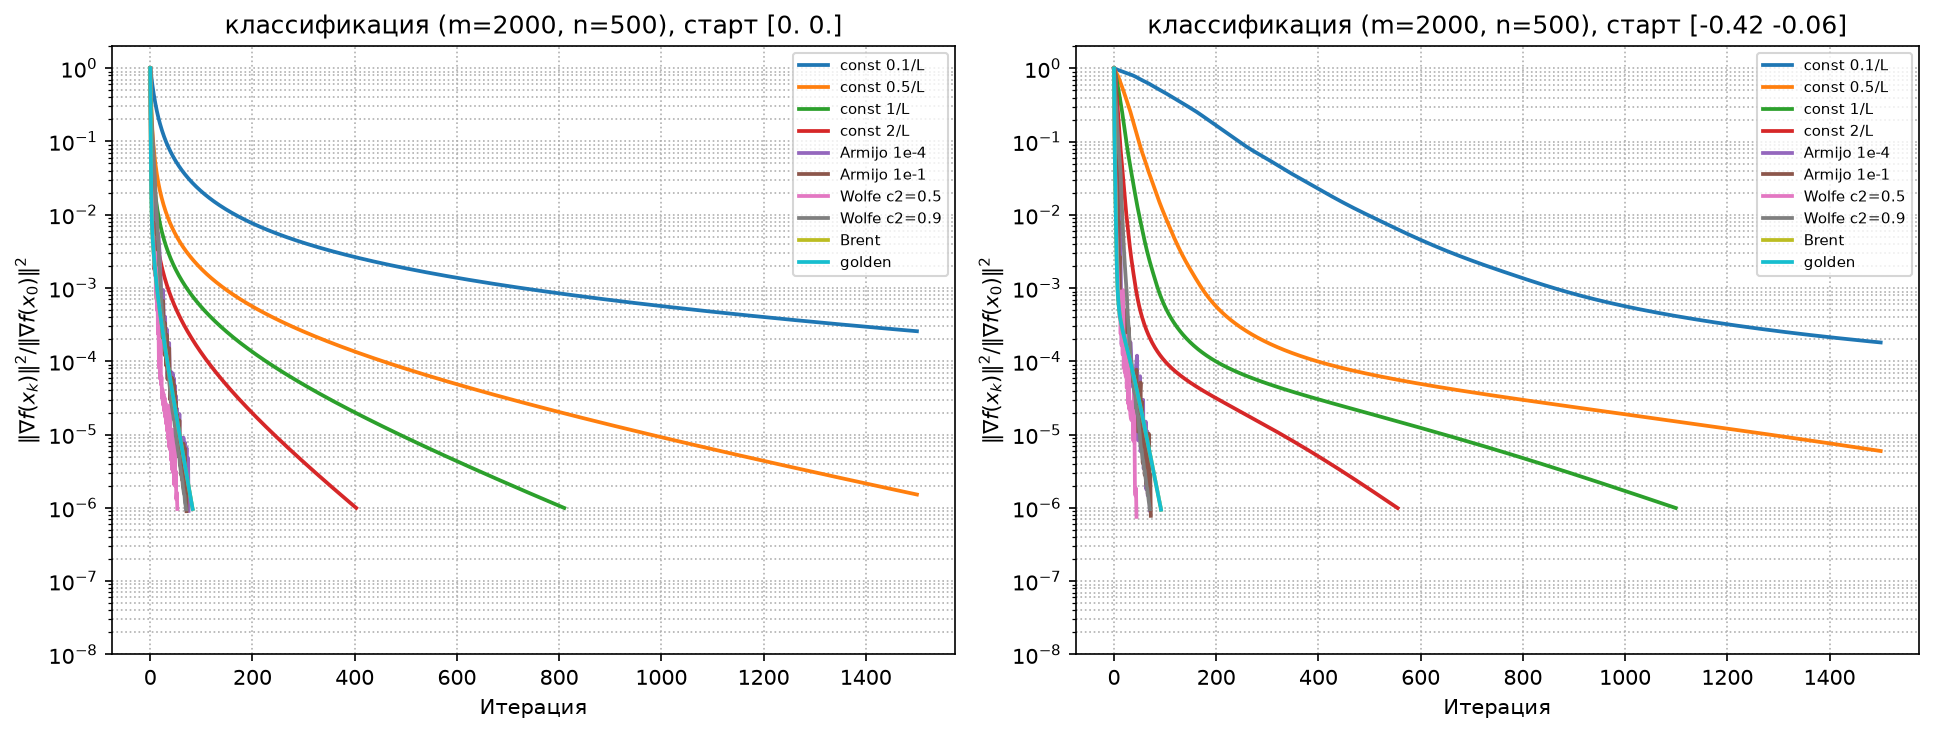

L (регрессия) = 2.24, L (классификация) = 0.56

Среднее время, с (по двум стартам):
              квадратичная  регрессия  классификация
Armijo 1e-1         0.1527     0.0366         0.1022
Armijo 1e-4         0.1537     0.0390         0.1086
Brent               0.4042     0.0815         0.2775
Wolfe c2=0.5        0.5508     0.0689         0.2129
Wolfe c2=0.9        0.3211     0.0782         0.2820
const 0.1/L         0.1016     0.6868         0.7612
const 0.5/L         0.0971     0.1461         0.7662
const 1/L           0.0736     0.0708         0.5019
const 2/L           0.1018     0.0329         0.2586
golden              1.1505     0.1708         0.5328

Среднее число вызовов оракула:
              квадратичная  регрессия  классификация
Armijo 1e-1        14752.0      169.5          426.0
Armijo 1e-4        14884.0      176.0          432.0
Brent              30424.0      443.0         1339.5
Wolfe c2=0.5       37059.5      282.5          831.0
Wolfe c2=0.9       21672.0      323.

In [15]:
def exp4_quad(n=1000, kappa=1000.0, tol=1e-8, max_iter=5000):
    oracle, f_star = quad_exp4(n, kappa, seed=0)
    starts = [np.zeros(n), np.random.RandomState(1).randn(n)]
    L = kappa
    results = {}
    rows = []
    fig, axes = plt.subplots(1, len(starts), figsize=(6.5 * len(starts), 5.0))
    if len(starts) == 1:
        axes = [axes]
    for ax, x0 in zip(axes, starts):
        f0 = oracle.func(x0)
        for label, opts in tools(L):
            rec = run_one(lambda: oracle, x0, opts, 'GD', tol, max_iter)
            rel = (np.asarray(rec['hist']['func']) - f_star) / (f0 - f_star)
            ax.semilogy(np.arange(len(rel)), np.maximum(rel, 1e-16), lw=1.8, label=label)
            results[(label, str(np.round(x0[:2], 3)))] = rec
            rows.append([label, str(np.round(x0[:2], 2)), rec['msg'],
                         len(rec['hist']['func']) - 1, rec['total_calls'],
                         rec['time']])
        ax.set_xlabel('Итерация')
        ax.set_ylabel(r'$(f(x_k)-f^*)/(f(x_0)-f^*)$')
        ax.set_title('Квадратичная функция, старт {}'.format(np.round(x0[:2], 2)))
        ax.set_ylim(bottom=1e-8)
        ax.grid(True, which='both', ls=':')
        ax.legend(fontsize=7)
    fig.tight_layout()
    savefig('exp4_quadratic')
    plt.close(fig)
    return results, rows


def exp4_ml(task, m=2000, n=500, tol=1e-6, max_iter=1500,
                exact_max_iter=300, seed=0):
    A, b, _ = make_data(task, m=m, n=n, seed=seed)
    regcoef = 1.0 / m
    L = L_est(A, task, regcoef)
    loss_name = 'pseudohuber' if task == 'regression' else 'logistic'

    def factory():
        return create_linear_model_oracle(A, b, regcoef, loss_name)

    rng = np.random.RandomState(2)
    starts = [np.zeros(n), rng.randn(n)]
    results = {}
    rows = []
    fig, axes = plt.subplots(1, len(starts), figsize=(6.5 * len(starts), 5.0))
    if len(starts) == 1:
        axes = [axes]
    for ax, x0 in zip(axes, starts):
        for label, opts in tools(L):
            mi = exact_max_iter if opts.get('method') in ('Brent', 'Golden') else max_iter
            rec = run_one(factory, x0, opts, 'GD', tol, mi)
            gn = np.asarray(rec['hist']['grad_norm'])
            ax.semilogy(np.arange(len(gn)), np.maximum(gn ** 2 / gn[0] ** 2, 1e-16),
                        lw=1.8, label=label)
            results[(label, str(np.round(x0[:2], 3)))] = rec
            rows.append([label, str(np.round(x0[:2], 2)), rec['msg'],
                         len(rec['hist']['func']) - 1, rec['total_calls'],
                         rec['time']])
        ax.set_xlabel('Итерация')
        ax.set_ylabel(r'$\|\nabla f(x_k)\|^2/\|\nabla f(x_0)\|^2$')
        ax.set_title('{} (m={}, n={}), старт {}'.format(TASK_RU.get(task, task), m, n, np.round(x0[:2], 2)))
        ax.set_ylim(bottom=1e-8)
        ax.grid(True, which='both', ls=':')
        ax.legend(fontsize=7)
    fig.tight_layout()
    savefig('exp4_' + task)
    plt.close(fig)
    return results, rows, L


if 4 in RUN:
    res4q, rows4q = exp4_quad()
    res4r, rows4r, L_reg = exp4_ml('regression')
    res4c, rows4c, L_cls = exp4_ml('classification')
    import pandas as pd
    print('L (регрессия) = {:.2f}, L (классификация) = {:.2f}'.format(L_reg, L_cls))
    display(pd.DataFrame(rows4q, columns=['стратегия', 'старт', 'сообщение', 'iter', 'вызовы', 'время']))
    display(pd.DataFrame(rows4r, columns=['стратегия', 'старт', 'сообщение', 'iter', 'вызовы', 'время']))
    display(pd.DataFrame(rows4c, columns=['стратегия', 'старт', 'сообщение', 'iter', 'вызовы', 'время']))

    def mean_col(rows, col):
        return pd.Series([r[col] for r in rows], index=[r[0] for r in rows]).groupby(level=0).mean()

    time_table = pd.DataFrame({
        'квадратичная': mean_col(rows4q, 5),
        'регрессия': mean_col(rows4r, 5),
        'классификация': mean_col(rows4c, 5),
    })
    print('\nСреднее время, с (по двум стартам):')
    print(time_table.round(4).to_string())
    calls_table = pd.DataFrame({
        'квадратичная': mean_col(rows4q, 4),
        'регрессия': mean_col(rows4r, 4),
        'классификация': mean_col(rows4c, 4),
    })
    print('\nСреднее число вызовов оракула:')
    print(calls_table.round(1).to_string())
else:
    print('Эксперимент 4 пропущен')

### Эксперимент 4: ваш ответ

На графиках сразу видно, что Вульф, Армихо и точный поиск обгоняют константный шаг по числу итераций, но по времени картина уже не такая однозначная. Для ML-моделей ($m=2000$, $n=500$, $\lambda=1/m$) оценка $L$ получилась около 2.2 для регрессии и 0.56 для классификации. На ML-моделях Армихо, Вульф и точный поиск сходятся примерно за 30–90 итераций.

При $\alpha=0.1/L$ на регрессии GD const делает больше тысячи итераций, при $0.5/L$ и $1/L$ быстрее, а при $2/L$ на квадратичной функции за 5000 итераций так и не сходится. На классификации $2/L$ оказался устойчивее и быстрее, чем $1/L$.

Точный поиск на квадратичной функции сам по себе не ускоряет GD: там всё равно тысячи итераций, а на ML-моделях каждое вычисление $\phi(\alpha)$ стоит $O(\mathrm{nnz}(A))$. По таблице Брент и golden часто проигрывают Армихо и по времени, и по числу вызовов оракула, а итераций у них не меньше. В итоге в общем случае я бы выбирал Армихо или Вульфа, константный шаг, когда есть хорошая оценка $L$, а точный поиск, когда задача маленькая или обращения к оракулу бесплатные.

## Эксперимент 5. Стратегия выбора длины шага в методе Ньютона

Повторите эксперимент 4 для метода Ньютона на ML-моделях вашего варианта (модельные данные).

Дополнительно для каждой стратегии зафиксируйте номер итерации, начиная с которой шаг $\alpha = 1$ принимается всегда, т. е. момент входа в зону квадратичной сходимости. Как ведёт себя $\|\nabla f(x_k)\|$ после этого момента? Проверьте численно, что $\|\nabla f(x_{k+1})\| \approx C \|\nabla f(x_k)\|^2$.

### Вопросы для отчёта
1. Какая стратегия работает лучше всего?
2. Почему для метода Ньютона единичный шаг является приоритетным?
3. На какой итерации метод входит в зону квадратичной сходимости и как это видно на графиках?

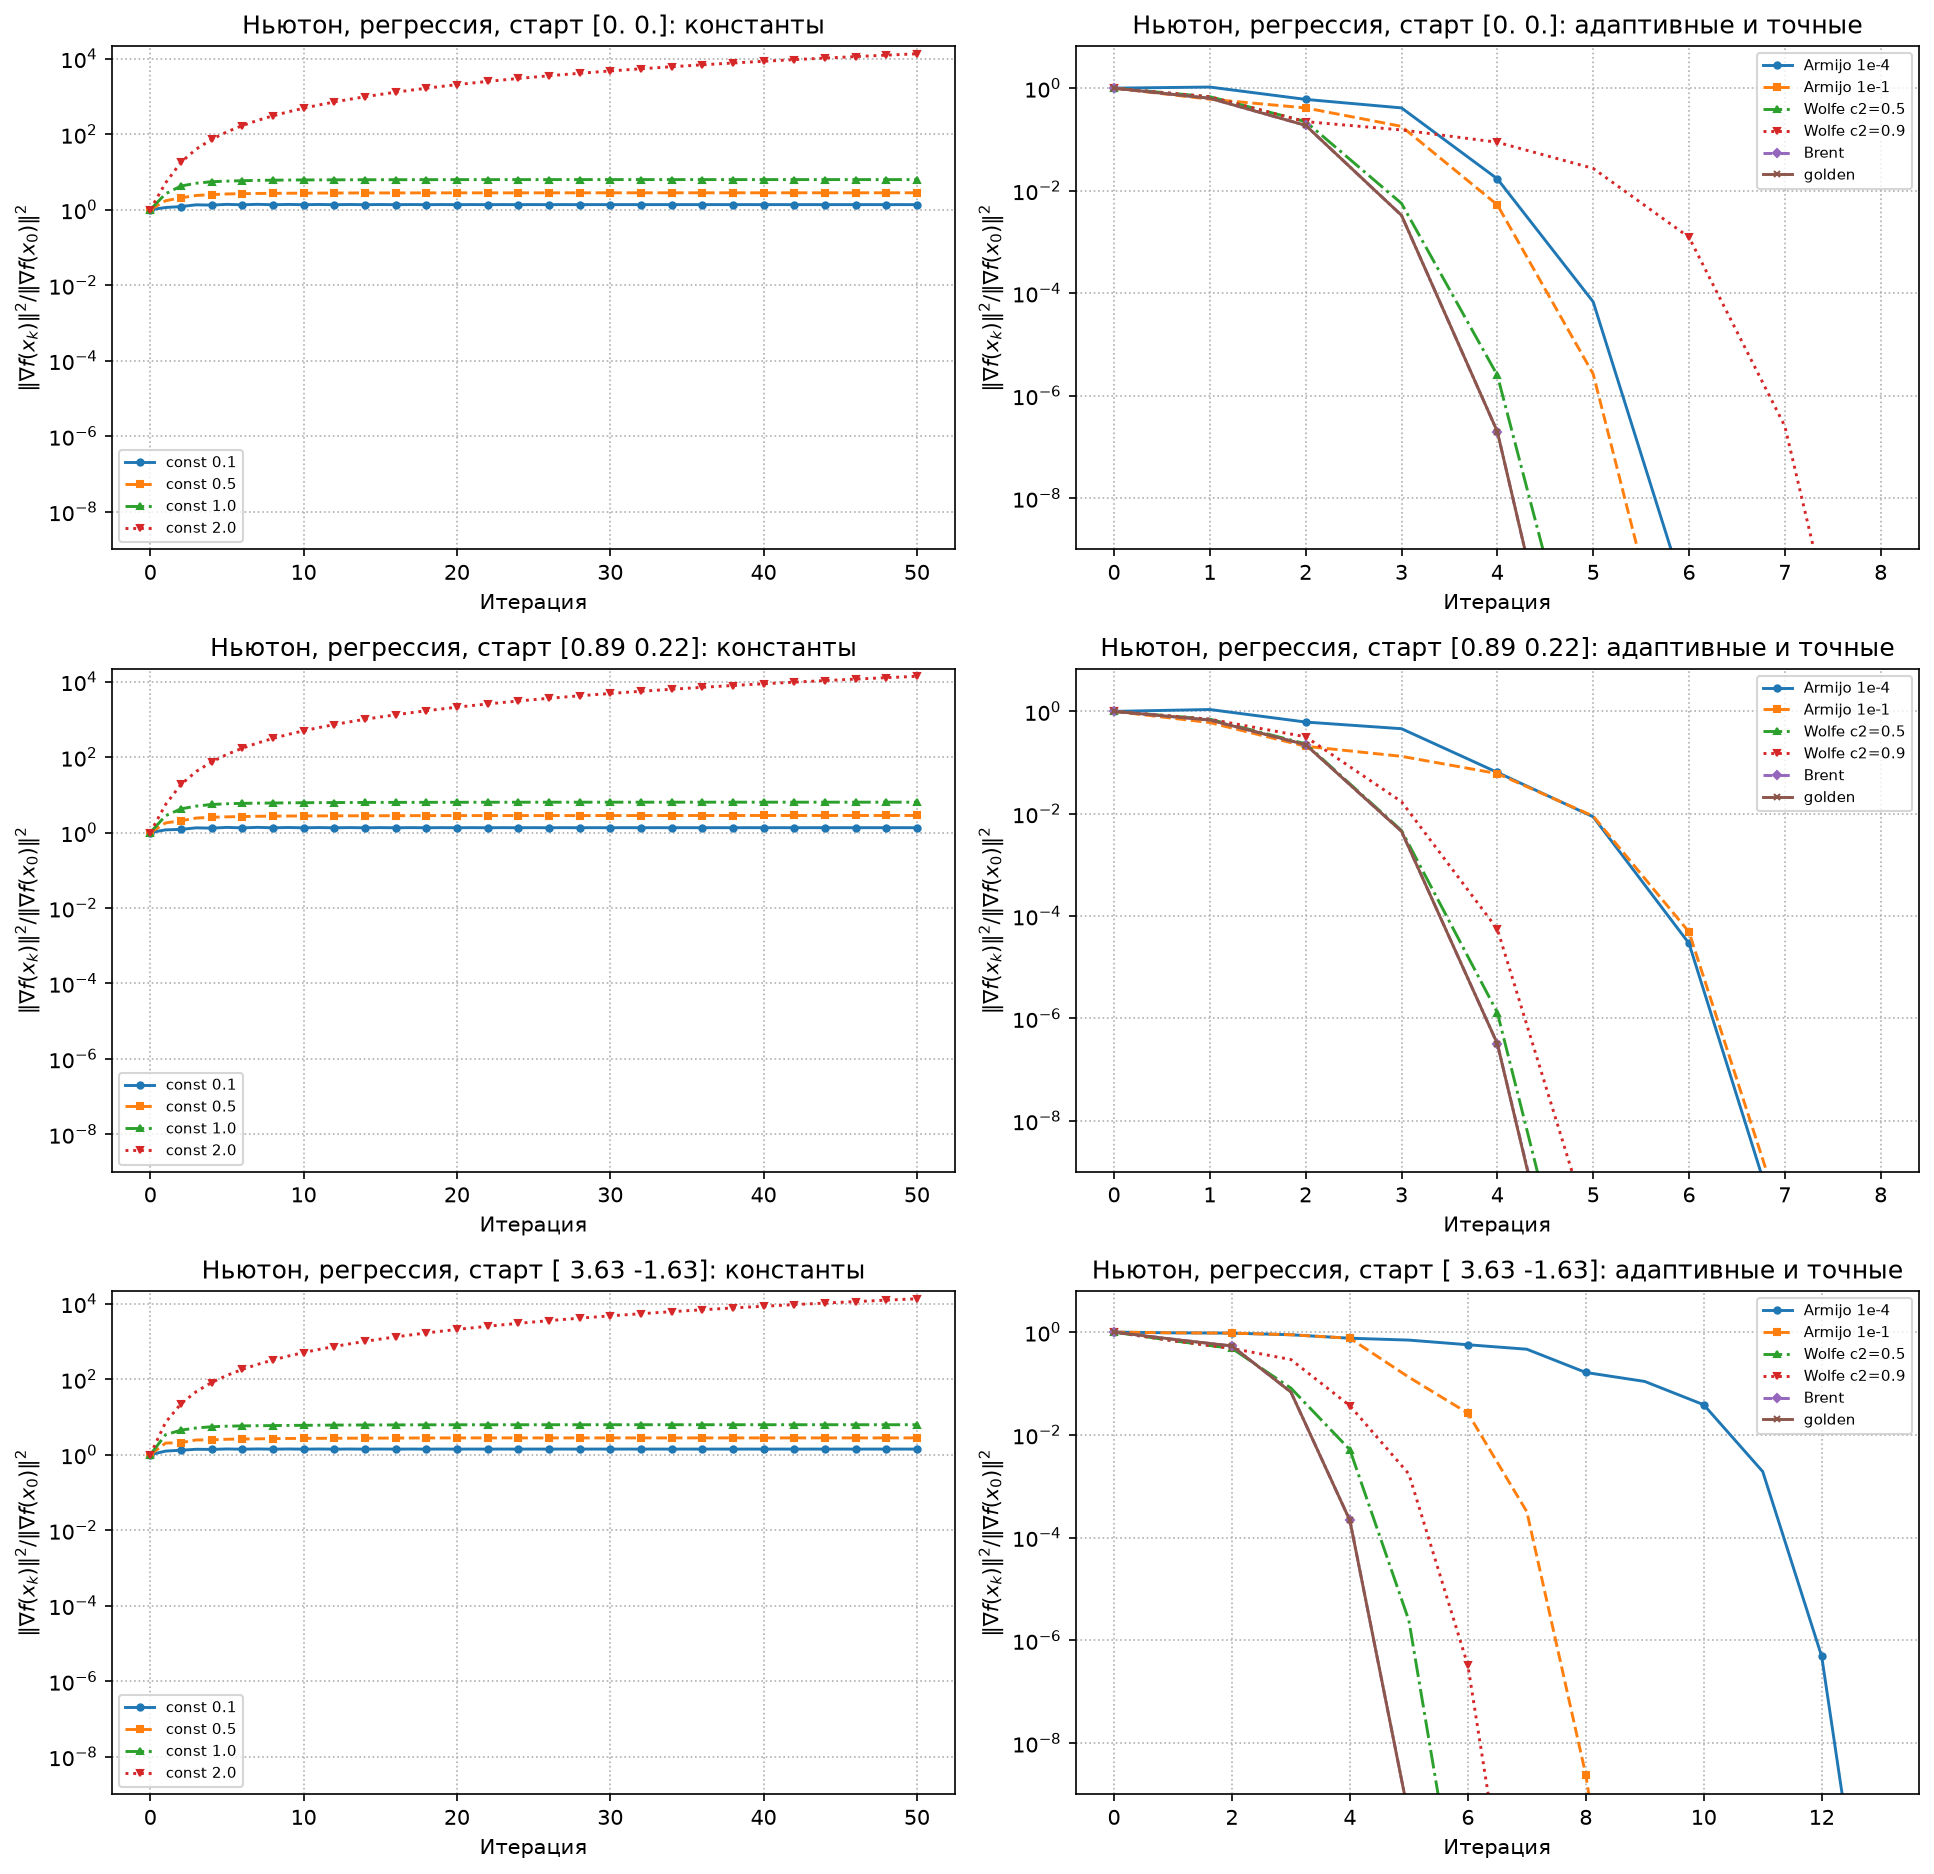

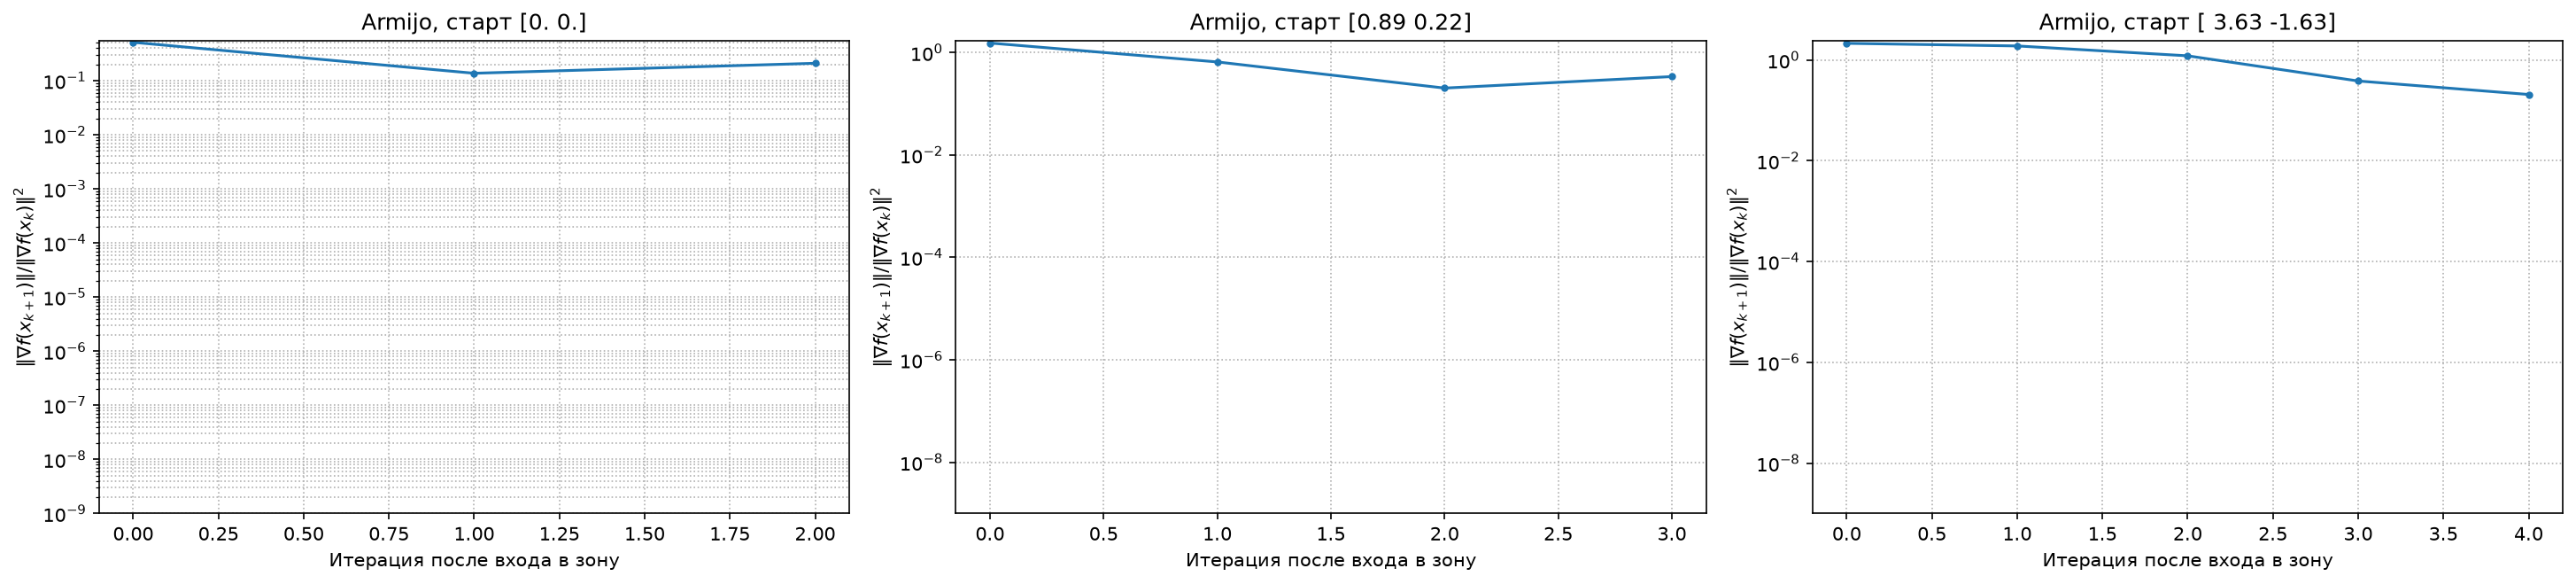

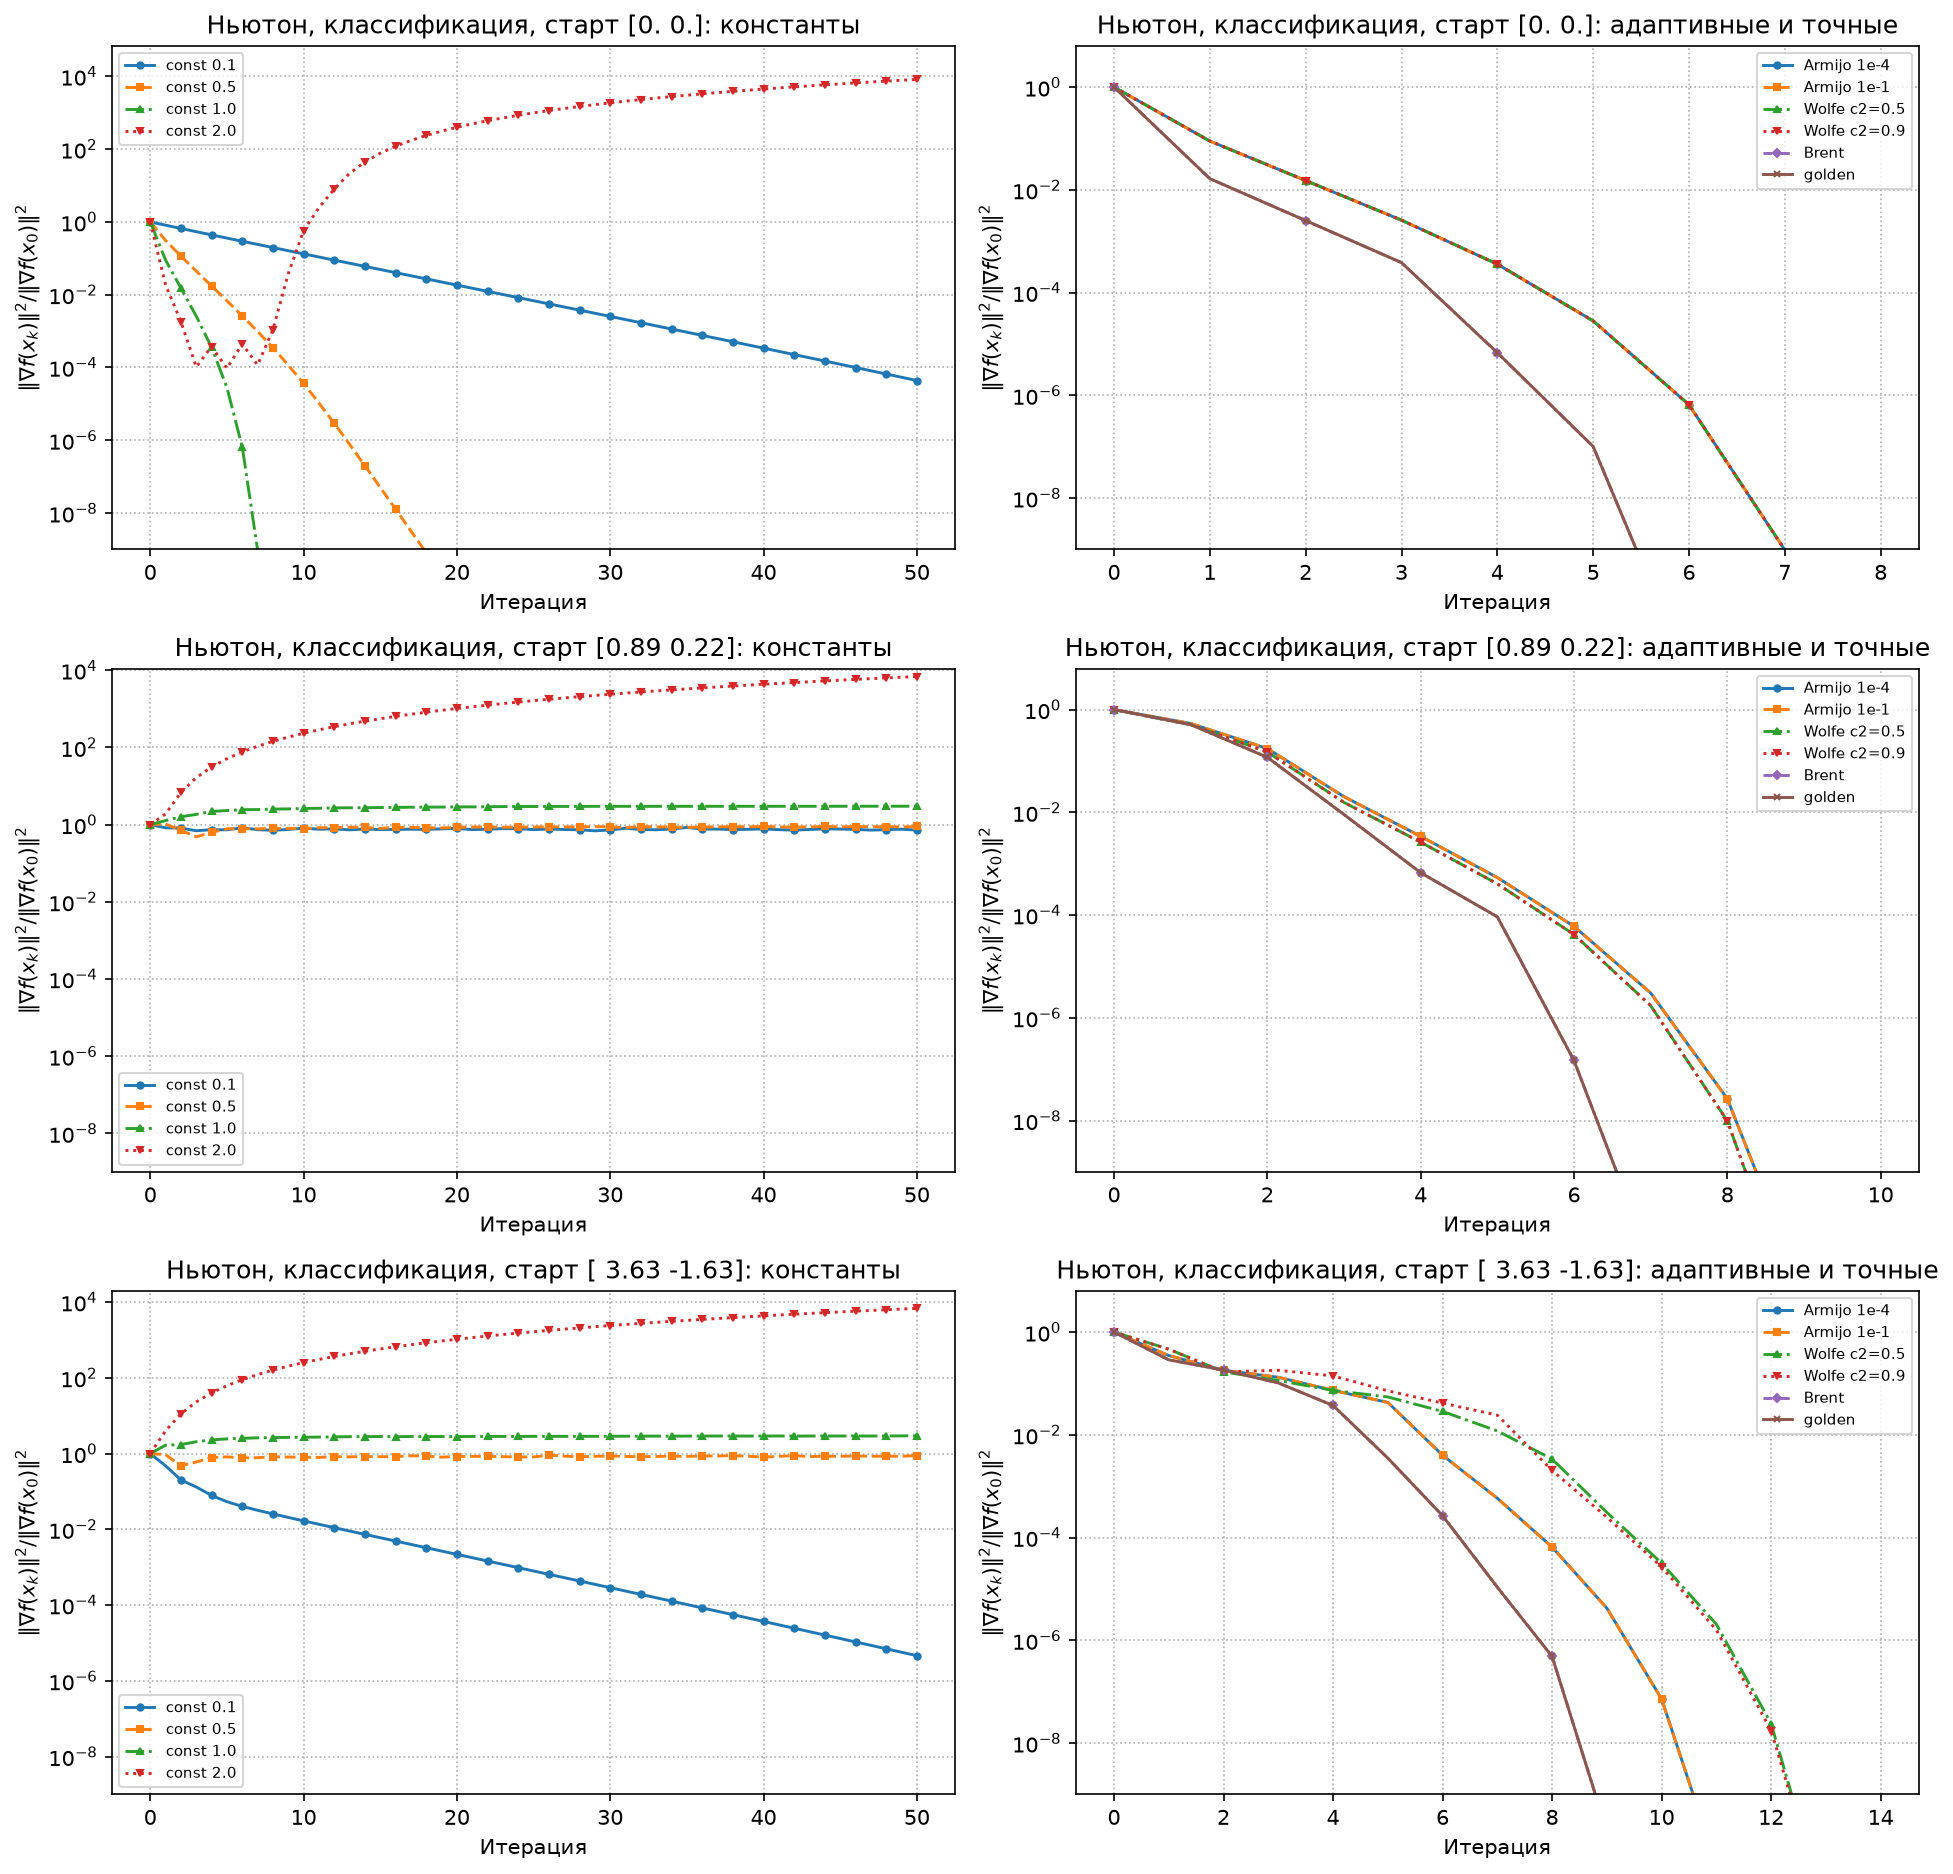

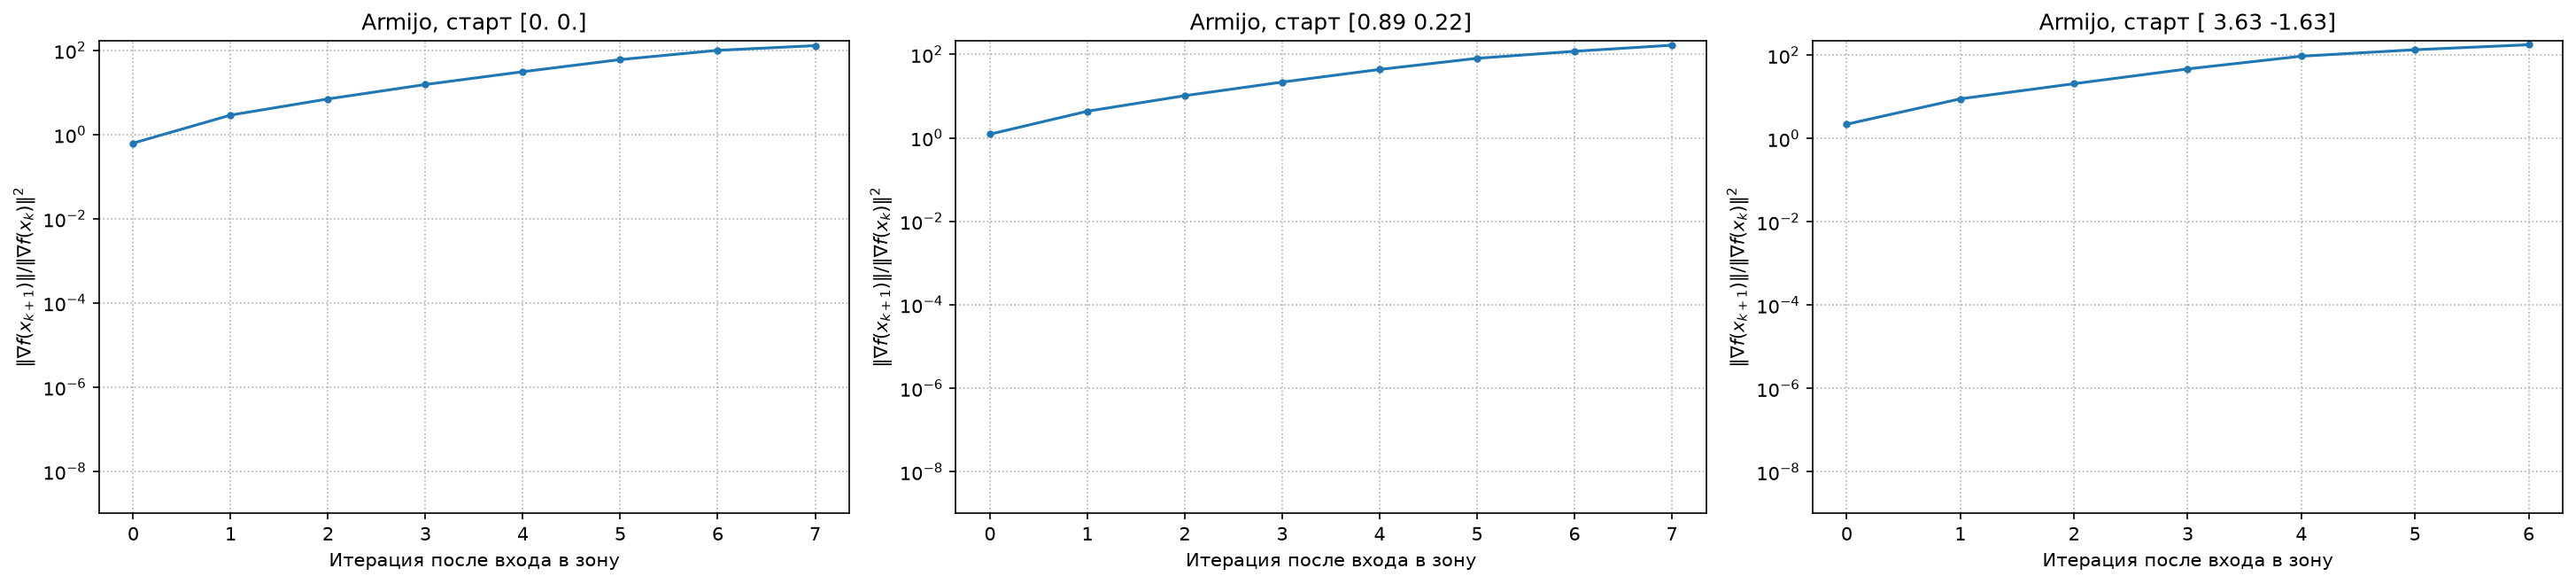

L (регрессия) = 2.24, L (классификация) = 0.56


In [16]:
def exp5(task, m=2000, n=500, tol=1e-12, max_iter=50, seed=0):
    A, b, _ = make_data(task, m=m, n=n, seed=seed)
    regcoef = 1.0 / m
    L = L_est(A, task, regcoef)
    loss_name = 'pseudohuber' if task == 'regression' else 'logistic'

    def factory():
        return create_linear_model_oracle(A, b, regcoef, loss_name)

    rng = np.random.RandomState(3)
    starts = [np.zeros(n), 0.5 * rng.randn(n), 2.0 * rng.randn(n)]
    results = {}
    rows = []
    fig, axes = plt.subplots(len(starts), 2, figsize=(13, 4.2 * len(starts)))
    styles = ['-', '--', '-.', ':', (0, (3, 1, 1, 1))]
    markers = ['o', 's', '^', 'v', 'D', 'x', '+', '*', 'p', 'h']
    for row, x0 in enumerate(starts):
        for col, group in enumerate(['const', 'other']):
            ax = axes[row, col]
            j = 0
            for label, opts in newton_tools():
                is_const = label.startswith('const')
                if (group == 'const') != is_const:
                    continue
                rec = run_one(factory, x0, opts, 'Newton', tol, max_iter)
                gn = np.asarray(rec['hist']['grad_norm'])
                ax.semilogy(np.arange(len(gn)), np.maximum(gn ** 2 / gn[0] ** 2, 1e-16),
                            lw=1.4, linestyle=styles[j % len(styles)],
                            marker=markers[j % len(markers)], markevery=2, ms=3,
                            label=label)
                alphas = np.asarray(rec['hist'].get('alpha', []))
                entry = None
                for k in range(len(alphas)):
                    if np.all(np.abs(alphas[k:] - 1.0) < 1e-12):
                        entry = k
                        break
                ratios = []
                if entry is not None:
                    for k in range(entry, len(gn) - 1):
                        if gn[k] > 1e-10:
                            ratios.append(gn[k + 1] / gn[k] ** 2)
                rec['entry_iter'] = entry
                rec['ratios'] = ratios
                results[(label, str(np.round(x0[:2], 3)))] = rec
                rows.append([label, str(np.round(x0[:2], 2)), rec['msg'],
                             len(rec['hist']['func']) - 1, entry,
                             ratios[-1] if ratios else np.nan,
                             rec['total_calls'], rec['time']])
                j += 1
            ax.set_xlabel('Итерация')
            ax.set_ylabel(r'$\|\nabla f(x_k)\|^2/\|\nabla f(x_0)\|^2$')
            group_name = 'константы' if group == 'const' else 'адаптивные и точные'
            ax.set_title('Ньютон, {}, старт {}: {}'.format(
                TASK_RU.get(task, task), np.round(x0[:2], 2), group_name))
            ax.set_ylim(bottom=1e-9)
            ax.grid(True, which='both', ls=':')
            ax.legend(fontsize=7)
    fig.tight_layout()
    savefig('exp5_' + task)
    plt.close(fig)

    fig, axes = plt.subplots(1, len(starts), figsize=(6.5 * len(starts), 4.5))
    if len(starts) == 1:
        axes = [axes]
    for ax, x0 in zip(axes, starts):
        rec = results[('Armijo 1e-4', str(np.round(x0[:2], 3)))]
        ratios = rec['ratios']
        if ratios:
            ax.semilogy(np.arange(len(ratios)), np.maximum(ratios, 1e-300), '-o', ms=3)
            ax.set_title('Armijo, старт {}'.format(np.round(x0[:2], 2)))
        else:
            ax.set_title('Armijo, старт {}: зона не достигнута'.format(np.round(x0[:2], 2)))
        ax.set_xlabel('Итерация после входа в зону')
        ax.set_ylabel(r'$\|\nabla f(x_{k+1})\| / \|\nabla f(x_k)\|^2$')
        ax.set_ylim(bottom=1e-9)
        ax.grid(True, which='both', ls=':')
    fig.tight_layout()
    savefig('exp5_ratios_' + task)
    plt.close(fig)
    return results, rows, L


if 5 in RUN:
    res5r, rows5r, L5r = exp5('regression')
    res5c, rows5c, L5c = exp5('classification')
    import pandas as pd
    print('L (регрессия) = {:.2f}, L (классификация) = {:.2f}'.format(L5r, L5c))
    display(pd.DataFrame(rows5r, columns=['стратегия', 'старт', 'сообщение', 'iter',
                                          'вход', 'последнее отношение', 'вызовы', 'время']))
    display(pd.DataFrame(rows5c, columns=['стратегия', 'старт', 'сообщение', 'iter',
                                          'вход', 'последнее отношение', 'вызовы', 'время']))
else:
    print('Эксперимент 5 пропущен')

### Эксперимент 5: ваш ответ

По числам лучше всего выглядят golden и Brent: на регрессии они делают 5–6 итераций из всех стартов, на классификации — 7–10. Армихо и Вульф близко (5–14), но из далёкого старта Армихо тратит больше. Константа $\alpha=1$ на классификации из $x_0=0$ сходится за 8 итераций, но на регрессии и из далёких точек за 50 не успевает, $0.1$ и $0.5$ медленные, а $2$ уходит вверх. Для регресии $2$ вообще ведет себя странно даже в точке $x_0=0$. И в целом константа в отдалении от  У golden и Brent меньше итераций, но больше вызовов оракула и времени, и они не обязаны выбирать $\alpha=1$, поэтому для Ньютона это не первый выбор.

Почему единичный шаг: локальная квадратичная сходимость Ньютона мы на лекциях доказывали именно для $\alpha_k=1$. Вблизи оптимума квадратичная модель Тейлора хорошо аппроксимирует функцию, и полный ньютоновский шаг сам попадает в хорошую зону, поэтому линейный поиск должен сначала пробовать единицу, и если не подошло уменьшать.

Вход в зону видно так: у константы $\alpha=1$ шаг единичный с самого начала, но асимптотика включается не сразу — первые итерации метод ещё прощупывает точку. У Армихо и Вульфа через несколько итераций шаг становится равен 1 и дальше не меняется, чем дальше старт, тем позже это происходит.

## Эксперимент 6. Влияние регуляризации на обусловленность и скорость сходимости

Коэффициент $\lambda$ напрямую задаёт константу сильной выпуклости: чем он больше, тем лучше обусловлена задача, но тем дальше её минимум от минимума нерегуляризованной функции.

**Порядок проведения.**
1. Для каждой модели вашего варианта возьмите датасет с наибольшим числом признаков $n$, на котором метод Ньютона помещается в память, и зафиксируйте начальную точку $x_0$.
2. Запустите градиентный спуск и метод Ньютона для $\lambda \in \{10^{-5}, 10^{-4}, 10^{-3}, 10^{-2}, 0.1, 1, 10\}$.
3. Постройте графики:
   * число итераций до сходимости от $\lambda$ (отдельные кривые для градиентного спуска и метода Ньютона);
   * время работы до сходимости от $\lambda$;
   * норма решения $\|x^*\|_2$ от $\lambda$.
4. Сравните, для какой функции потерь (регрессионной или классификационной) изменение $\lambda$ сильнее влияет на устойчивость метода Ньютона.

### Вопросы для отчёта
1. Как меняется число итераций методов при $\lambda \to 0$ и почему?
2. Возникала ли численная неустойчивость при некоторых $\lambda$? Если да, почему и как вы её устранили?
3. Как $\lambda$ влияет на ширину зоны квадратичной сходимости метода Ньютона?
4. Наблюдается ли плато в числе итераций при больших $\lambda$? Почему?

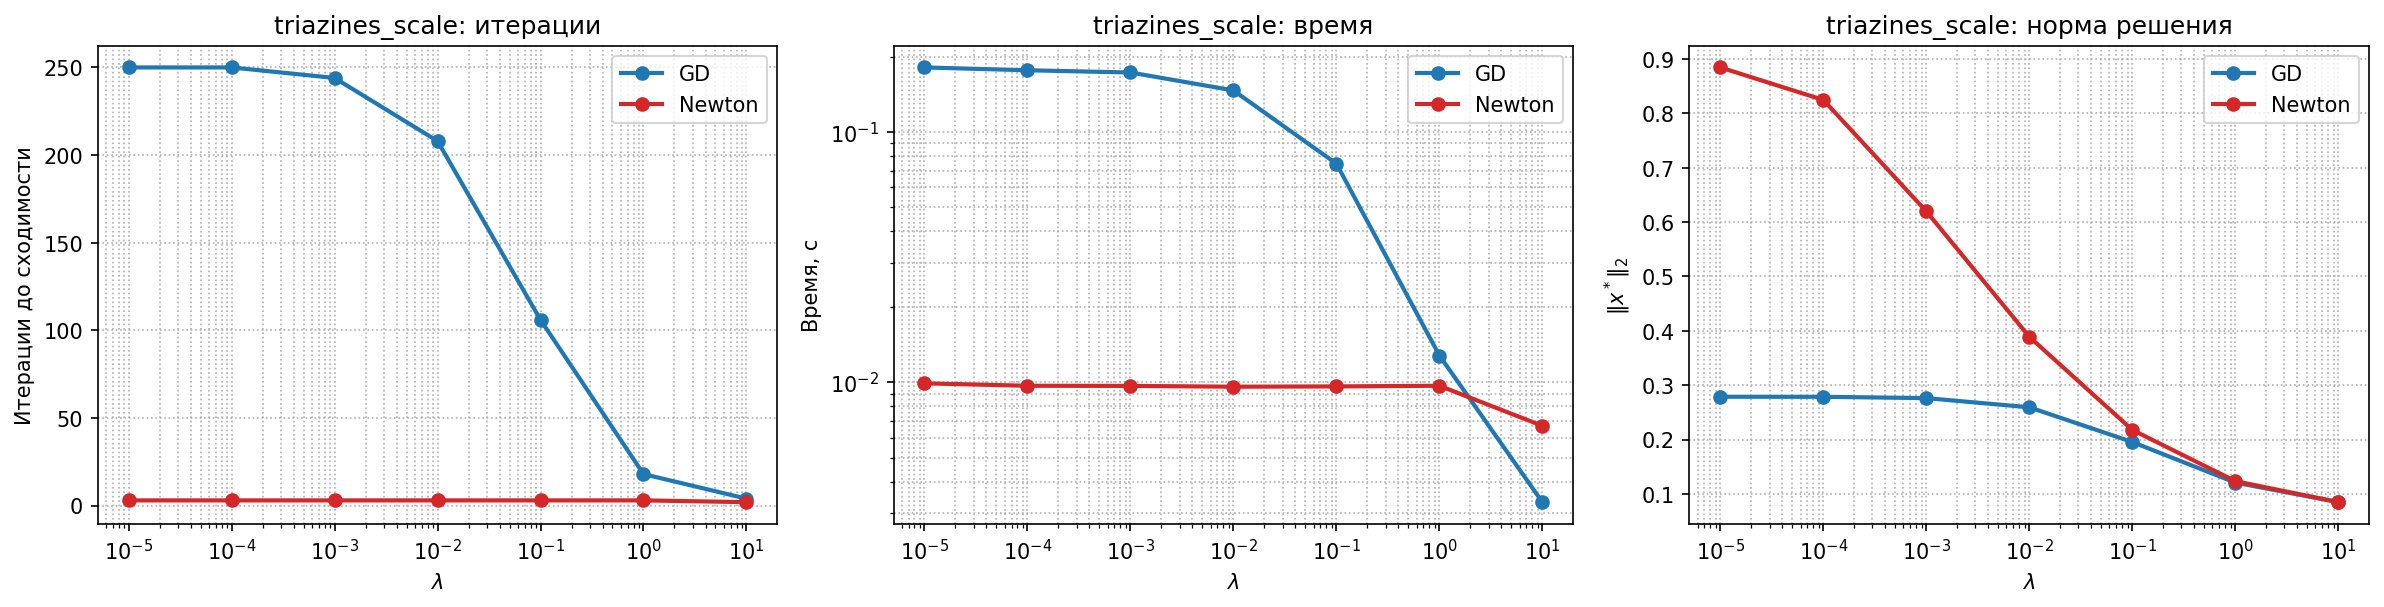

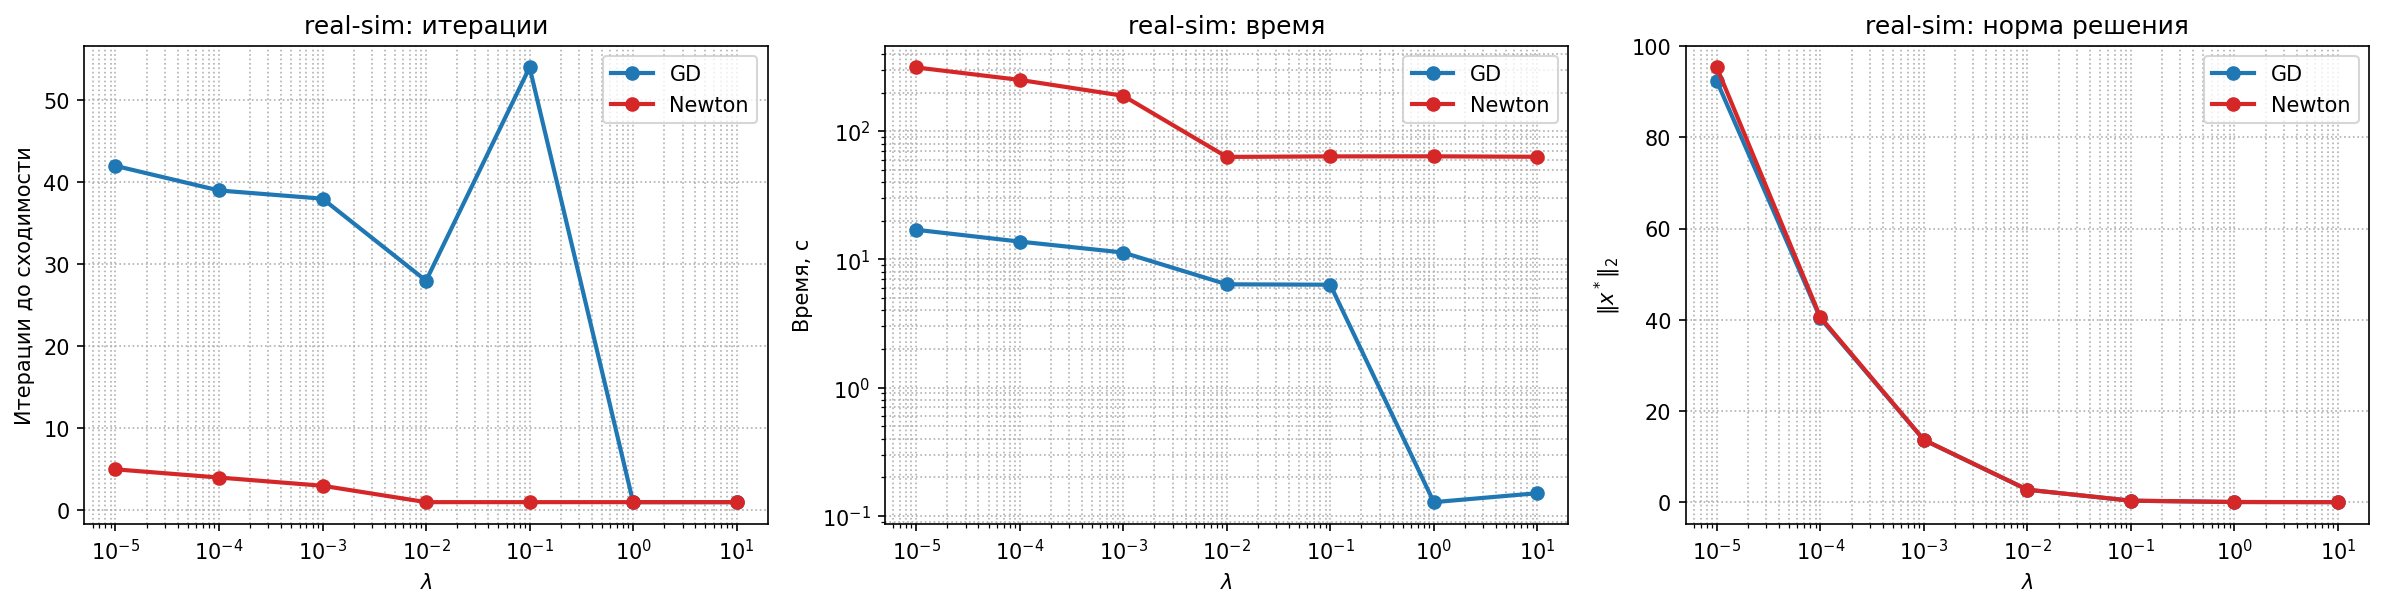

In [17]:
def exp6(max_iter_gd=5000, max_iter_newton=100, tol=1e-5):
    configs = [
        ('pseudohuber', 'triazines_scale', False, 'regression'),
        ('logistic', 'real-sim.bz2', False, 'classification'),
    ]
    lambdas = [1e-5, 1e-4, 1e-3, 1e-2, 0.1, 1.0, 10.0]
    rows = []
    for loss_name, data_name, scale, task in configs:
        A, b = load_data(data_name, scale=scale)
        if task == 'classification':
            b = to_pm1(b)
        m, n = A.shape
        results = {'GD': [], 'Newton': []}
        for lam in lambdas:
            oracle = create_linear_model_oracle(A, b, lam, loss_name)
            x0 = np.zeros(n)
            for method, runner, max_iter in [
                    ('GD', gradient_descent, max_iter_gd),
                    ('Newton', newton, max_iter_newton)]:
                t = time.time()
                x_star, msg, h = runner(oracle, x0, tolerance=tol,
                                        max_iter=max_iter, trace=True)
                elapsed = time.time() - t
                results[method].append(dict(lam=lam, msg=msg,
                                            iterations=len(h['func']) - 1,
                                            time=elapsed,
                                            x_norm=np.linalg.norm(x_star),
                                            grad_norm=h['grad_norm'][-1]))
                rows.append([loss_name, data_name.replace('.bz2', ''), lam, method,
                             msg, len(h['func']) - 1, elapsed,
                             np.linalg.norm(x_star), h['grad_norm'][-1]])

        fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
        for method, color in [('GD', 'C0'), ('Newton', 'C3')]:
            it = [r['iterations'] if r['msg'] == 'success' else np.nan
                  for r in results[method]]
            tm = [r['time'] if r['msg'] == 'success' else np.nan
                  for r in results[method]]
            xn = [r['x_norm'] if r['msg'] == 'success' else np.nan
                  for r in results[method]]
            axes[0].plot(lambdas, it, '-o', color=color, lw=2, label=method)
            axes[1].loglog(lambdas, tm, '-o', color=color, lw=2, label=method)
            axes[2].semilogx(lambdas, xn, '-o', color=color, lw=2, label=method)
        axes[0].set_xscale('log')
        axes[0].set_xlabel(r'$\lambda$')
        axes[0].set_ylabel('Итерации до сходимости')
        axes[0].set_title('{}: итерации'.format(data_name.replace('.bz2', '')))
        axes[0].grid(True, which='both', ls=':')
        axes[0].legend()
        axes[1].set_xlabel(r'$\lambda$')
        axes[1].set_ylabel('Время, с')
        axes[1].set_title('{}: время'.format(data_name.replace('.bz2', '')))
        axes[1].grid(True, which='both', ls=':')
        axes[1].legend()
        axes[2].set_xlabel(r'$\lambda$')
        axes[2].set_ylabel(r'$\|x^*\|_2$')
        axes[2].set_title('{}: норма решения'.format(data_name.replace('.bz2', '')))
        axes[2].grid(True, which='both', ls=':')
        axes[2].legend()
        fig.tight_layout()
        savefig('exp6_' + loss_name)
        plt.close(fig)
    return rows


if 6 in RUN:
    rows_exp6 = exp6()
    import pandas as pd
    display(pd.DataFrame(rows_exp6, columns=['функция потерь', 'датасет', 'lambda', 'метод',
                                             'сообщение', 'итерации', 'время',
                                             '||x||', '||grad||']))
else:
    print('Эксперимент 6 пропущен')

### Эксперимент 6: ваш ответ

Брал triazines_scale для Pseudo-Huber ($n=60$) и real-sim для логистической регрессии ($n=20958$): это самые широкие наборы, на которых Ньютон ещё помещается в память. Пик памяти был около 14 ГБ. $\lambda$ перебирал по сетке от $10^{-5}$ до $10$.

На real-sim GD сделал около 40 итераций при малых $\lambda$, при $\lambda=0.1$ неожиданно прыгнул до 55, а при $\lambda=1$ и $10$ — одну-две. Ньютон прошёл путь от 5 итераций до одной. На triazines GD: около 250 итераций при $10^{-5}$, около 200 при $10^{-2}$ и меньше 20 при $\lambda=1$, Ньютон — 3–4. Общий тренд понятен: с ростом $\lambda$ итераций у GD становится меньше, у Ньютона почти не меняется. Честно говоря, всплеск при $\lambda=0.1$ я не до конца понял.

По времени на real-sim Ньютон при $\lambda=10^{-5}$ тратит около 6–7 минут, при больших $\lambda$ — около полутора минут. GD — от 20 секунд до примерно 1 секунды. То есть на широком датасете GD снова выигрывает по времени, хотя по итерациям Ньютон несопоставимо лучше. На triazines наоборот: Ньютон быстрее. Норма решения падает с ростом $\lambda$ (на real-sim примерно с 95 до 1, на triazines — с 0.9 до 0.1), это обычный shrinkage.

При $\lambda\to0$ гессиан становится плохо обусловленным: минимальное собственное значение порядка $\lambda$, максимальное задаёт $A$, поэтому $\kappa$ растёт как $1/\lambda$ и GD делает всё больше итераций. Ньютон по числу итераций почти не страдает, но матрица становится почти вырожденной. У меня на real-sim при $10^{-5}$ он ещё работал, `newton_direction_error` не было, просто долго. При больших $\lambda$ задача становится почти квадратичной, зона квадратичной сходимости заметно расширяется, и наступает плато: GD упирается в 1–2 итерации, Ньютон — в одну, потому что скорость уже определяется не обусловленностью, а начальной ошибкой. Логистическая регрессия на real-sim чувствительнее к $\lambda$, чем Pseudo-Huber на triazines, так как признаков больше, разброс собственных значений шире.

## Эксперимент 7. Исследовательская задача
В качестве следующего эксперимента, выберите один из двух, предложенных ниже

### Эксперимент 7: выбранный вариант

В этой работе выбран **эксперимент 7.2 (спектральный анализ гессиана)**. Вариант 7.1 (эвристики модификации гессиана) не реализовывался; ниже приведены условие 7.2, код и выводы.


### Эксперимент 7.1: эвристики модификации гессиана

Этот вариант в работе не выбран. Его идея — заменить неположительно определённый гессиан на близкий положительно определённый (сдвиг $H+\gamma I$ или усечение спектра), чтобы метод Ньютона не падал с `newton_direction_error`. Мы выбрали более простой и непосредственно связанный с экспериментом 6 вариант 7.2.


 ## Эксперимент 7.2 Спектральный анализ гессиана

Поведение градиентных методов определяется спектром гессиана, а метод Ньютона «выравнивает» этот спектр.

**Задание.**
1. На каждой 5-й итерации метода Ньютона (до сходимости) вычисляйте полный спектр гессиана (`scipy.linalg.eigvalsh`).
2. Постройте гистограммы спектра в начальной точке $x_0 = 0$ и в точке оптимума $x^*$.

Исследуйте, как L2-регуляризация $\lambda$ влияет на распределение спектра. Покажите на графиках, есть ли «спектральная щель» — отрыв почти нулевых собственных значений от ненулевых. Опишите эволюцию числа обусловленности $\kappa = \lambda_{\max} / \lambda_{\min}$ в процессе оптимизации и сопоставьте её с наблюдаемой скоростью градиентного спуска.


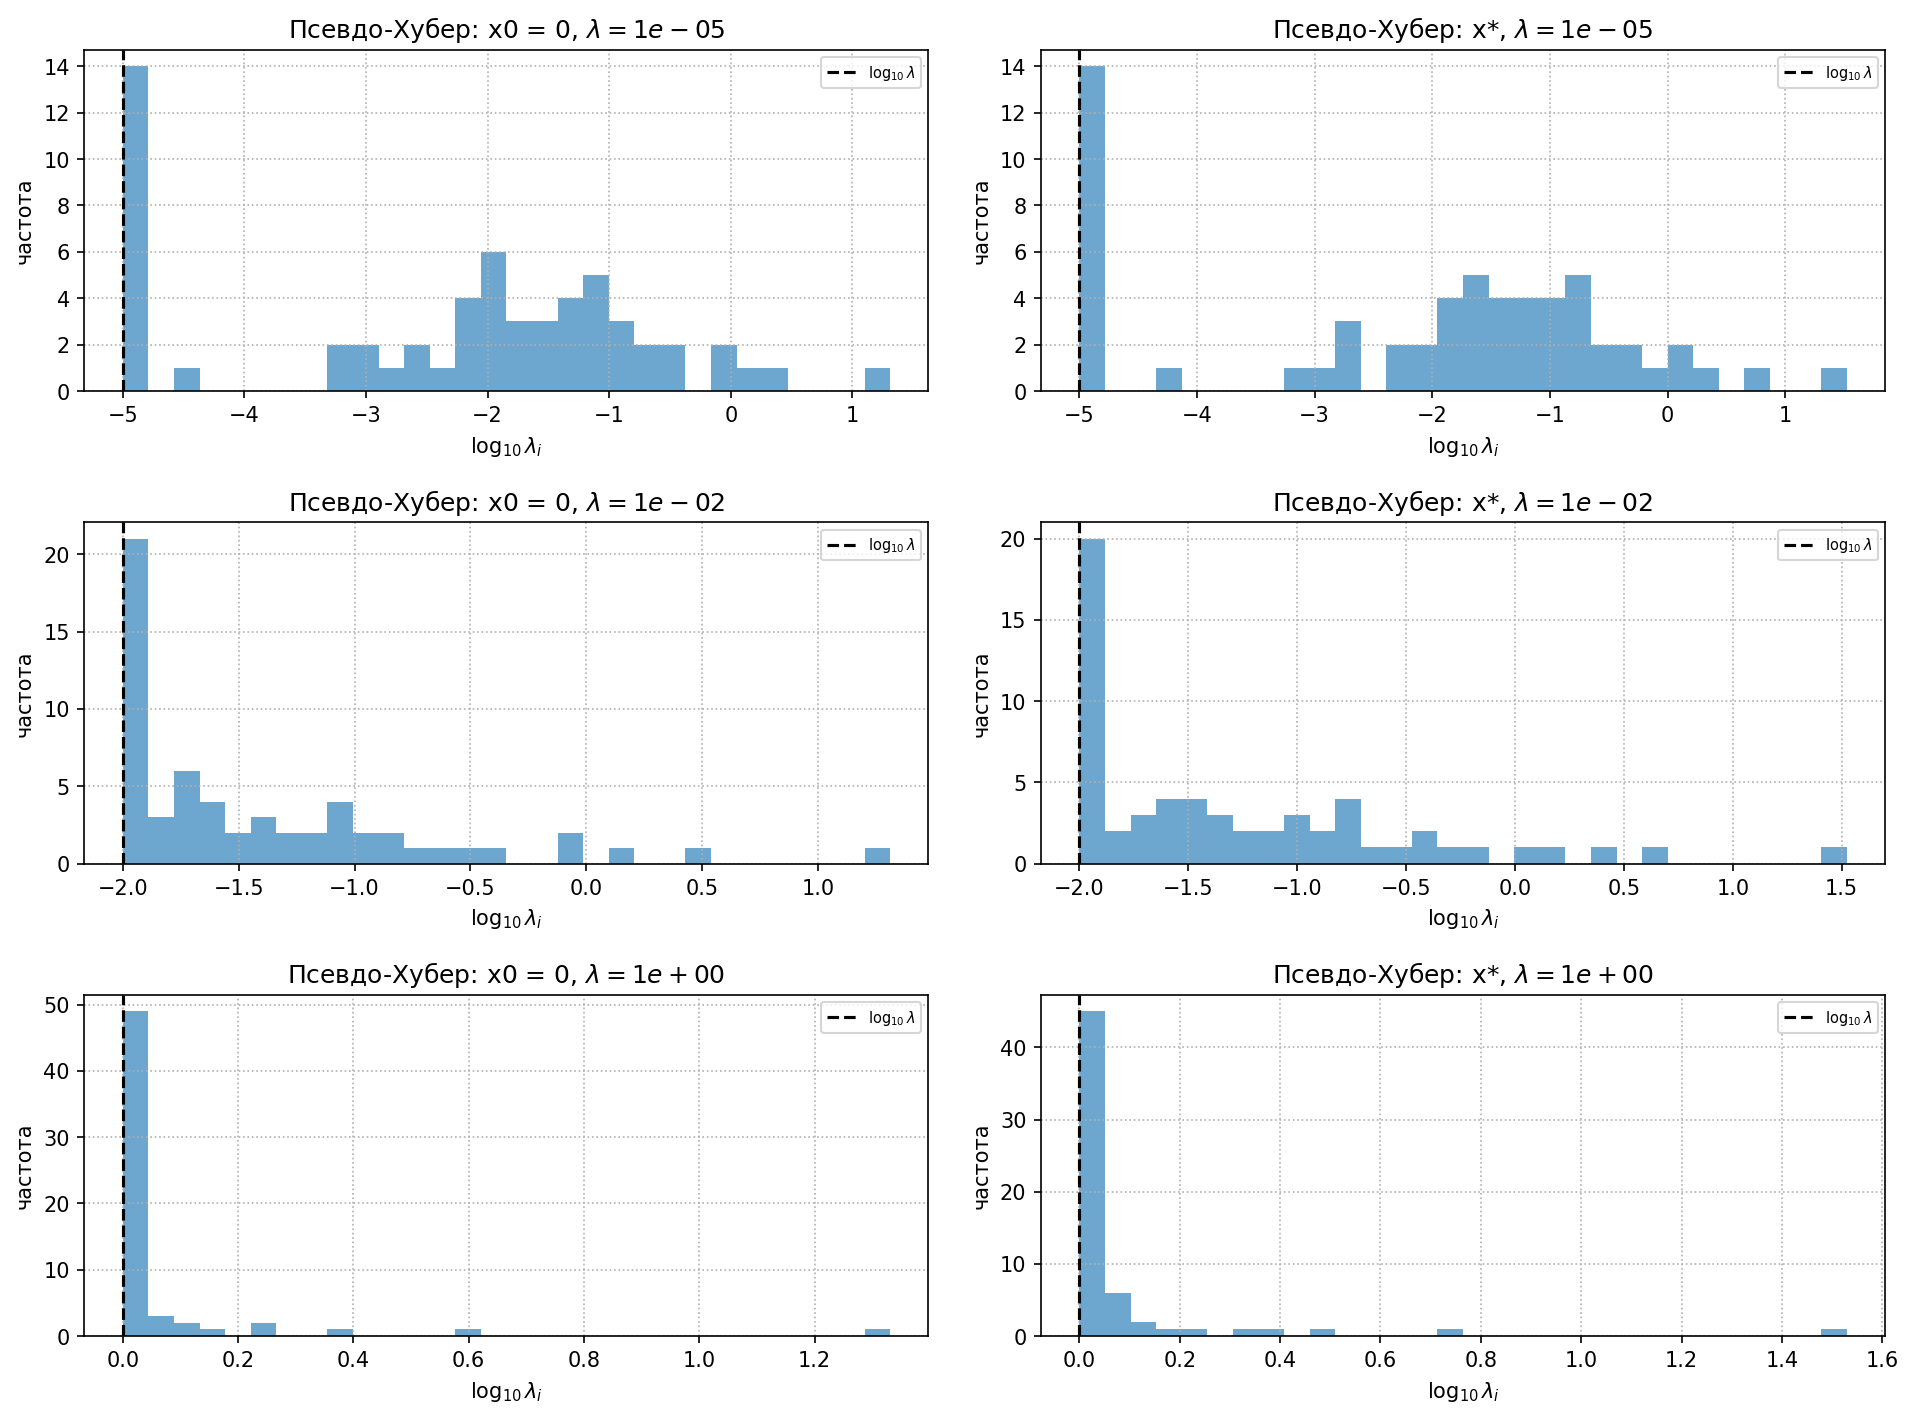

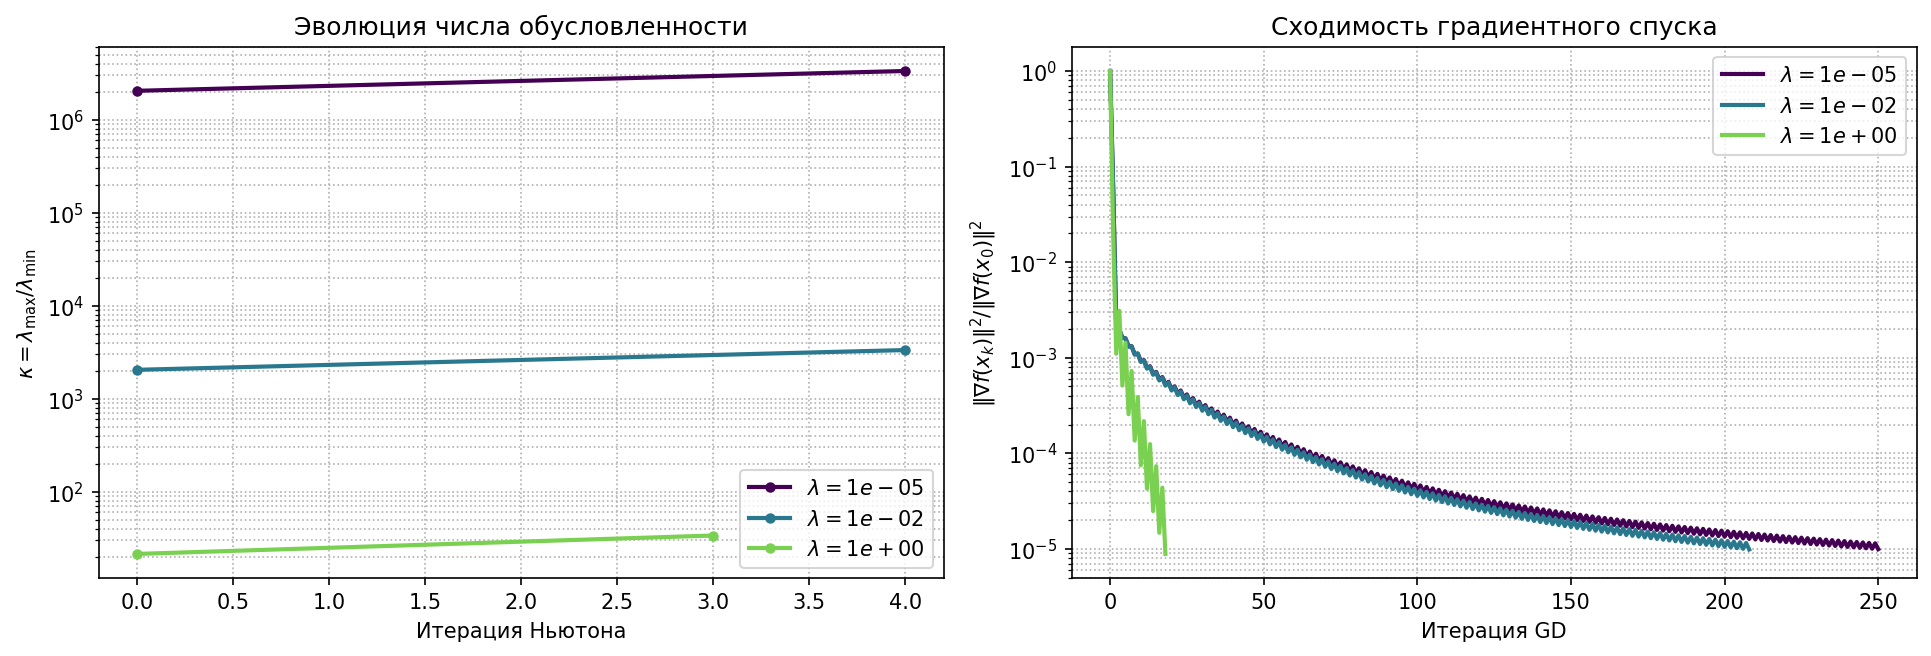

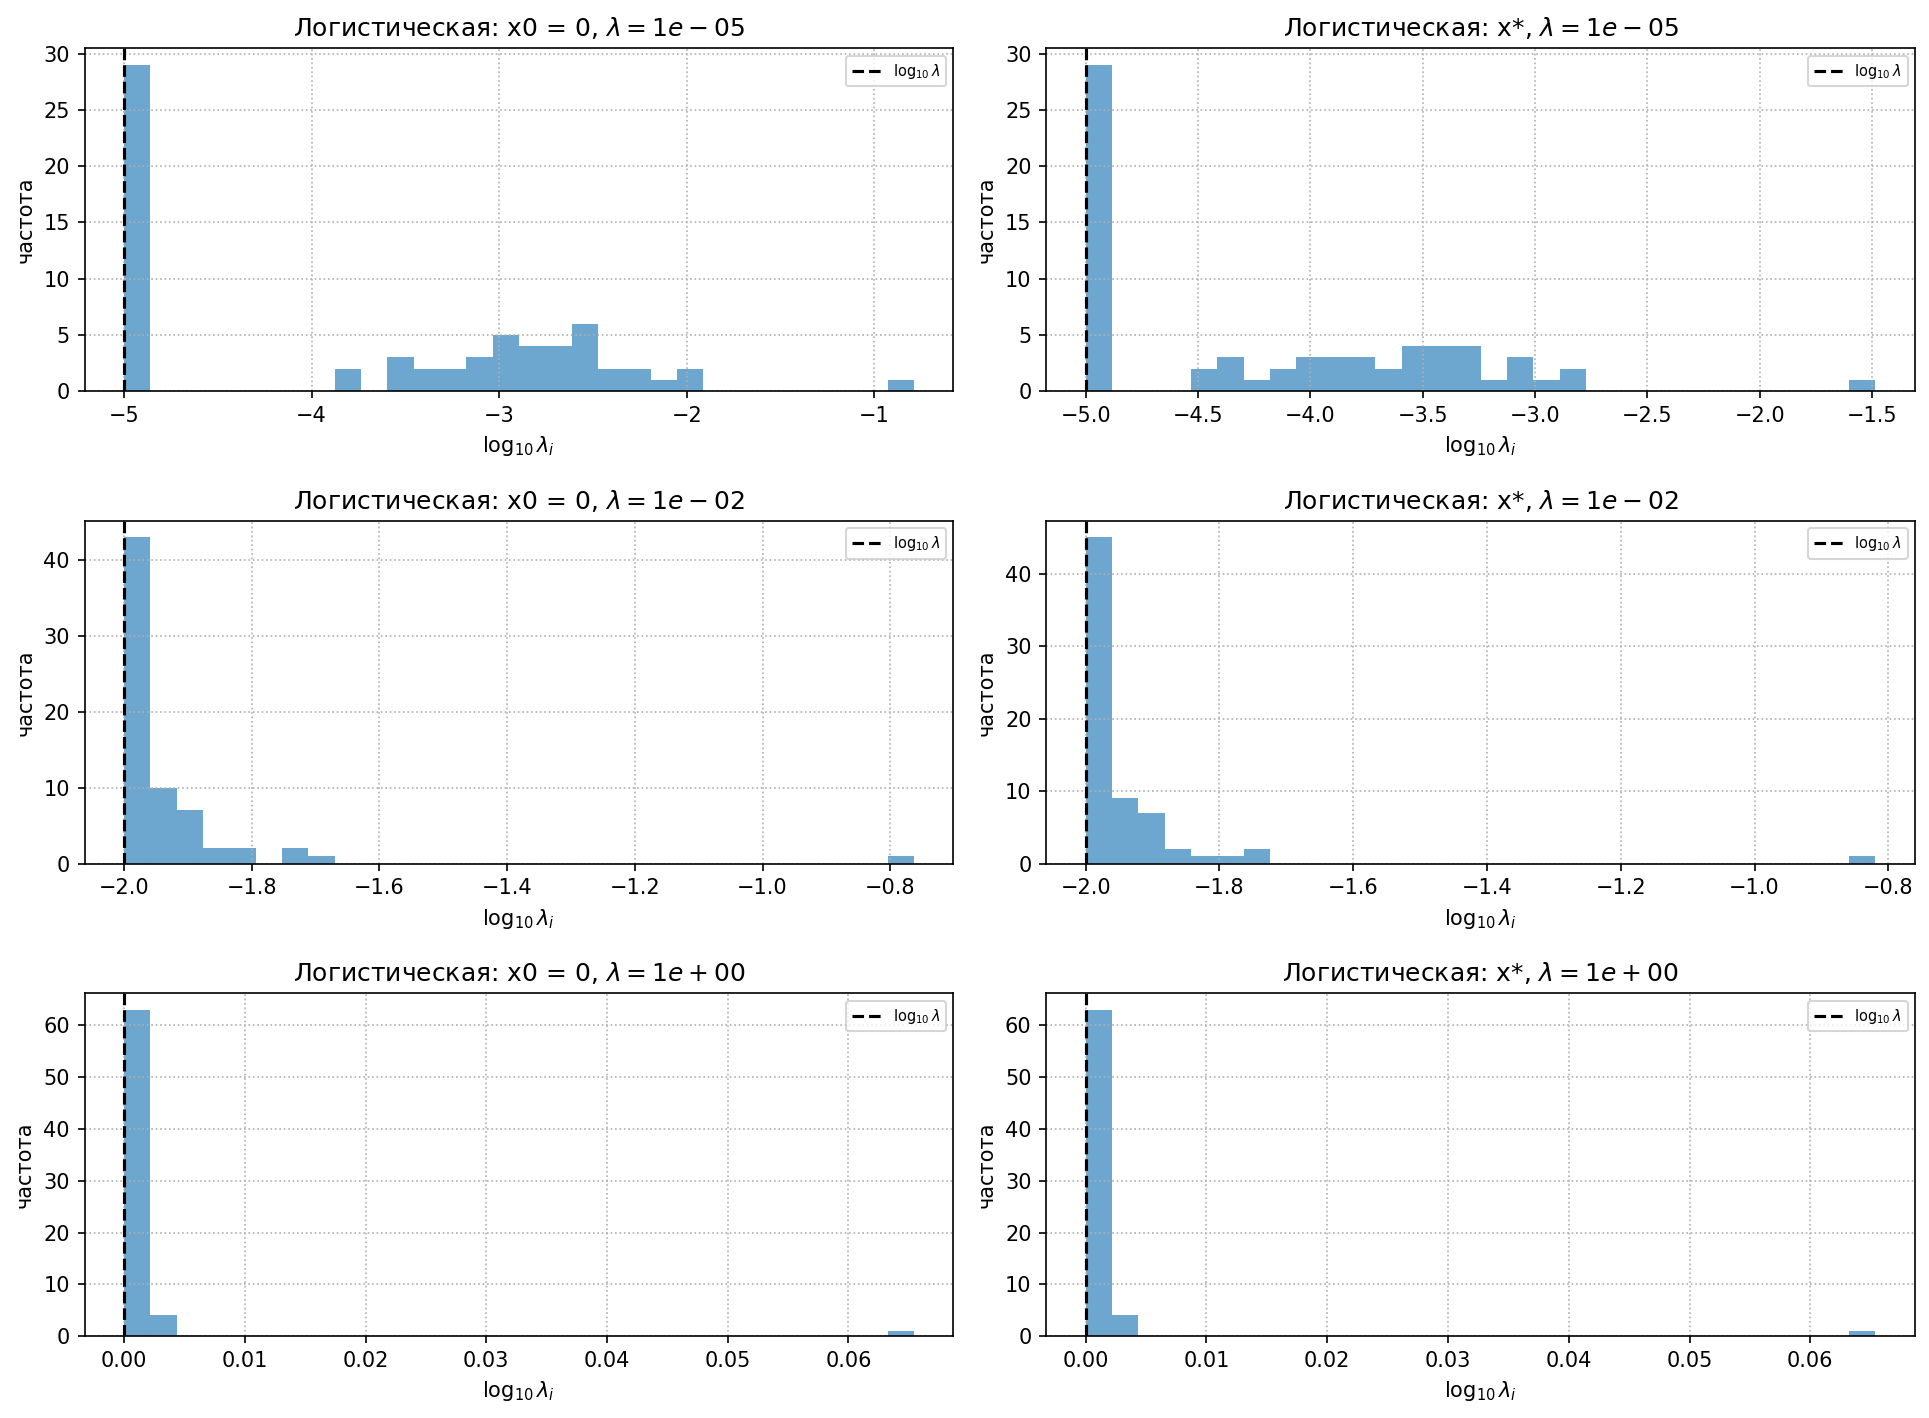

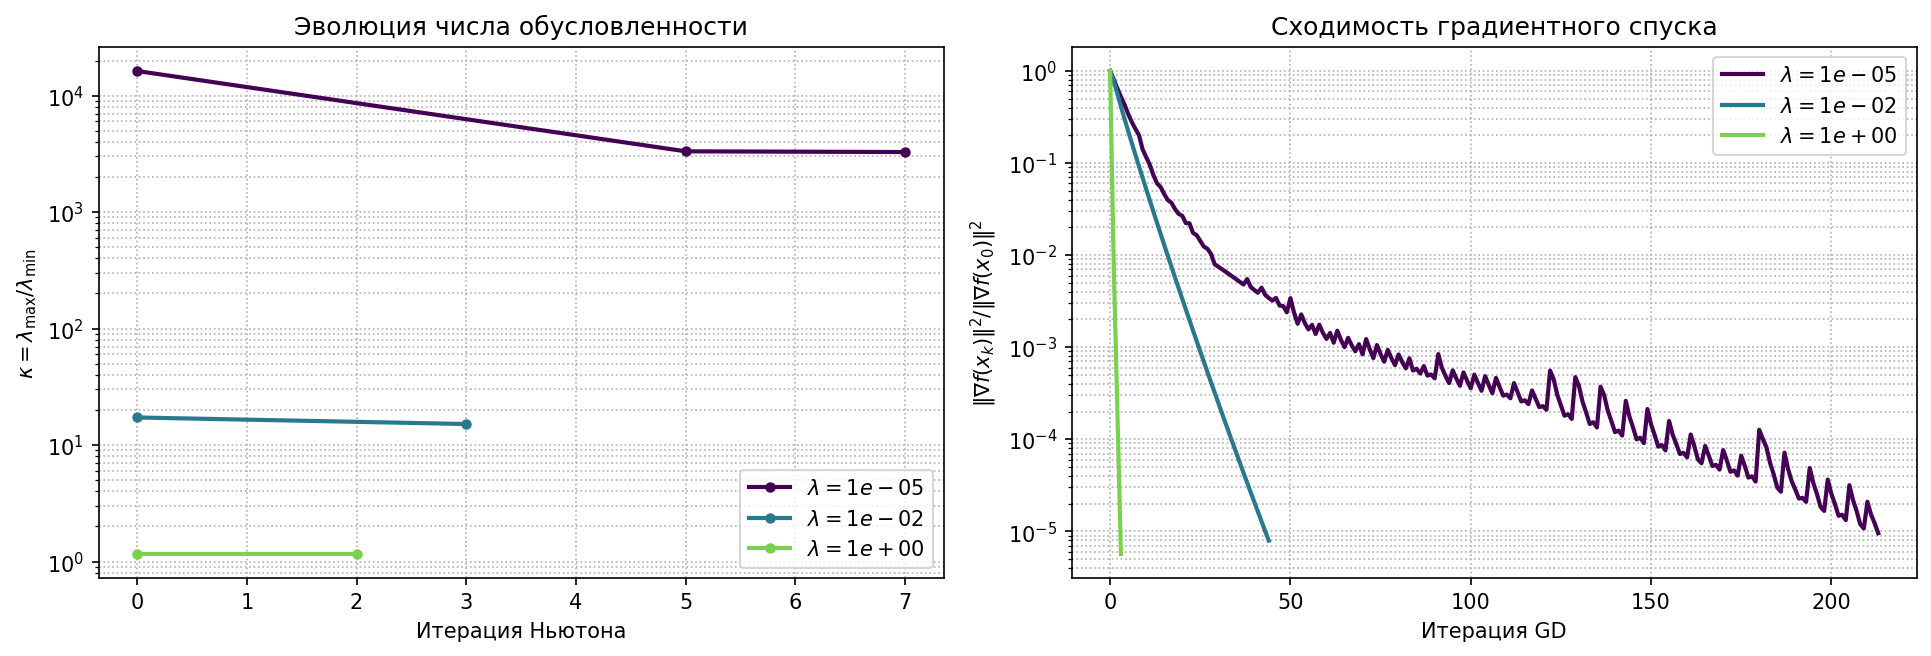

In [18]:
def exp7(max_iter_gd=1500, max_iter_newton=50,
             tol_newton=1e-10, tol_gd=1e-5):
    configs = [
        ('pseudohuber', 'triazines_scale', False, 'regression'),
        ('logistic', 'phishing', False, 'classification'),
    ]
    lambdas = [1e-5, 1e-2, 1.0]
    rows = []
    for loss_name, data_name, scale, task in configs:
        A, b = load_data(data_name, scale=scale)
        if task == 'classification':
            b = to_pm1(b)
        m, n = A.shape
        info = []
        for lam in lambdas:
            oracle = create_linear_model_oracle(A, b, lam, loss_name)
            x0 = np.zeros(n)
            eig0 = scipy.linalg.eigvalsh(oracle.hess(x0))
            spec = SpecOracle(oracle)
            x_star, msg, h = newton(spec, x0, tolerance=tol_newton,
                                    max_iter=max_iter_newton, trace=True)
            eig_star = scipy.linalg.eigvalsh(oracle.hess(x_star))
            spectra = spec.spectra + [eig_star]
            kappa = [ev[-1] / ev[0] for ev in spectra]
            kappa_iters = spec.iters + [len(h['func']) - 1]
            _, msg_gd, h_gd = gradient_descent(
                oracle, x0, tolerance=tol_gd, max_iter=max_iter_gd, trace=True)
            gn_gd = np.asarray(h_gd['grad_norm'])
            gn_gd = gn_gd ** 2 / gn_gd[0] ** 2
            info.append(dict(lam=lam, msg=msg, nit=len(h['func']) - 1,
                             kappa=kappa, kappa_iters=kappa_iters,
                             eig0=eig0, eig_star=eig_star,
                             gd_msg=msg_gd, gd_iter=len(h_gd['func']) - 1,
                             gd_gn=gn_gd))
            rows.append([loss_name, data_name.replace('.bz2', ''), lam, msg,
                         len(h['func']) - 1, kappa[0], kappa[-1],
                         len(h_gd['func']) - 1, gn_gd[-1]])

        fig, axes = plt.subplots(len(lambdas), 2, figsize=(13, 3.2 * len(lambdas)))
        for row, rec in enumerate(info):
            for col, (eig, title) in enumerate([
                    (rec['eig0'], 'x0 = 0'),
                    (rec['eig_star'], 'x*')]):
                ax = axes[row, col]
                ax.hist(np.log10(np.maximum(eig, 1e-300)), bins=30, alpha=0.65)
                ax.axvline(np.log10(rec['lam']), color='k', ls='--',
                           label=r'$\log_{10}\lambda$')
                ax.set_xlabel(r'$\log_{10}\lambda_i$')
                ax.set_ylabel('частота')
                ax.set_title('{}: {}, {}'.format(
                    LOSS_RU.get(loss_name, loss_name), title, r'$\lambda={:.0e}$'.format(rec['lam'])))
                ax.grid(True, which='both', ls=':')
                ax.legend(fontsize=7)
        fig.tight_layout()
        savefig('exp7_hist_' + loss_name)
        plt.close(fig)

        fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
        colors = plt.cm.viridis(np.linspace(0.0, 0.8, len(lambdas)))
        for color, rec in zip(colors, info):
            axes[0].semilogy(rec['kappa_iters'], rec['kappa'],
                             '-o', color=color, lw=2, ms=4,
                             label=r'$\lambda={:.0e}$'.format(rec['lam']))
            axes[1].semilogy(np.arange(len(rec['gd_gn'])), rec['gd_gn'],
                             color=color, lw=2,
                             label=r'$\lambda={:.0e}$'.format(rec['lam']))
        axes[0].set_xlabel('Итерация Ньютона')
        axes[0].set_ylabel(r'$\kappa = \lambda_{\max}/\lambda_{\min}$')
        axes[0].set_title('Эволюция числа обусловленности')
        axes[0].grid(True, which='both', ls=':')
        axes[0].legend()
        axes[1].set_xlabel('Итерация GD')
        axes[1].set_ylabel(r'$\|\nabla f(x_k)\|^2/\|\nabla f(x_0)\|^2$')
        axes[1].set_title('Сходимость градиентного спуска')
        axes[1].grid(True, which='both', ls=':')
        axes[1].legend()
        fig.tight_layout()
        savefig('exp7_kappa_' + loss_name)
        plt.close(fig)
    return rows


if 7 in RUN:
    rows_exp7 = exp7()
    import pandas as pd
    display(pd.DataFrame(rows_exp7, columns=['функция потерь', 'датасет', 'lambda', 'сообщение Ньютона',
                                             'итерации Ньютона', 'kappa(x0)', 'kappa(x*)',
                                             'итерации GD', 'GD: относит. градиент']))
else:
    print('Эксперимент 7 пропущен')

При $\lambda>0$: слева появляется группа собственных значений около $\lambda$, а справа большая часть больших значений. У логистической регрессии на phishing при $\lambda=10^{-5}$ эта группа стоит около $10^{-5}$, а основная масса дотягивается до $10^{-1}$, между ними заметный разрыв. Поэтому $\kappa$ в $x_0$ получается порядка $10^4$, а в $x^*$ — порядка $10^3$. Если увеличить $\lambda$ до $10^{-2}$, группа сдвигается вправо, $\kappa$ падает примерно до 15, а при $\lambda=1$ становится почти 1. У Pseudo-Huber на triazines всё грубее: при $10^{-5}$ $\kappa$ в миллионах, при $10^{-2}$ — тысячи, при $\lambda=1$ — десятки. В целом с ростом $\lambda$ спектр сдвигается, разрыв сужается, и $\kappa$ падает — как и ждёшь от добавки $\lambda I$.

В $x^*$ спектр не такой, как в $x_0$. У логистической регрессии часть весов $\sigma(M)\sigma(-M)$ при больших отступах становится маленькой, поэтому маленькие собственные значения могут стать ещё меньше; у Pseudo-Huber это выражено мягче. На графиках эволюции $\kappa$ у логистической регрессии при $10^{-5}$ падает с десятков тысяч до нескольких тысяч, а у Pseudo-Huber при том же $\lambda$ медленно растёт. При больших $\lambda$ $\kappa$ почти не меняется. А вот Ньютон при этом всё равно сходится за несколько итераций.

Со скоростью GD картинка сходится: логистическая регрессия при $\lambda=10^{-5}$ делает около 200 итераций, при $10^{-2}$ — около 40, при $\lambda=1$ — 3 при этом Pseudo-Huber — около 250, 200 и 20. Это похоже на $T_{GD}=O(\kappa\log(1/\varepsilon))$ видимо потому, что регуляризация улучшает обусловленность, но минимум при этом смещается. У Pseudo-Huber разница по итерациям между $10^{-5}$ и $10^{-2}$ гораздо меньше, чем по $\kappa$, так как Армихо подстраивает шаг, так что оценка через $\kappa$ даёт только порядок роста.


## ДОПОЛНИТЕЛЬНО: Разностная проверка градиента и гессиана

Правильность градиента проверяется конечными разностями:
$$[\nabla f(x)]_i \approx \frac{f(x + \varepsilon_1 e_i) - f(x)}{\varepsilon_1}, \qquad \varepsilon_1 \sim \sqrt{\varepsilon_{\text{mach}}},$$
где $e_i$ — $i$-й базисный орт, а $\varepsilon_{\text{mach}} \approx 10^{-16}$ — машинная точность для `float64`. Для вторых производных:
$$[\nabla^2 f(x)]_{ij} \approx \frac{f(x + \varepsilon_2 e_i + \varepsilon_2 e_j) - f(x + \varepsilon_2 e_i) - f(x + \varepsilon_2 e_j) + f(x)}{\varepsilon_2^2}, \qquad \varepsilon_2 \sim \sqrt[3]{\varepsilon_{\text{mach}}}.$$

Реализуйте функции ниже (здесь циклы допустимы). Затем сгенерируйте небольшую модельную выборку ($A$, $b$) и сравните `grad` и `hess` **всех ваших оракулов** (две функции потерь, плотная и разреженная $A$, а также 2D-функция) с разностными аппроксимациями в нескольких случайных точках $x$. В отчёте приведите таблицу с максимальными отклонениями.

### Разностная проверка градиента и гессиана

Функции `grad_finite_diff` и `hess_finite_diff` реализованы в разделе 2.5 (ячейка с `run_checks`). Там же приведена таблица максимальных отклонений для Pseudo-Huber, Logistic (плотная и разреженная $A$) и функции Розенброка. Повторно дублировать код здесь не будем.


### Точность вычислений: float32 против float64

В машинном обучении ради скорости часто используют одинарную точность (`float32`), а классическая оптимизация строится на двойной (`float64`).

**Задание.**
1. Приведите $A$, $b$ (и все промежуточные векторы) к типу `np.float32`. Запустите градиентный спуск и метод Ньютона до стагнации нормы градиента (установите очень малый `tolerance`). Повторите для `np.float64`. Проверьте, что вычисления действительно идут в `float32`: тип легко «утекает» в `float64`, например через Python-скаляры или `scipy`.
2. Профилируйте время каждой итерации по трём компонентам: (а) вызов оракула (градиент и гессиан), (б) линейный поиск, (в) решение линейной системы (разложение Холецкого).

Постройте график нормы градиента (в логарифмической шкале) от номера итерации для обеих точностей и найдите момент, когда ошибка округления начинает доминировать над шагом метода. Какой точности оптимизации способен достичь каждый метод в `float32` и в `float64`? Постройте столбчатые диаграммы долей времени по трём компонентам. Есть ли реальный выигрыш во времени от перехода на `float32`? Где именно numpy/scipy ускоряются, а где время не меняется? Объясните через устройство BLAS/LAPACK и кэша процессора.

### Диагональное предобуславливание

Итерация градиентного спуска стоит дёшево, но он страдает от плохой обусловленности. Метод Ньютона решает эту проблему за счёт полного учёта кривизны, но требует $O(n^3)$ на разложение Холецкого. Компромисс — учитывать только диагональ гессиана.

**Задание.**
1. Реализуйте модифицированный градиентный спуск $x_{k+1} = x_k - \alpha_k\, [\mathrm{Diag}(\nabla^2 f(x_k))]^{-1} \nabla f(x_k)$. Диагональ гессиана вычисляйте за $O(\mathrm{nnz}(A))$, не формируя полную матрицу.
2. Протестируйте метод на ML-оракулах с линейным поиском по Армихо.

Сравните его с обычным градиентным спуском и полным методом Ньютона. Постройте графики «относительная невязка от времени работы» на «широком» датасете. Насколько учёт только диагональной кривизны сокращает число итераций? Насколько итерация дешевле, чем у полного Ньютона? В каких случаях диагональное предобуславливание бесполезно?


### Дополнительные блоки

Блоки «float32 против float64» и «диагональное предобуславливание» в выбранный объём не входят и в этой работе не выполнялись. Основная часть (пункты 1–7) и проверки реализованы полностью.
